# Detector de voz gerada por IA: documento da v7

> **Sistema atual: v7 (T3).** **Sistema anterior: v4 (F0).** Os dois usam o mesmo caminho: um modelo de fala pronto e congelado (o XLS-R, da Meta) transforma cada áudio em números, e uma **regressão logística** treinada por nós dá uma **nota**; acima de um **corte**, a voz é chamada de gerada por IA. O que mudou na v7 foi **com que dados** a regressão é treinada.

## 1. Introdução

**Objetivo.** Dizer se uma voz foi gerada por IA. O treino começou só em inglês de estúdio e audiolivro; os testes incluem vozes de internet, fakes parciais e português.

**Resultados em 5 linhas** (todos lidos de `results/`; detalhes nas seções 10 a 16):
1. O sistema anterior, **v4 (F0)**, ia muito bem no estúdio (validação: AUC 0,998) e no banco de internet mais fácil (entrevistas e discursos, In-the-Wild: 0,979), mas **caiu nos dois bancos externos novos**: AUC **0,721** em IA comercial moderna em canal degradado (RADAR) e **0,689** em vídeos reais de redes sociais (ML-ITW).
2. Na v7, treinamos com **parte** desses dois bancos, separada **por locutor** (ML-ITW) e **por idioma** (RADAR, que não informa o locutor), e mantivemos um **teste mestre fixo**, igual para todas as receitas de treino.
3. Entre 5 receitas (T0 a T4), a **T3** (estúdio + internet real + IA moderna em canal degradado) foi escolhida pela **validação** (AUC média por fonte 0,975), gravada antes de abrir o teste.
4. No teste mestre, a AUC média (3 fontes) foi de **0,76 (T0 = F0)** para **0,96 (T3)** (0,764 → 0,963; diferença +0,200, IC95 +0,168 a +0,232), **sem piorar o estúdio** (maior queda de AUC nos controles: −0,003).
5. **Ressalvas principais:** o teste mestre **não é virgem** (o F0 já tinha sido medido nesses clipes); no RADAR, o idioma do teste é novo, mas **geradores e canal são os do treino** (não é "gerador novo"); internet real em inglês (18 / 26 locutores) e em português (7 / 8) é **indício**, não estimativa; **o corte não se transfere entre ambientes** (no português de audiolivro, 75% dos reais são acusados); nada aqui fala de ligações reais.

**Como ler.** As seções 2 a 9 explicam o caminho e o **sistema anterior (v4 = F0)**, que continua valendo para tudo o que não mudou (pipeline, camadas, regressão). As seções 10 a 16 são a **v7**. Antes de cada figura, um parágrafo diz **o que ela mostra**; depois, **o que olhar** e **o que concluir**. Este notebook **só lê** arquivos já gravados: não treina, não extrai e não consulta teste nenhum (`AVALIAR_TESTE_FINAL = False`). As figuras estão em alta resolução em `results/slides/` (lista em `results/slides/INDEX.md`). Tudo o que não foi ensinado na trilha está marcado com "⚠️ Fora da trilha".

### Glossário em linguagem simples

As mesmas palavras são usadas em todas as figuras e explicações.

| palavra | o que quer dizer |
|:--|:--|
| **Real** / **gerada por IA** | voz humana gravada / voz criada ou modificada por um gerador de IA (nos arquivos, "fake" = gerada por IA) |
| **Mono** | um único canal de áudio (o estéreo tem dois). Todos os nossos áudios já são mono. |
| **Taxa de amostragem** | quantas medidas do som o arquivo guarda por segundo. 16 kHz = 16.000 medidas por segundo, o que registra sons até 8 kHz. Se os reais e os gerados por IA de um banco têm taxas diferentes, o modelo pode "acertar" só pelo formato do arquivo; por isso padronizamos tudo em 16 kHz. |
| **Log-mel** | uma imagem do som (tempo × frequência), com as frequências agrupadas em 64 faixas que imitam o ouvido e o brilho em escala logarítmica (figura 02). Era a entrada da CNN das versões 1 a 3. |
| **Convolução** / **pooling** | convolução: um filtro pequeno que desliza pela imagem procurando um padrão local. Pooling: reduz a imagem guardando o maior valor de cada pedacinho, o que dá tolerância a pequenos deslocamentos. |
| **XLS-R** | um modelo de fala pronto (da Meta), treinado sem rótulos em fala de 128 línguas. Usamos congelado: ele só transforma o áudio em números. |
| **Camada** | o XLS-R tem 24 camadas empilhadas; cada uma devolve um vetor de 1.024 números a cada 20 ms. A camada 0 é a entrada, a 24 é a última. |
| **Nota** e **corte** (limiar) | a regressão dá uma nota a cada áudio (quanto maior, mais parece IA); acima do corte, chamamos de IA. **Corte A** (calibrado no estúdio) = o ponto em que "reais acusados" e "gerados por IA que passam" têm a mesma taxa, na validação. **Corte B** (calibrado na internet) = o mesmo ponto, no dev_shift. |
| **AUC** | a chance de um áudio gerado por IA, sorteado do mesmo banco, receber nota mais alta que um real sorteado. 1 = sempre; **0,5 = cara ou coroa**; **abaixo de 0,5 = o modelo erra de forma sistemática** (dá nota de IA mais alta aos reais). Não depende do corte. |
| **EER** (taxa de erro igual) | o erro no corte em que "reais acusados" e "gerados por IA que passam" têm a mesma taxa; quanto menor, melhor. |
| **Acurácia** / **acurácia balanceada** | acurácia: % de acertos. Balanceada: a média do acerto nos reais e do acerto nos gerados por IA. Em banco desbalanceado, a acurácia sozinha engana: no dev_shift (81% real), chamar tudo de real já acerta 81% (o **chute da classe comum**). |
| **Validação** | áudios dos mesmos bancos do treino, mas de **outros locutores**; escolhe camada, C e o corte A. É o "estúdio". |
| **dev_shift** | 10.614 áudios do In-the-Wild (figuras públicas, reais e falsos coletados na internet) de 16 locutores, separados por pessoa; usado só para comparar versões e escolher o corte B. Os outros 38 locutores ficaram no teste. "shift" = a mudança do estúdio para a internet. |
| **Teste** | bancos que nunca entram no treino nem em escolha nenhuma; avaliados uma vez por versão. |
| **Fonte** | cada banco de origem dos áudios (DFADD, ShiftySpeech...). |
| **Falso parcial** | áudio com trechos gerados por IA dentro de uma fala real (LlamaPartialSpoof). |
| **Peso igual por fonte** | cada fonte conta o mesmo no treino da regressão, para a maior não dominar (testado na v6). Na v7, é a receita **T4**: o estúdio, a internet real e o RADAR somam o mesmo peso (e, dentro de cada um, reais e IA também). |
| **Funil** (v6) | etapas em sequência; cada uma compara opções e só a vencedora passa para a próxima. |
| **C** | o "freio" da regularização da regressão: **C pequeno = freio forte** = pesos pequenos = regressão mais simples. || **Sistema atual / anterior** | **atual = v7 (T3)**; **anterior = v4 (F0)**. Mesmo pipeline e mesma regressão; muda o treino. |
| **Receita** (T0 a T4) | uma "receita de treino": quais dados entram no treino da regressão. **T0** = o F0 sem retreinar; **T1** = estúdio + internet real (ML-ITW); **T2** = estúdio + IA moderna em canal degradado (RADAR); **T3** = estúdio + os dois; **T4** = T3 com peso igual por fonte. |
| **Teste mestre fixo** | um conjunto de teste escolhido **antes** do treino e **igual para todas as receitas**, para que a comparação seja justa: muda a receita, o teste fica parado. Foi avaliado uma vez por receita. |
| **Visto × não visto no treino** | "visto" = a receita treinou com aquele **tipo** de áudio (por exemplo, outros locutores do mesmo banco, ou outro idioma da mesma fonte); "não visto" = nada daquele banco entrou no treino. Um bom resultado em algo visto vale menos como prova de generalização. |
| **Vazamento** | quando algo do teste "vaza" para o treino ou para as escolhas, e o número do teste fica otimista. Exemplo: **a mesma pessoa** nos dois lados. O modelo pode aprender a reconhecer a **voz da pessoa** (ou o microfone dela) em vez de "real × IA", e acertar no teste por isso. |
| **Locutor atômico** | todo o áudio de um locutor fica **do mesmo lado** (treino, validação ou teste); nunca se divide uma pessoa. |
| **Bloco inglês** | o recorte "só inglês" do teste (RADAR en, internet real em inglês, In-the-Wild e controles de estúdio), para separar o efeito do idioma do efeito do tipo de áudio. |
| **Controle de esquecimento** | os testes antigos de estúdio (LlamaPartialSpoof, ASVspoof, BRSpeech-DF, CORAA): servem para ver se aprender a internet fez o sistema **piorar** onde ele já ia bem. |
| **Calibração do corte** | se a mesma nota quer dizer a mesma coisa em todo lugar. Não quer: a **escala da nota muda entre ambientes** (estúdio, internet, português), e um corte que acusa 6% dos reais num banco pode acusar 75% em outro. |
| **TPR / FPR** | TPR = % dos áudios de IA detectados; FPR = % dos reais acusados como IA (o falso alarme). |
| **IC95** | intervalo de confiança de 95% por bootstrap (sorteios com reposição). No RADAR, que não tem locutor, o IC é por clipe e por isso **otimista** (estreito demais). |

## 2. Configuração

**O que faz:** a célula abaixo (tag `config`) é **a configuração da v4** (o pipeline e as camadas não mudaram na v7), mais um bloco curto que diz onde este documento lê os valores do sistema anterior (F0) e do atual (T3). Só os comentários que citavam o equipamento foram trocados por descrições neutras (o código é o mesmo, conferido pelo script que monta o notebook). **Por quê:** o F0 é a v4; os scripts da v4 (`scripts/v4.py`, `scripts/v4_teste.py`) executam esta célula para saber os hiperparâmetros, então ela tem de continuar sendo a da v4. `AVALIAR_TESTE_FINAL = False`: nada aqui consulta o teste.

In [1]:
import json
import os
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd

from src.analysis import FAIXAS_DURACAO, faixa_duracao
from src.metrics import eer_e_limiar, eer_media_por_fonte, metricas_completas

# ---------------- execução ----------------
QUICK = False                # True: teste rápido de ponta a ponta (~300 clipes, arquivos _quick)
QUICK = globals().get("QUICK_DO_SCRIPT", QUICK or os.environ.get("V4_QUICK") == "1")  # --quick / V4_QUICK=1
AVALIAR_TESTE_FINAL = False  # False: NADA do teste final é consultado nesta versão
VERSAO = "v4"

# ---------------- herdados (sem mudança) ----------------
SEED = 42                    # seed dos DADOS (amostras e sorteio dos shards de treino)
SAMPLE_RATE = 16_000
NUM_WORKERS = 4              # leitura de áudio; sobrescrito por V4_NUM_WORKERS (não muda o método)

# ---------------- modelo congelado (Parte C) ----------------
MODELO_SSL = "facebook/wav2vec2-xls-r-300m"
DTYPE = "float16"            # metade da memória e ~2x mais rápido; lote com NaN é refeito em bfloat16

# ---------------- pré-processamento (Parte D) ----------------
TOP_DB = 35.0                # corte do silêncio: quadros 35 dB abaixo do mais forte
MIN_S = 0.5                  # se o corte deixar menos que isso, usa o áudio sem corte
MAX_S = 8.0                  # recorte central de no máximo 8 s (sem completar)

# ---------------- extração (Parte D) ----------------
ORCAMENTO_H = 4.0            # orçamento CUMULATIVO de extração (results/v4_estado.json)
TAM_SHARD = 2000             # clipes por shard (~1 min de extração cada)
VAL_MAX = 20_000             # subamostra da validação
VAL_FONTE_PEQUENA = 5_000    # fontes com até isso entram inteiras (CodecFake+ e ShiftySpeech)
DEV_MAX = None               # None = dev_shift inteiro
TREINO_MAX_SHARDS = 20       # 40.000 clipes (20.000 reais + 20.000 fakes): o teto por fonte ainda vale
SEMCORTE = dict(treino_shards=5, val=5_000, dev_shift=None)   # ablação do corte: mesmos áudios, sem cortar
MAX_AMOSTRAS_LOTE = 32 * 128_000   # lote do modelo: até 32 clipes de 8 s (pico ~4 GB)
MAX_CLIPES_LOTE = 64
BALDE_S = 2                  # lotes do modelo com formato fixo: 2, 4, 6 ou 8 s (memória; ver src/extracao_v4.py)
VAZAO_ESTIMADA = 44.0        # clipes/s medidos (500 clipes, 4 workers); só vale até a execução medir a sua

# ---------------- cabeças (Parte E) ----------------
GRADE_C = [1e-3, 1e-2, 1e-1, 1.0]   # regularização da regressão logística (C pequeno = mais regularizada)
RL_MAX_ITER = 1000
TOP_K_CONCAT = (3, 4)        # concatenação das 3 e das 4 melhores camadas (pela validação)
SEEDS_CABECA = (42, 123, 2026)
SOMA_LR, SOMA_WD = 1e-3, 1e-3
SOMA_MAX_EPOCAS, SOMA_PACIENCIA = 30, 5
SOMA_BATCH = 256
SOMA_BLOCO = 8192            # linhas lidas do disco de cada vez (~420 MB em float16)
SOMA_OCULTA = 256            # neurônios da camada escondida do MLP
SOMA_DROPOUT = 0.3           # o mesmo dropout da CNN das versões anteriores

if QUICK:
    TAM_SHARD, VAL_MAX, VAL_FONTE_PEQUENA, DEV_MAX, TREINO_MAX_SHARDS = 50, 100, 0, 100, 2
    SEMCORTE = dict(treino_shards=1, val=50, dev_shift=50)
    ORCAMENTO_H = 0.5
    GRADE_C = [1e-2, 1.0]
    SOMA_MAX_EPOCAS, SOMA_PACIENCIA, SOMA_BLOCO = 3, 2, 64

HP = dict(SEED=SEED, SAMPLE_RATE=SAMPLE_RATE, NUM_WORKERS=NUM_WORKERS, MODELO_SSL=MODELO_SSL, DTYPE=DTYPE,
          TOP_DB=TOP_DB, MIN_S=MIN_S, MAX_S=MAX_S, ORCAMENTO_H=ORCAMENTO_H, TAM_SHARD=TAM_SHARD,
          VAL_MAX=VAL_MAX, VAL_FONTE_PEQUENA=VAL_FONTE_PEQUENA, DEV_MAX=DEV_MAX,
          TREINO_MAX_SHARDS=TREINO_MAX_SHARDS, SEMCORTE=SEMCORTE, MAX_AMOSTRAS_LOTE=MAX_AMOSTRAS_LOTE,
          MAX_CLIPES_LOTE=MAX_CLIPES_LOTE, BALDE_S=BALDE_S, VAZAO_ESTIMADA=VAZAO_ESTIMADA, GRADE_C=GRADE_C,
          RL_MAX_ITER=RL_MAX_ITER, TOP_K_CONCAT=TOP_K_CONCAT, SEEDS_CABECA=SEEDS_CABECA, SOMA_LR=SOMA_LR,
          SOMA_WD=SOMA_WD, SOMA_MAX_EPOCAS=SOMA_MAX_EPOCAS, SOMA_PACIENCIA=SOMA_PACIENCIA,
          SOMA_BATCH=SOMA_BATCH, SOMA_BLOCO=SOMA_BLOCO, SOMA_OCULTA=SOMA_OCULTA, SOMA_DROPOUT=SOMA_DROPOUT)
# o que define o MÉTODO da extração (se mudar, o cache antigo não serve: o script para sem apagar nada)
CFG_EXTRACAO = dict(modelo=MODELO_SSL, dtype=DTYPE, top_db=TOP_DB, min_s=MIN_S, max_s=MAX_S, sr=SAMPLE_RATE,
                    resumo="média e desvio no tempo das 25 saídas, só quadros válidos")

# ---------------- arquivos (QUICK separado dos oficiais) ----------------
SUFIXO = ("_quick" + os.environ.get("V4_SUFIXO_EXTRA", "")) if QUICK else ""   # extra: só testes do QUICK
CACHE_DIR = Path("data/processed") / f"v4_cache{SUFIXO}"     # fora do git (data/**)
RESULTS_DIR, MODELS_DIR, LOGS_DIR = Path("results"), Path("models"), Path("logs")
ETAPAS = ("extracao", "camadas", "somas", "atalhos", "resumo")
ARQ_ESTADO = RESULTS_DIR / f"v4_estado{SUFIXO}.json"          # orçamento cumulativo de extração
ARQ_CONCLUIDO = RESULTS_DIR / f"v4_concluido{SUFIXO}.json"    # gravado por último


def arq_result(nome, ext):
    return RESULTS_DIR / f"v4_{nome}{SUFIXO}.{ext}"


def marcador(etapa):
    return RESULTS_DIR / f"v4_{etapa}_concluido{SUFIXO}.json"


print(f"QUICK = {QUICK} | AVALIAR_TESTE_FINAL = {AVALIAR_TESTE_FINAL} | modelo {MODELO_SSL} ({DTYPE})")
print(f"cache: {CACHE_DIR} | orçamento de extração: {ORCAMENTO_H} h | treino: até {TREINO_MAX_SHARDS} shards "
      f"de {TAM_SHARD} | validação até {VAL_MAX} | dev_shift {'inteiro' if DEV_MAX is None else DEV_MAX}")

# ---------------- documento da v7: sistema atual = v7 (T3); sistema anterior = v4 (F0) ----------------
# Nada abaixo muda o método: só diz de onde o notebook lê. Camadas, C, receitas e cortes são LIDOS de results/
# (gravados pela v4 e pela v7), não digitados aqui. Protocolo da v7: docs/PROTOCOLO_V7.md.
DOCUMENTO = "v7 (T3)"
SISTEMA_ATUAL = "v7 (T3)"
SISTEMA_ANTERIOR = "v4 (F0)"
F0_CABECA = "concat_top3"                       # a cabeça final escolhida pela validação na v4 (camadas 5, 6, 7)
ARQ_F0 = RESULTS_DIR / "v4final_resumo.json"    # valores confirmados do F0 (scripts/v4final_figuras.py)
ARQ_T3 = RESULTS_DIR / "v7_t3_modelo.json"      # hiperparâmetros e conferência da T3 (scripts/v7_t3_exportar.py)
SPLITS_V7 = "data/processed/splits_v7.parquet"  # divisão congelada da v7 (fora do git; SHA256 no protocolo)
print(f"{DOCUMENTO} | anterior: {SISTEMA_ANTERIOR} | AVALIAR_TESTE_FINAL = {AVALIAR_TESTE_FINAL} | lê de {RESULTS_DIR}/")

QUICK = False | AVALIAR_TESTE_FINAL = False | modelo facebook/wav2vec2-xls-r-300m (float16)
cache: data\processed\v4_cache | orçamento de extração: 4.0 h | treino: até 20 shards de 2000 | validação até 20000 | dev_shift inteiro
v7 (T3) | anterior: v4 (F0) | AVALIAR_TESTE_FINAL = False | lê de results/


**Os hiperparâmetros que importam para o F0, em uma frase cada** (a tabela de todas as versões está na seção 9):

| hiperparâmetro | valor | por quê |
|:--|:--|:--|
| `MODELO_SSL` | `facebook/wav2vec2-xls-r-300m` | modelo pronto de fala, multilíngue (128 línguas), usado congelado (transfer learning, Aula 10) |
| `DTYPE` | float16 | metade da memória; a v5 mediu erro de ~0,06% contra float32 |
| `TOP_DB`, `MIN_S`, `MAX_S` | 35 dB, 0,5 s, 8 s | corta o silêncio das bordas (se sobrar menos de 0,5 s, não corta) e usa no máximo 8 s do meio, sem completar |
| `TREINO_MAX_SHARDS` × `TAM_SHARD` | 20 × 2.000 | 40.000 áudios de treino (metade real, metade IA), com teto por fonte e por gerador |
| `VAL_MAX` | 20.000 | subamostra da validação (19.999 áudios); CodecFake+ e ShiftySpeech entram inteiros |
| `GRADE_C` | 0,001 / 0,01 / 0,1 / 1 | o "freio" da regressão (C pequeno = freio forte); escolhido pela validação |
| `RL_MAX_ITER` | 1.000 | iterações máximas do lbfgs (a cabeça final convergiu em 56) |
| `TOP_K_CONCAT` | 3 e 4 | juntar as 3 ou as 4 melhores camadas (a validação escolheu 3) |
| `AVALIAR_TESTE_FINAL` | False | o teste só é lido dos arquivos gravados pela v4 |

**O que faz:** carrega pequenas funções para mostrar figuras (reduzidas, para o arquivo ficar leve) e tabelas de `results/` e imprime os valores do sistema anterior (F0) e do atual (T3) **confirmados** pelo script das figuras (que reajustou a regressão e conferiu contra as notas gravadas da v4). **Por quê:** os valores vêm do disco, não do texto.

In [2]:
import json
import warnings
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 80)
R = RESULTS_DIR
SLIDES = R / "slides"


def existe(p):
    return Path(p).exists()


def ler(p):
    p = Path(p)
    return json.loads(p.read_text(encoding="utf-8")) if p.exists() else None


def pendente(o_que):
    display(Markdown(f"> **Não encontrei** {o_que} em disco. Rode `python scripts/v4final_figuras.py` "
                     "(precisa dos caches da v4, que ficam fora do git)."))


def figura(nome):
    p = R / f"v4final_{nome}.png"
    if existe(p):
        display(Image(filename=str(p)))
    else:
        pendente(f"a figura `{p}`")


def tabela(nome, arred=3, pasta=None):
    p = (pasta or R) / nome
    if not existe(p):
        pendente(f"a tabela `{p}`")
        return None
    t = pd.read_csv(p)
    display(t.round(arred))


F0 = ler(ARQ_F0)
if F0:
    f = F0["F0"]
    display(Markdown(
        f"**F0 confirmado (lido de `{ARQ_F0}`):** camadas **{f['camadas']}** do XLS-R, média no tempo, "
        f"{f['n_pesos']} números por áudio; regressão logística com **C = {f['C']:g}**, solver {f['solver']}, "
        f"peso das classes: {f['class_weight']}; treinada em {f['n_treino']} áudios. Corte **A** = "
        f"{f['limiar_A_logit']:.4f} (probabilidade {f['limiar_A_prob']:.3f}); corte **B** = "
        f"{f['limiar_B_logit']:.4f} (probabilidade {f['limiar_B_prob']:.4f})."))
else:
    pendente(f"o arquivo `{ARQ_F0}`")
# ---- v7: figuras reduzidas (para o arquivo ficar < 10 MB) e leitura dos resultados da v7
from io import BytesIO

from PIL import Image as _PIL

LARGURA_MAX = 1200          # ~90 dpi numa figura de 13,33 pol.; as versões em alta estão em results/slides/


def _png_reduzido(p):
    im = _PIL.open(p).convert("RGB")
    if im.width > LARGURA_MAX:
        im = im.resize((LARGURA_MAX, round(im.height * LARGURA_MAX / im.width)), _PIL.LANCZOS)
    im = im.quantize(colors=256)
    b = BytesIO()
    im.save(b, format="PNG", optimize=True)
    return b.getvalue()


def figura(nome):
    """Figuras da v4 (results/v4final_*.png), embutidas reduzidas."""
    p = R / f"v4final_{nome}.png"
    if existe(p):
        display(Image(data=_png_reduzido(p)))
    else:
        pendente(f"a figura `{p}`")


def slide(nome):
    """Figuras dos slides (results/slides/*.png), embutidas reduzidas."""
    p = SLIDES / f"{nome}.png"
    if existe(p):
        display(Image(data=_png_reduzido(p)))
    else:
        display(Markdown(f"> **Não encontrei** `{p}`. Rode `python scripts/v7_slides.py`."))


T3 = ler(R / "v7_t3_modelo.json")
if T3:
    rg = T3["regressao"]
    display(Markdown(
        f"**Sistema atual: v7 (T3)** (lido de `results/v7_t3_modelo.json`): o mesmo XLS-R congelado, camadas "
        f"**{T3['camadas']}**, {T3['n_numeros']} números por áudio; regressão logística com **C = {rg['C']:g}**, "
        f"solver {rg['solver']}, peso das classes **{rg['class_weight']}**; treinada em {T3['treino']['n']} áudios "
        f"(estúdio + internet real + IA em canal degradado). Pesos em `results/v7_t3_coeficientes.npz`; conferidos contra "
        f"as notas gravadas da v7 (diferença máxima {T3['conferencia']['dif_max_nota_logit']:.1e})."))

**F0 confirmado (lido de `results\v4final_resumo.json`):** camadas **[5, 6, 7]** do XLS-R, média no tempo, 3072 números por áudio; regressão logística com **C = 0.1**, solver lbfgs (padrão do scikit-learn), peso das classes: nenhum (o treino já é 50/50); treinada em 40000 áudios. Corte **A** = -0.0395 (probabilidade 0.490); corte **B** = 8.2184 (probabilidade 0.9997).

**Sistema atual: v7 (T3)** (lido de `results/v7_t3_modelo.json`): o mesmo XLS-R congelado, camadas **[5, 6, 7]**, 3072 números por áudio; regressão logística com **C = 0.01**, solver lbfgs, peso das classes **balanced**; treinada em 81288 áudios (estúdio + internet real + IA em canal degradado). Pesos em `results/v7_t3_coeficientes.npz`; conferidos contra as notas gravadas da v7 (diferença máxima 1.1e-05).

## 3. Mapa do banco (o banco da v4; o desenho da v7 está na seção 11)

Resumo de `docs/dataset_overview.md` e `docs/audit_report.md` (detalhes lá).

**Por que cada divisão existe:**

| papel | bancos | o que é real, o que é IA | para que serve |
|:--|:--|:--|:--|
| **treino** (260.782 áudios; o sistema usa 40.000) | ASVspoof 2019 (train+dev), DFADD, ShiftySpeech, CodecFake+ (parte CoSG), LibriSpeech train-clean-100 | reais: inglês lido em estúdio (VCTK, via DFADD e ASVspoof) ou em audiolivro (LibriSpeech, ShiftySpeech); IA: geradores antigos (ASVspoof 2019, A01 a A19) e os "geradores novos" (5 TTS do DFADD, 3 vocoders do ShiftySpeech, 17 TTS de codec neural do CodecFake+) | é onde a regressão aprende |
| **validação** (51.189; usa 19.999) | os mesmos bancos, **outros locutores** (o ASVspoof 2019 fica todo no treino) | idem | escolhe camada, C e o corte A, sem tocar no teste |
| **dev_shift** (10.614) | 16 locutores do In-the-Wild | reais e falsos de figuras públicas, coletados na internet | compara versões e define o corte B; pode ser olhado à vontade |
| **teste principal** | In-the-Wild (os outros 38 locutores), LlamaPartialSpoof, BRSpeech-DF | internet; fakes inteiros e parciais sobre leitura (LibriTTS); português | medir generalização, uma vez por versão |
| **teste de falso alarme** | CORAA | só reais em português brasileiro (entrevistas, aulas, TEDx) | quantos reais são acusados |
| **teste secundário** | ASVspoof 2019 eval, ASVspoof 2021 DF | estúdio (VCTK anonimizado) e ataques com compressão | só geradores novos: podem ter locutores em comum com o treino |

**Como misturamos.** O treino junta todos os bancos de treino numa amostra **metade real, metade IA**, com **teto por fonte e por gerador**, para nenhum banco dominar (sozinho, o DFADD é 64% do treino; com o teto, cada fonte grande dá ~24% dos reais). A divisão treino/validação é **por locutor**: ninguém aparece nos dois, para o modelo não acertar por reconhecer a voz.

**Antigo × recente.** Os documentos só registram que os geradores do ASVspoof 2019 são os "antigos"; os outros três bancos de treino com IA formam o grupo "geradores novos". **Não encontrei** o ano de cada banco nem a data de cada gerador nos documentos (só o nome dos dois ASVspoof traz o ano).

**Taxa de amostragem.** Quase todos os bancos estão em 16 kHz; o ShiftySpeech está em 24 kHz; no BRSpeech-DF, os 1.320 reais estão em **48 kHz** e os 6.587 gerados por IA em **24 kHz**. Ali, a taxa sozinha separa perfeitamente as duas classes: um modelo poderia "acertar" só pelo formato do arquivo. Por isso **tudo é reamostrado para 16 kHz** ao ler o áudio.

**Mono.** Todos os áudios do banco já são mono (um canal); o carregamento faz a média dos canais, o que garantiria isso se aparecesse um estéreo.

**O que foi excluído (27.535 áudios = 5.323 + 21.048 + 838 + 326):**
- **5.323** do LibriSpeech dev-clean e test-clean: mesma origem (áudio e locutores) dos reais do LlamaPartialSpoof, que é teste.
- **21.048** do ShiftySpeech (5.262 reais + 15.786 IA) de 79 locutores que também estão no LlamaPartialSpoof: vazamento de locutor e de gravação para o teste.
- **838** do ASVspoof 2019: áudios de cadastro do verificador de locutor, fora do protocolo de detecção.
- **326** do CORAA em português europeu: o teste de falso alarme é de português brasileiro.

**"Até 5.000 áudios por classe e banco" no teste.** Os bancos de teste são enormes (o LlamaPartialSpoof tem 130 mil gerados por IA; o ASVspoof 2021 DF, 147 mil). Uma amostra aleatória (seed 42) de até 5.000 por classe deixa as duas classes comparáveis e a avaliação rápida (com 5 mil por classe, a incerteza da EER fica em torno de ±1 ponto, segundo a v1); bancos com menos reais usam todos (BRSpeech-DF: 1.320 reais).

### Figura 01 · O banco: de onde vem cada áudio

**O que ela mostra:** à esquerda, quantos áudios reais (azul) e gerados por IA (laranja) há em cada papel, no banco inteiro, e quantos o sistema de fato usa; à direita, cada banco com o seu grupo, o que contém, o idioma e o papel (as cores dos papéis são as mesmas dos rótulos da esquerda).

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/01_composicao_banco.png`.*

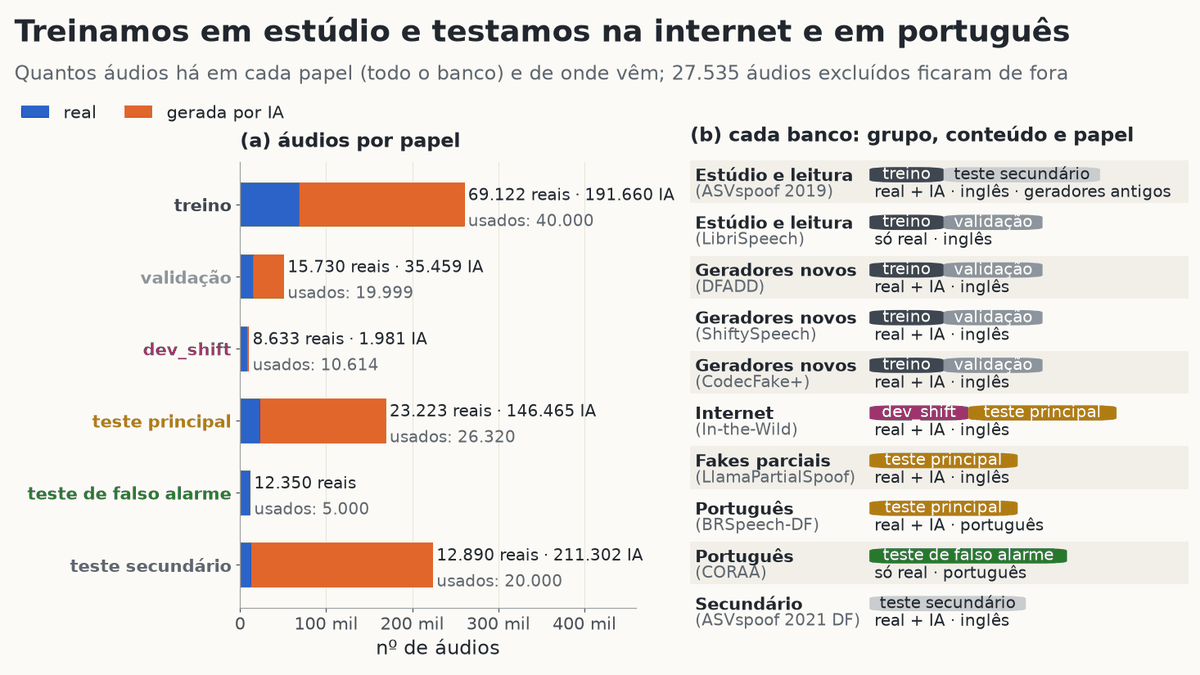

In [3]:
figura("01_composicao_banco")

**O que olhar:** o treino e a validação são grandes e quase todos de inglês de estúdio ou leitura; a internet (dev_shift e In-the-Wild) e o português só aparecem fora do treino; o treino tem muito mais IA que reais (por isso a amostra metade/metade).

**O que concluir:** o sistema aprende num mundo (estúdio, inglês) e é cobrado em outros (internet, fakes parciais, português). A diferença entre esses mundos explica a maior parte dos erros das figuras seguintes.

**O que faz:** mostra a tabela `results/slides/grupos_bancos.csv` (banco, grupo, o que é, real/IA, idioma, ano, papel e nº de áudios) e conta, no manifest, os áudios por banco, divisão e rótulo. **Por quê:** o manifest é a única fonte da verdade sobre os dados; a tabela confirma a divisão acima.

In [4]:
tabela("grupos_bancos.csv", pasta=SLIDES)
df = pd.read_parquet("data/processed/manifest.parquet", columns=["source_dataset", "split", "label", "eval_subset"])
df["split"] = df["split"].fillna("excluído")
df.loc[df.eval_subset == "dev_shift", "split"] = "dev_shift"
t = df.groupby(["source_dataset", "split", "label"]).size().unstack(["split", "label"], fill_value=0)
t.columns = [f"{s}/{'IA' if l else 'real'}" for s, l in t.columns]
display(t[sorted(t.columns)])

,banco,grupo,o que é,real/IA,idioma,ano,geração dos geradores,papel,nº real,nº IA
0,ASVspoof 2019,Estúdio e leitura,"Desafio ASVspoof 2019, acesso lógico: falas do VCTK lidas em estúdio, com lo...",real e IA,inglês,2019 (do nome do banco),antigos (docs/dataset_overview.md: 'os antigos do ASVspoof 2019'),treino,5128,45096
1,CodecFake+,Geradores novos,Amostras de páginas de demonstração de 17 TTS baseados em codec neural (só a...,real e IA,inglês,não documentado,novos (agrupamento do projeto),treino,702,743
2,DFADD,Geradores novos,Falas do VCTK gravadas em estúdio e as mesmas frases geradas por 5 TTS (Grad...,real e IA,inglês,não documentado,novos (agrupamento do projeto),treino,35745,131700
3,LibriSpeech,Estúdio e leitura,Leitura de audiolivros (train-clean-100); só vozes reais.,só real,inglês,não documentado,— (só real),treino,22840,0
4,ShiftySpeech,Geradores novos,Leitura de audiolivro (LibriSpeech) e a mesma fala ressintetizada por 3 voco...,real e IA,inglês,não documentado,novos (agrupamento do projeto),treino,4707,14121
5,CodecFake+,Geradores novos,Amostras de páginas de demonstração de 17 TTS baseados em codec neural (só a...,real e IA,inglês,não documentado,novos (agrupamento do projeto),validação,164,188
6,DFADD,Geradores novos,Falas do VCTK gravadas em estúdio e as mesmas frases geradas por 5 TTS (Grad...,real e IA,inglês,não documentado,novos (agrupamento do projeto),validação,8710,31800
7,LibriSpeech,Estúdio e leitura,Leitura de audiolivros (train-clean-100); só vozes reais.,só real,inglês,não documentado,— (só real),validação,5699,0
8,ShiftySpeech,Geradores novos,Leitura de audiolivro (LibriSpeech) e a mesma fala ressintetizada por 3 voco...,real e IA,inglês,não documentado,novos (agrupamento do projeto),validação,1157,3471
9,In-the-Wild,Internet,"Falas de 54 figuras públicas coletadas na internet, reais e falsas; o gerado...",real e IA,inglês,não documentado,não documentado,dev_shift,8633,1981


,dev_shift/IA,dev_shift/real,excluído/IA,excluído/real,test/IA,test/real,train/IA,train/real,val/IA,val/real
source_dataset,,,,,,,,,,
asvspoof2019_la,0,0,0,838,63882,7355,45096,5128,0,0
asvspoof2021_df,0,0,0,0,147420,5535,0,0,0,0
brspeech_df,0,0,0,0,6587,1320,0,0,0,0
codecfake_plus,0,0,0,0,0,0,743,702,188,164
coraa,0,0,0,326,0,12350,0,0,0,0
dfadd,0,0,0,0,0,0,131700,35745,31800,8710
in_the_wild,1981,8633,0,0,9835,11330,0,0,0,0
librispeech,0,0,0,5323,0,0,0,22840,0,5699
llamapartialspoof,0,0,0,0,130043,10573,0,0,0,0


**Conclusão:** o treino é todo em inglês e quase todo de estúdio ou audiolivro; o dev_shift é o único conjunto "de internet" que podemos usar para decidir. Os áudios realmente usados pelo F0 são uma amostra: 40.000 de treino, 19.999 de validação e o dev_shift inteiro.

## 4. O pipeline, passo a passo (o mesmo no sistema anterior, v4 (F0), e no atual, v7 (T3))

Antes do sistema final, a figura 02 mostra como as versões 1 a 3 viam o áudio (log-mel + CNN). Na v4, essa etapa foi trocada por um modelo de fala pronto.

### Figura 02 · Como o áudio vira imagem (versões 1 a 3)

**O que ela mostra:** a mesma frase, dita pelo mesmo locutor do VCTK: à esquerda a gravação real, à direita a versão gerada por um TTS (validação, 4 s do meio). De cima para baixo: a forma de onda (a pressão do ar ao longo do tempo), o espectrograma (quanta energia há em cada frequência, a cada instante) e o log-mel de 64 faixas (o mesmo, com as frequências agrupadas como o ouvido agrupa e o brilho em escala logarítmica). No espectrograma e no log-mel, o eixo horizontal é o tempo, o vertical é a frequência (graves embaixo, agudos em cima) e o brilho é a intensidade.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/02_log_mel.png`.*

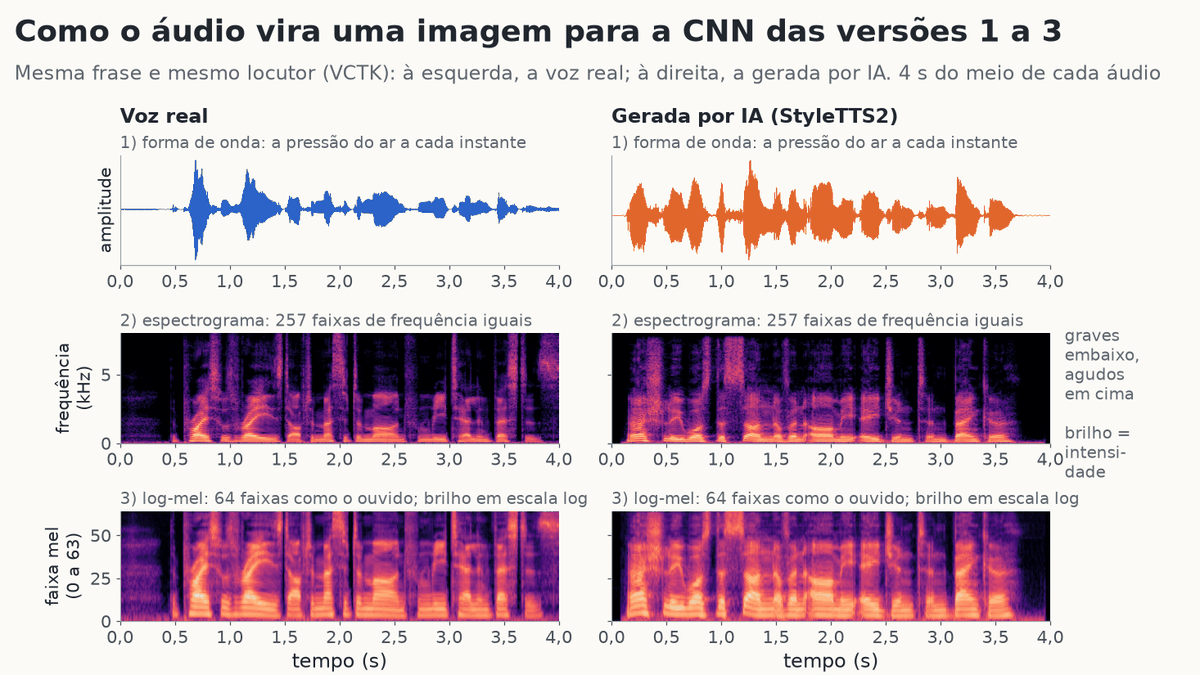

In [5]:
figura("02_log_mel")

**O que olhar:** as duas imagens são parecidas no geral (a mesma frase); as diferenças estão em detalhes finos, como a textura dos agudos e as pausas.

**O que concluir:** a CNN das versões 1 a 3 recebia o log-mel (a imagem de baixo) e tinha de achar sozinha esses detalhes; ela aprendeu bem o estúdio e falhou na internet (seção 9). A partir da v4, a onda vai direto para o XLS-R. A figura é só uma ilustração com 2 áudios, não uma medida.

**O pipeline (igual no F0 e na T3):**

1. **Áudio → pré-processamento** (`src/preproc.py`): mono, 16 kHz; corte do silêncio nas bordas (quadros 35 dB abaixo do mais forte; se sobrar menos de 0,5 s, não corta); recorte central de no máximo 8 s; **sem completar** (nem repetição nem zeros: cada áudio fica com o seu tamanho). Cada áudio é normalizado (média 0, variância 1). ⚠️ Fora da trilha: o corte de silêncio por energia.
2. **XLS-R 300M da Meta, congelado** (`src/ssl.py`): nenhum peso do modelo é treinado por nós. **O que usamos exatamente:** a classe `Wav2Vec2Model` do pacote `transformers` (na v4 ela era chamada direto; hoje o `AutoModel` escolhe a mesma classe, conferido abaixo). Ela é só o **codificador**: a parte convolucional que lê a onda + 24 camadas transformer. O arquivo de pesos foi salvo como `Wav2Vec2ForPreTraining` (o modelo do pré-treino), mas a parte usada no pré-treino para **adivinhar os trechos escondidos** (o quantizador e as projeções da tarefa contrastiva) **não é carregada nem usada**: nós só lemos os vetores internos. ⚠️ Fora da trilha: o modelo auto-supervisionado e o pacote `transformers`.
3. **Vetores por camada:** o modelo devolve 25 saídas (a entrada do transformer e a saída de cada uma das 24 camadas), cada uma com um vetor de 1.024 números a cada 20 ms.
4. **Média no tempo:** cada saída vira um vetor de 1.024 números pela média só nos quadros válidos (o desvio também fica no cache, mas o F0 não usa).
5. **Escolha das camadas: por que 5, 6 e 7.** Treinamos **uma regressão por camada** (25 regressões), cada uma com o seu C escolhido pela validação, e ordenamos as camadas pela **menor EER média por fonte na validação**: 7, 5, 6, 8, 9… (figura 05). As **três melhores** (5, 6 e 7) foram **concatenadas** (3 × 1.024 = 3.072 números); juntar as quatro melhores também foi testado, e a validação preferiu três. Uma explicação possível (**HIPÓTESE, não provada**): as camadas do meio ainda guardam mais detalhe do som, enquanto a última fica mais perto do que foi dito (as palavras) do que de como o som foi produzido.
6. **Regressão logística** (scikit-learn): a única parte treinada com os nossos rótulos (seção 5).

**Por que o modelo pronto ajudou tanto (EXPLICAÇÃO PROVÁVEL, NÃO PROVADA):** os vetores do modelo pronto vêm de um treino enorme e variado, sem rótulos; os da nossa CNN vinham de um treino estreito e foram moldados só para separar real de IA naquela mistura. Não testamos isso diretamente (por exemplo, não treinamos uma regressão logística sobre os vetores internos da CNN); é a leitura mais provável, não um resultado.

**O que faz:** mostra qual classe o `AutoModel` escolhe para o XLS-R e o que diz o `config.json` em cache (lidos pelo script das figuras, sem carregar os pesos). **Por quê:** confirmar o que de fato é usado, em vez de supor.

In [6]:
if F0:
    display(pd.Series(F0["modelo_hf"], name="valor").to_frame())

,valor
classe_AutoModel_para_wav2vec2,Wav2Vec2Model
config_architectures,[Wav2Vec2ForPreTraining]
config_num_hidden_layers,24
config_hidden_size,1024


**Conclusão:** a classe é `Wav2Vec2Model` (só o codificador), com 24 camadas de 1.024 números, como no código da v4.

### Figura 05 · Quais camadas do modelo separam melhor real de IA?

**O que ela mostra:** para cada uma das 25 saídas do XLS-R (eixo x), uma regressão logística treinada só com aquela camada. À esquerda, o erro (EER: o erro no corte em que reais acusados e IA que passa têm a mesma taxa); à direita, a AUC (a chance de dar nota maior a um áudio de IA que a um real). Linha cinza: estúdio (validação); linha vinho: internet (dev_shift). A faixa verde marca as camadas usadas no sistema (5, 6, 7).

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/05_camadas.png`.*

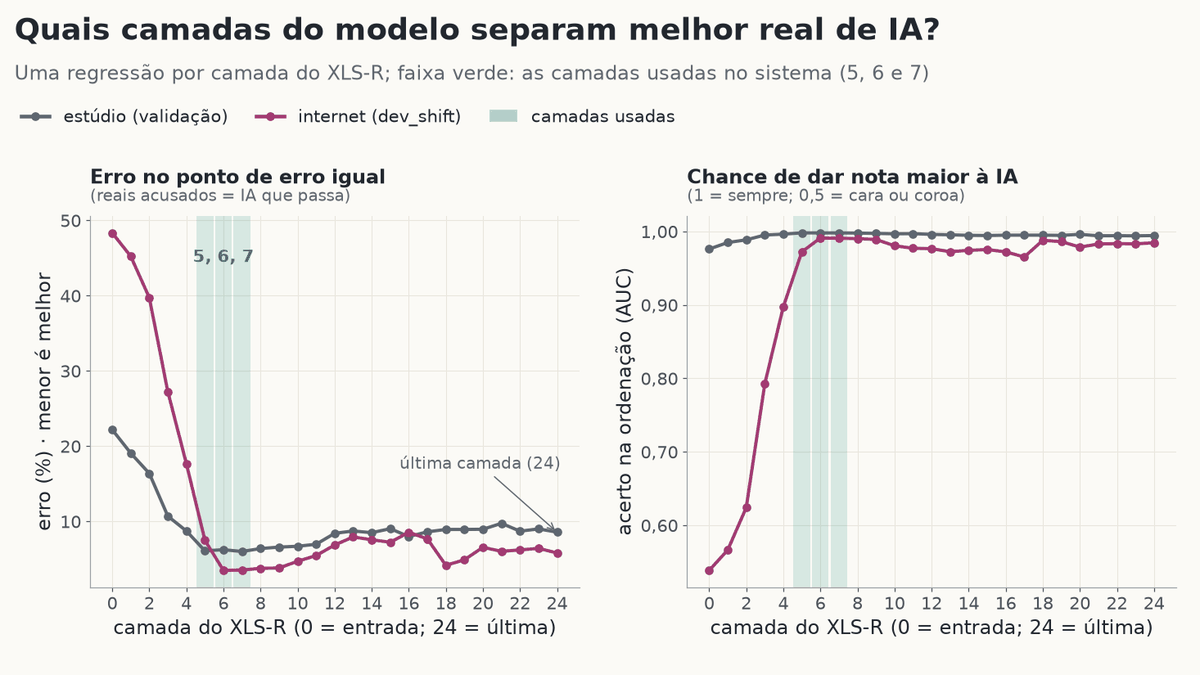

In [7]:
figura("05_camadas")

**O que olhar:** as camadas 0 a 3 quase não servem na internet (AUC 0,54 a 0,79); da 5 em diante, tudo passa de 0,97; as camadas 5 a 7 têm o menor erro no estúdio (a 7 sozinha: 6,0%; a 0: 22%; a 24: 8,6%).

**O que concluir:** as pistas úteis estão nas camadas do meio, e a escolha feita só pela validação caiu na região boa também para a internet; mas a última camada (24) já é quase tão boa na internet, o que bate com o S1 no teste (seção 8). O dev_shift é mostrado aqui, mas não escolheu nada.

### Figura 06 · Os vetores do modelo, sem a regressão

**O que ela mostra:** cada ponto é um áudio, representado pelo vetor de 1.024 números de uma camada do XLS-R, achatado em 2 dimensões por um método que tenta manter perto o que já era parecido (t-SNE; ⚠️ Fora da trilha). Ninguém disse ao método quem é real ou IA: as cores são pintadas depois. Colunas: camadas 5, 6, 7 e 24. Linha 1: só a validação (3.000 áudios), cor real × IA. Linha 2: validação + dev_shift (3.000 + 3.000), cor = origem (estúdio × internet). Linha 3: só o dev_shift (3.000), cor real × IA.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/06_vetores.png`.*

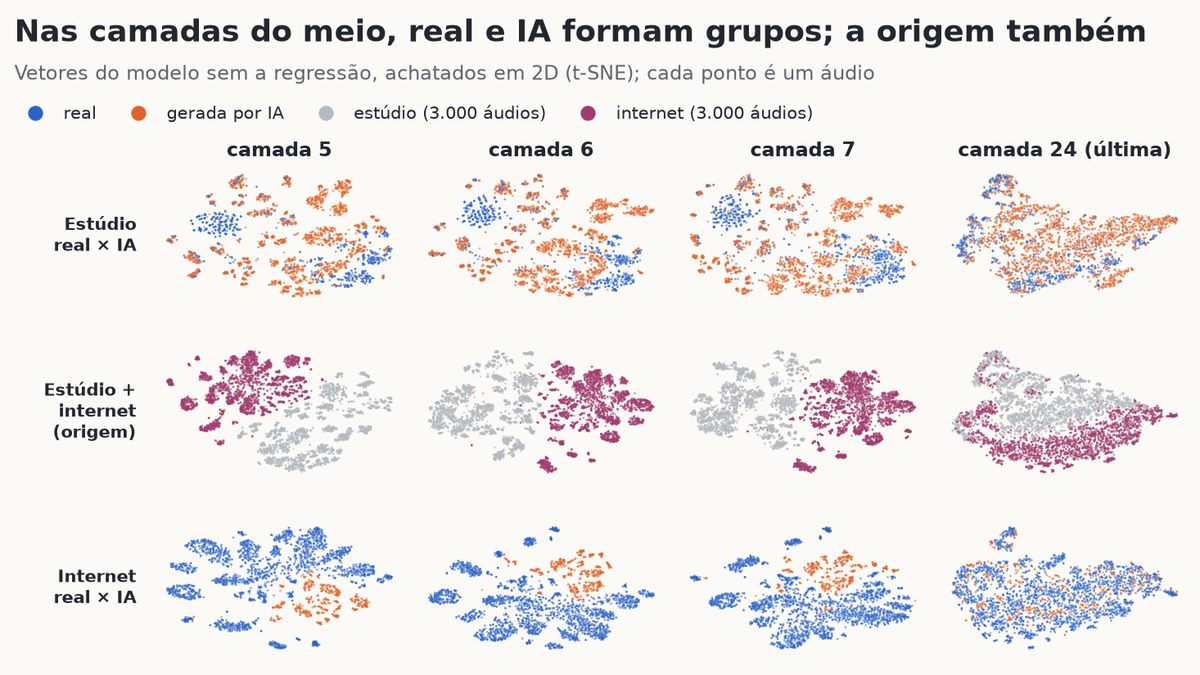

In [8]:
figura("06_vetores")

**O que olhar:** na linha 1 (estúdio), nas camadas 5 a 7 os pontos se juntam em muitos grupinhos de uma cor só; na camada 24, as cores se misturam mais. Na linha 2, estúdio e internet ocupam regiões separadas em **todas** as camadas, inclusive na 24: é a separação mais forte da figura. Na linha 3 (só internet), nas camadas 5 a 7 os gerados por IA se concentram numa região; na 24, ficam espalhados entre os reais.

**O que concluir:** mesmo sem nenhum rótulo, os vetores das camadas do meio já carregam a diferença real × IA, também na internet; a última camada guarda menos dessa diferença (o mesmo que a figura 05 mostra em números). Mas a informação mais forte nos vetores é "de onde veio a gravação", e por isso um corte calibrado só no estúdio não se transfere sem ajuste para a internet (figuras 03 e 04). O t-SNE distorce distâncias: só os agrupamentos têm leitura, não as posições nem os tamanhos.

### G3 · A versão anterior desta análise (PCA e t-SNE, camadas 7 e 24)

**O que ela mostra:** os mesmos 3.000 + 3.000 áudios, nas camadas 7 e 24, com dois métodos de achatar: PCA (as duas direções de maior variação; ⚠️ Fora da trilha) e t-SNE. Cada projeção aparece duas vezes: cor real × IA e cor estúdio × internet.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Só no notebook.*

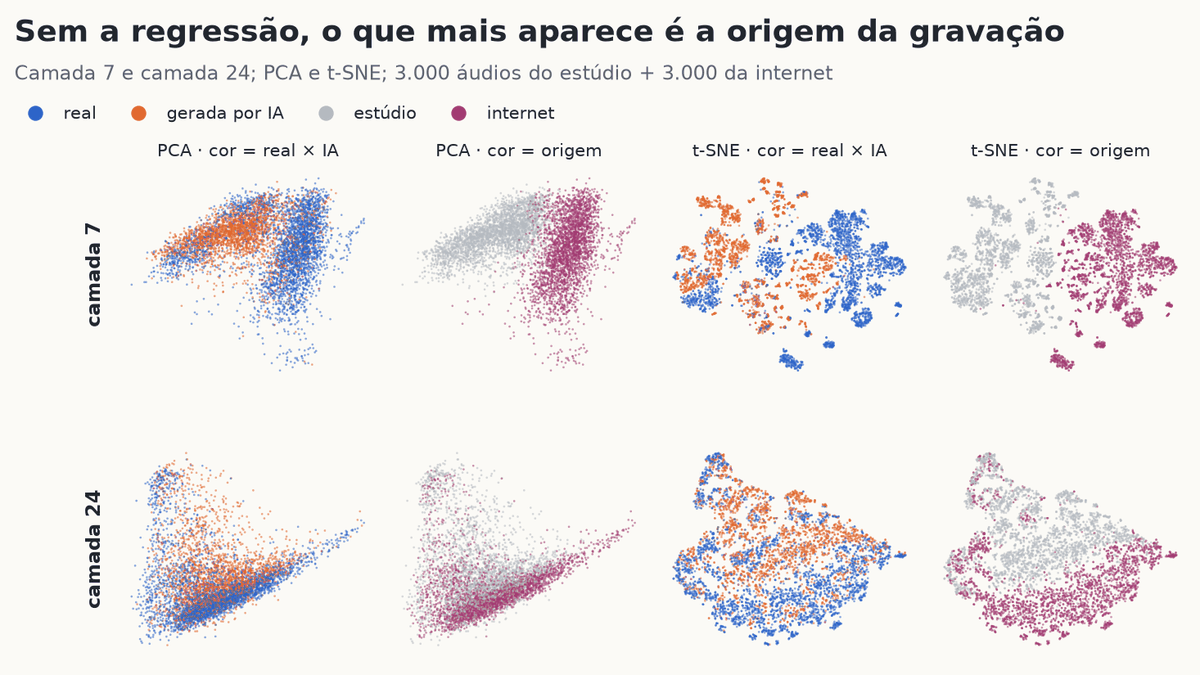

In [9]:
figura("g3_projecao")

**O que olhar:** nas duas camadas, a separação que mais salta aos olhos é estúdio × internet (o tipo de gravação); real × IA aparece em grupos menores, mais claros na camada 7.

**O que concluir:** os vetores do modelo pronto carregam muita informação de "de onde veio a gravação", e a regressão (seção 5) é o que acha a direção real × IA no meio disso; o t-SNE distorce distâncias, então só os agrupamentos (não as posições) têm leitura.

## 5. A NOSSA PARTE: a regressão logística

**O que é, em linguagem simples.** Para cada áudio temos 3.072 números (x). A regressão multiplica cada número por um peso, soma tudo e soma um número fixo: **nota z = w·x + b**. Se a nota passa do **corte**, o áudio é chamado de **gerado por IA**. A nota vira probabilidade pela sigmoide, p = 1 / (1 + e^(−z)). Na figura, isso é uma **fronteira de decisão reta** (um plano, em 3.072 dimensões): de um lado "real", do outro "IA" (Aula de regressão logística e fronteira de decisão).

**O que ela aprende com os nossos rótulos:** só os 3.072 pesos w e o número b (3.073 parâmetros). O XLS-R não muda.

**O que entra:** a média no tempo das saídas **5, 6 e 7** do XLS-R, cada número **padronizado** com a média e o desvio do treino (assim nenhum número pesa mais só por ter escala maior), concatenadas.

**Hiperparâmetros:**
- **C = 0,1**: o inverso da força do "freio" de regularização L2 (Aula 7, overfitting e regularização). C pequeno = freio forte = pesos pequenos. ⚠️ Fora da trilha só o nome do parâmetro no scikit-learn; a ideia é a da aula.
- **Solver lbfgs** (o padrão do scikit-learn), até 1.000 iterações, tolerância 0,0001. ⚠️ Fora da trilha: o lbfgs (a trilha usa descida do gradiente; o problema é o mesmo, e é convexo, então o resultado não depende de seed).
- **Peso das classes: nenhum.** O treino já tem 20.000 reais e 20.000 gerados por IA.

**Como a camada, o C e os cortes foram escolhidos (tudo na v4, antes do teste):**
1. Uma regressão por camada (25), cada uma com C na grade 0,001 / 0,01 / 0,1 / 1, escolhido pela **EER média por fonte na validação** (média da EER do DFADD, do ShiftySpeech e do CodecFake+; o LibriSpeech só tem reais).
2. As camadas foram ordenadas por essa EER: 7, 5, 6, 8, 9… As 3 melhores (5, 6, 7) foram concatenadas e o C foi escolhido de novo pela mesma régua: **C = 0,1** (tabela abaixo).
3. Entre as candidatas (melhor camada sozinha, 3 camadas, 4 camadas, somas ponderadas), venceu a de menor EER média por fonte: `concat_top3`, 5,92%.
4. **Corte A** (calibrado no estúdio) = o ponto de EER da **validação inteira**: nota −0,04 (probabilidade 0,49). **Corte B** (calibrado na internet) = o ponto de EER do **dev_shift**: nota 8,22 (probabilidade 0,9997). Os dois foram declarados antes do teste. O B é muito mais alto porque, nas vozes de internet, os reais recebem notas mais altas que os reais de estúdio (figura 04).

**O que a nota significa:** quanto maior, mais "cara de IA". A probabilidade só é bem calibrada no mundo de estúdio (G8, seção 7): nas vozes de internet, uma nota alta não quer dizer "certamente IA".

**O que faz:** mostra a grade de C da cabeça F0 e a lista de cabeças candidatas da v4. **Por quê:** é a escolha feita pela validação, com os números exatos.

**No sistema atual, v7 (T3), a regressão é a mesma, com três diferenças** (lidas de `results/v7_t3_modelo.json`):
- **Os dados de treino:** 81.288 áudios = estúdio (20.000 reais / 20.000 de IA, os mesmos do F0) + internet real (7.802 / 2.854) + IA moderna em canal degradado (15.316 / 15.316, durações pareadas).
- **O freio:** **C = 0,01** (mais freio que o F0, C = 0,1), escolhido pela validação na grade 0,0001 a 10.
- **O peso das classes:** `class_weight = "balanced"` (a internet real tem muito mais reais que falsos; com o peso, reais e falsos contam o mesmo no total). A padronização (média e desvio) é recalculada no treino da T3.

Os pesos da T3 (3.072 coeficientes, o intercepto, a média e o desvio da padronização) estão em `results/v7_t3_coeficientes.npz`, conferidos contra as notas gravadas da v7 (diferença máxima 1.1e-05 de logit; AUC igual com 3 casas em 13 recortes). O texto abaixo descreve o **F0**, que foi onde as escolhas de camada e de C foram feitas.

In [10]:
g = ler(R / "v4_parcial" / "concat_3.json")
if g:
    display(Markdown(f"**Grade de C da concatenação das camadas {g['camadas']}** (escolhido: C = {g['C']:g}):"))
    display(pd.DataFrame(g["grade"]).round(4))
else:
    pendente("`results/v4_parcial/concat_3.json` (fica fora do git)")
rs = ler(R / "v4_resumo.json")
display(Markdown(f"**Candidatas da v4 (EER média por fonte na validação):** vencedora `{rs['cabeça_final_pela_validação']}`"))
display(pd.DataFrame(rs["candidatas"]).round(4))
mc = ler(R / "v4_camadas_concluido.json")
display(Markdown(f"Ordem das camadas pela validação: {mc['ordem_camadas_val'][:6]}…; melhor camada sozinha: "
                 f"{mc['melhor_camada']} (C = {mc['melhor_camada_C']:g})."))

**Grade de C da concatenação das camadas [5, 6, 7]** (escolhido: C = 0.1):

,C,val EER média por fonte,iterações,convergiu,segundos
0,0.001,0.0702,47,True,1.8
1,0.010,0.0660,67,True,2.5
2,0.100,0.0592,56,True,2.1
3,1.000,0.0682,35,True,1.3


**Candidatas da v4 (EER média por fonte na validação):** vencedora `concat_top3`

,cabeça,val EER média por fonte
0,concat_top3,0.0592
1,concat_top4,0.0598
2,rl_camada_7,0.0599
3,soma_mlp,0.0638
4,soma_linear,0.0673


Ordem das camadas pela validação: [7, 5, 6, 8, 9, 10]…; melhor camada sozinha: 7 (C = 0.01).

**Conclusão:** C = 0,1 teve a menor EER média por fonte (5,92%) na grade; com C = 1 (freio fraco) a EER subiu para 6,82%, e com C = 0,001 (freio forte) para 7,02%. As diferenças entre as candidatas são pequenas (5,92% a 6,73%).

### Figura 03 · A regressão vista de cima: estúdio × internet

**O que ela mostra:** cada ponto é um áudio. O eixo horizontal é **a própria nota da regressão** (quanto mais à direita, mais ela acha que é IA); o eixo vertical não decide nada: é só a direção em que os áudios mais variam fora da nota, usada para espalhar os pontos (⚠️ Fora da trilha: PCA). Por isso a fronteira de decisão é exatamente uma reta vertical, no corte. As duas retas são o corte A (calibrado no estúdio) e o corte B (calibrado na internet); a faixa entre elas é a região em que os dois cortes discordam. À esquerda, a validação (estúdio); à direita, o dev_shift (internet).

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/03_plano_regressao.png`.*

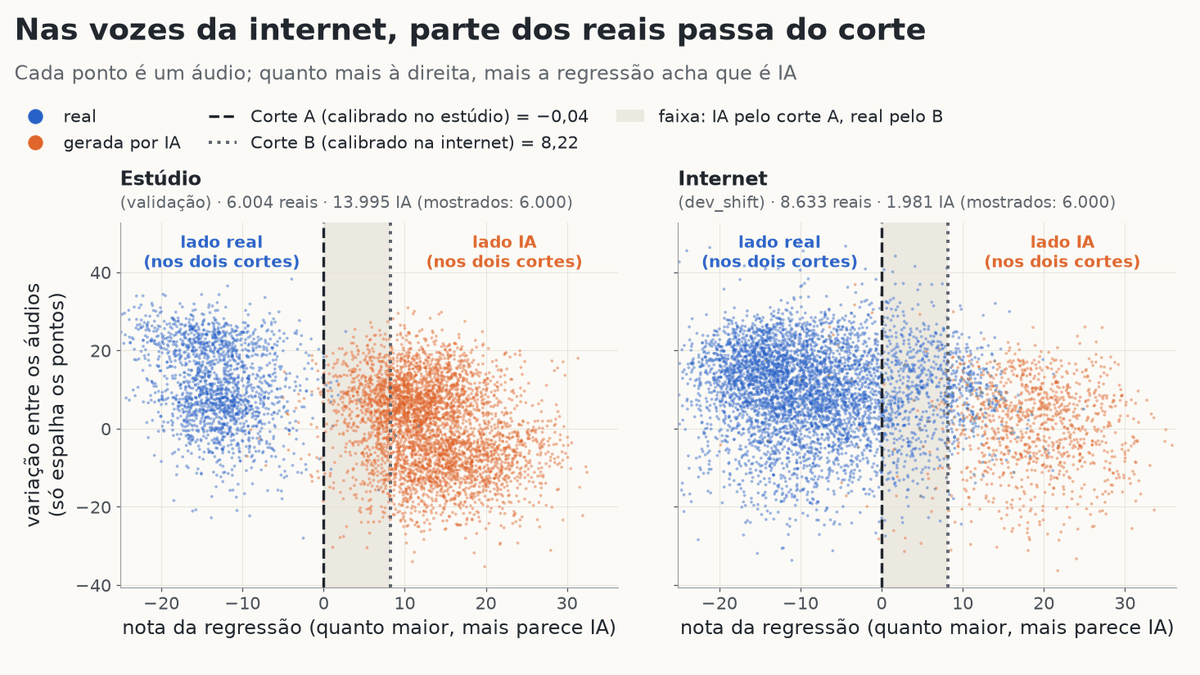

In [11]:
figura("03_plano_regressao")

**O que olhar:** no estúdio, quase todos os reais (azul) ficam à esquerda do corte A e quase todos os gerados por IA (laranja) à direita; na internet, uma **cauda de reais** passa do corte A e cai na faixa do meio.

**O que concluir:** a regressão separa muito bem o mundo do treino; o erro que sobra na internet é de **reais com nota alta**, e é por isso que o corte B (mais à direita) reduz os reais acusados ali. O eixo vertical explica só 11% da variação fora da nota: é uma fatia do espaço, não o espaço inteiro.

### G1 · O mesmo plano, fonte por fonte

**O que ela mostra:** o mesmo desenho da figura 03, com a validação separada por fonte (DFADD, ShiftySpeech, CodecFake+, LibriSpeech), a validação inteira e o dev_shift. Até 6.000 pontos por painel.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Só no notebook.*

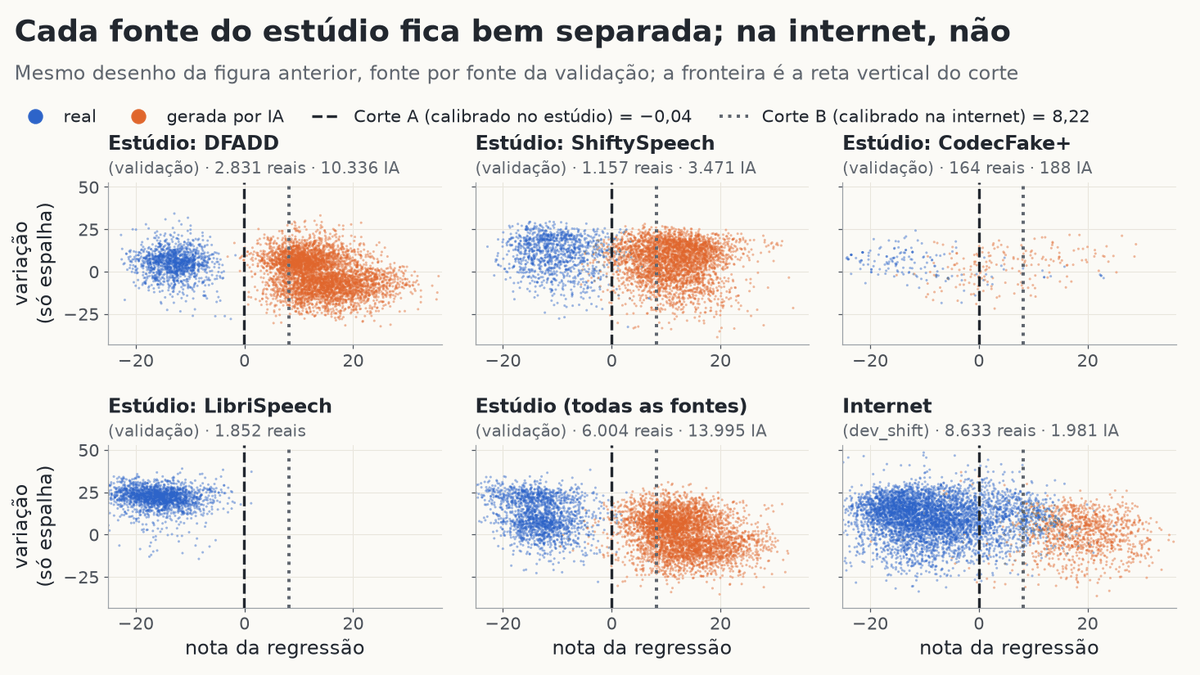

In [12]:
figura("g1_plano_decisao")

**O que olhar:** no DFADD e no LibriSpeech os reais ficam todos à esquerda do corte A; no CodecFake+ (352 áudios) há gerados por IA dos dois lados; no dev_shift, a cauda de reais passa do corte A.

**O que concluir:** dentro do estúdio, a fonte mais difícil é a de codec neural (CodecFake+); fora dele, o problema muda de lado: não são gerados por IA escapando, são reais acusados.

### Figura 04 · Onde caem as notas de reais e de gerados por IA, por grupo

**O que ela mostra:** para cada grupo, dois histogramas da nota: azul para os reais e laranja para os gerados por IA (a altura é a proporção dos áudios daquela classe em cada faixa de nota, então as duas classes são comparáveis mesmo com tamanhos diferentes). As retas A e B são os dois cortes. Grupos: estúdio (validação), internet (dev_shift e teste In-the-Wild), fakes parciais (LlamaPartialSpoof), português (BRSpeech-DF) e português só real (CORAA). Os bancos de teste aparecem só para mostrar: nada foi escolhido com eles.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/04_distribuicao_nota.png`.*

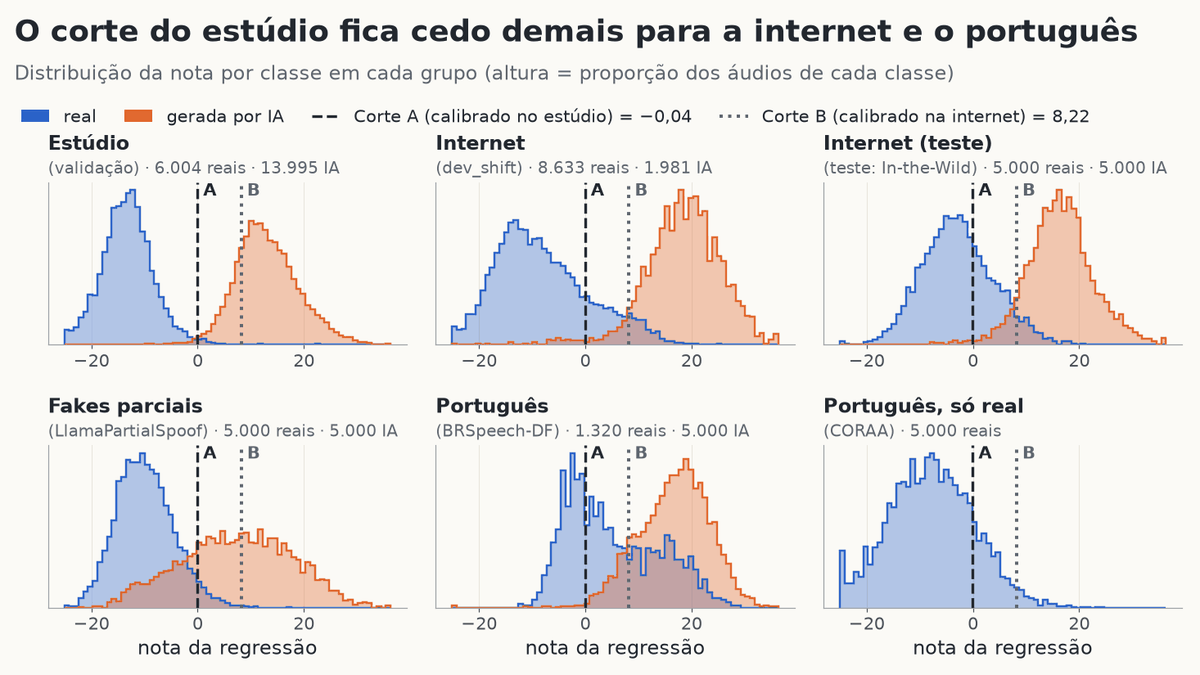

In [13]:
figura("04_distribuicao_nota")

**O que olhar:** a distância entre as duas montanhas e onde ficam os cortes; no estúdio elas quase não se tocam; na internet os reais se deslocam para a direita; no português (BRSpeech-DF) os reais têm duas montanhas, uma delas no meio dos gerados por IA; nos fakes parciais, parte dos gerados por IA fica à esquerda do corte B.

**O que concluir:** o corte A (estúdio) fica cedo demais para a internet e para o português, o que produz reais acusados; o corte B corrige parte disso, mas deixa passar mais gerados por IA (fakes parciais). Por que parte dos reais do BRSpeech-DF tem nota alta **não foi investigado** (o banco mistura pt-BR e pt-PT; é uma hipótese, não um achado).

### G5 · Quanto cada camada pesa dentro da regressão

**O que ela mostra:** a soma dos valores absolutos dos 1.024 pesos de cada camada na regressão final (as entradas são padronizadas, então os pesos são comparáveis) e a distribuição dos pesos dentro de cada camada.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Só no notebook.*

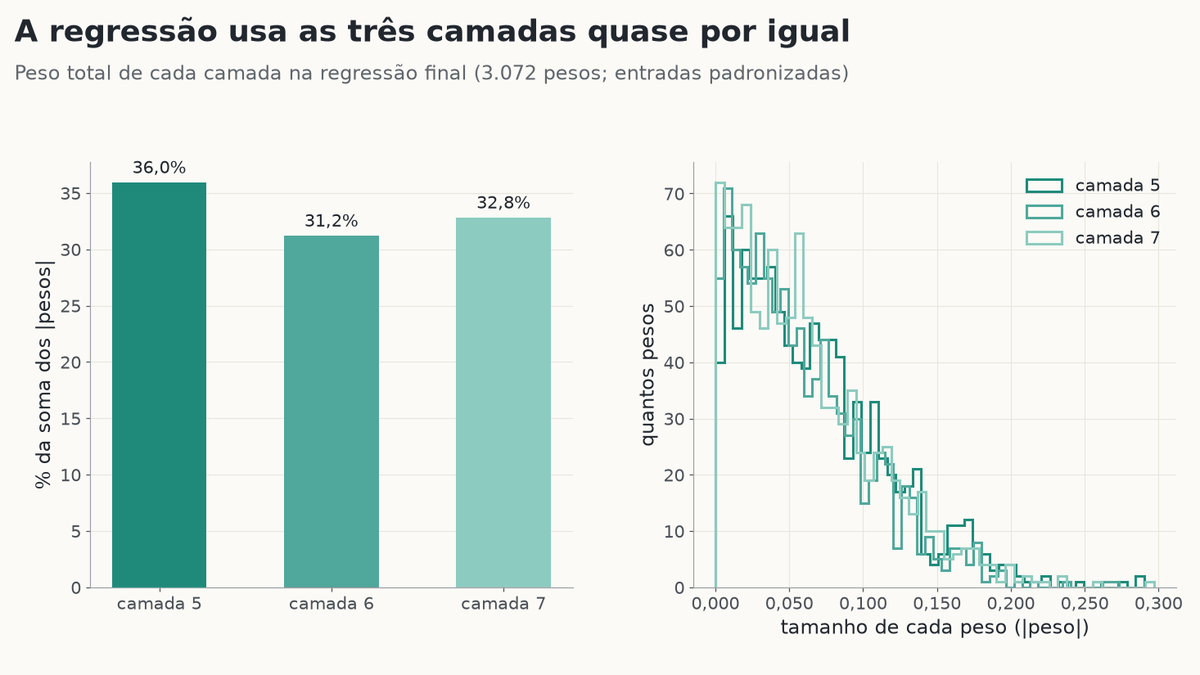

In [14]:
figura("g5_pesos_camadas")

**O que olhar:** as três barras são parecidas (36%, 31% e 33%) e as distribuições dos pesos se sobrepõem.

**O que concluir:** a regressão usa as três camadas quase por igual, sem uma dominar; como as camadas vizinhas são muito parecidas, o peso de cada uma não diz o quanto ela é "necessária" (tirar uma provavelmente mudaria pouco, mas isso não foi testado aqui).

## 6. Por que a regressão logística foi a melhor opção

**(a) Nos nossos testes, as cabeças mais complexas não ganharam.**
- **v4** (regra: menor EER média por fonte na validação): regressão em 1 camada 5,99%, em 3 camadas 5,92%, em 4 camadas 5,98%, soma ponderada + linear 6,63% a 6,85% (3 seeds), soma ponderada + MLP 6,28% a 6,57%. A vencedora foi uma regressão logística. As diferenças entre as regressões (0,06 ponto) são muito menores que a régua de ruído que a v3 mediu na validação (1,5 ponto na EER média por fonte, entre seeds da CNN); **não fizemos teste formal de ruído na v4**, então "empate" aqui é leitura, não prova.
- **v6, E4** (regra do desafiante: uma cabeça mais complexa só entra com diferença relevante, IC95 sem o zero e ≥ 0,005 na AUC da pior fonte, nas 3 seeds): RL 0,904; MLP 0,902 a 0,912; CNN 0,906 a 0,910. **Nenhuma seed de MLP ou CNN teve diferença relevante** → fica a RL, a mais simples.
- Pelas duas regras (menor erro na v4; desafiante na v6), a cabeça que fica é uma regressão logística. Atenção: a RL da E4 era a camada 11 com C = 1 (não o F0); o F0 entra na tabela como referência.

**(b) Menos parâmetros, menos risco de overfitting (Aula 7) e treino em segundos:** RL 3.073 parâmetros (F0) contra 262.657 (MLP) e 405.825 (CNN) da E4; o F0 treina em ~2 s no processador.

**(c) Da literatura (NÃO VERIFICADO POR NÓS; informado pela pesquisa de apoio do projeto, que não reproduzimos):** num artigo da Interspeech 2024 sobre o XLS-R 2B congelado, a regressão logística teve EER médio de 6,5%, contra 8,2% do MLP e 11,3% da autoatenção. Não lemos o artigo nesta sessão nem reproduzimos esses números.

**(d) Controle com rótulos embaralhados (um teste de sanidade).** Treinamos a mesma regressão (camada 7, C = 0,01) com os rótulos do treino **embaralhados ao acaso**, de modo que "real" e "IA" deixam de ter qualquer relação com o som. Se mesmo assim ela acertasse, haveria um problema no procedimento (por exemplo, a avaliação vazando informação do rótulo, ou um erro de código). Resultado: AUC 0,474 na validação e 0,486 no dev_shift, ou seja, **cara ou coroa** (0,5), como deveria. A regressão não "inventa" separação: o que ela acerta vem do som.

**(e) Por que MLP e CNN não ganham (HIPÓTESE, não provada).** Os vetores das camadas do meio do XLS-R já separam real e IA quase com uma reta (figuras 03 e 06), então uma fronteira curva tem pouco a acrescentar. E, com 40.000 áudios de um só mundo (estúdio), mais parâmetros podem decorar detalhes do estúdio que não valem na internet: a própria regressão já acerta 100% do treino (figura 08). As figuras 07 e 08 mostram o mesmo tema por outro lado: mais freio e mais simplicidade não pioraram a internet.

**O que NÃO foi provado:** que a RL seja melhor que MLP ou CNN (só que não perdeu de forma demonstrável); que as 3 camadas sejam melhores que a última sozinha no teste (S2 − S1 "não demonstrada", seção 8); que o C = 0,1 seja o melhor fora do estúdio (a figura 07 sugere o contrário).

**O que faz:** mostra as tabelas das cabeças da v4 e da E4 da v6 e o resultado do controle embaralhado, lidos do disco. **Por quê:** os números da comparação, sem resumo.

In [15]:
display(Markdown("**v4: cabeças sobre o XLS-R (escolha pela EER média por fonte na validação; dev_shift só reportado)**"))
tabela("v4final_cabecas_v4.csv", 4)
display(Markdown("**v6, E4: RL × MLP × CNN (AUC da pior fonte = menor AUC entre DFADD, ShiftySpeech, CodecFake+ e dev_shift)**"))
tabela("v4final_cabecas_v6_e4.csv", 4)
at = ler(R / "v4_atalhos.json")
display(Markdown("**Controle com rótulos embaralhados (v4):**"))
display(pd.Series(at["d_controle_rotulos_embaralhados"]).round(3).to_frame("valor"))

**v4: cabeças sobre o XLS-R (escolha pela EER média por fonte na validação; dev_shift só reportado)**

,rodada,cabeça,tipo,seed,camadas,camada,C,val EER média por fonte,dev AUC,dev EER,dev acurácia balanceada
0,v4 (regra: menor EER média por fonte na validação),rl_camada_7,"regressão logística, melhor camada",-,NaN,7.0,0.01,0.0599,0.9907,0.0353,0.9350
1,v4 (regra: menor EER média por fonte na validação),concat_top3,"regressão logística, concatenação ([5, 6, 7])",-,"[5, 6, 7]",NaN,0.10,0.0592,0.9833,0.0588,0.8965
2,v4 (regra: menor EER média por fonte na validação),concat_top4,"regressão logística, concatenação ([5, 6, 7, 8])",-,"[5, 6, 7, 8]",NaN,0.01,0.0598,0.9896,0.0405,0.9170
3,v4 (regra: menor EER média por fonte na validação),soma_linear,soma ponderada + linear,42,NaN,NaN,NaN,0.0663,0.9828,0.0480,0.9109
4,v4 (regra: menor EER média por fonte na validação),soma_linear,soma ponderada + linear,123,NaN,NaN,NaN,0.0685,0.9822,0.0492,0.9073
5,v4 (regra: menor EER média por fonte na validação),soma_linear,soma ponderada + linear,2026,NaN,NaN,NaN,0.0671,0.9816,0.0495,0.9000
6,v4 (regra: menor EER média por fonte na validação),soma_linear_ensemble,"soma ponderada + linear (ensemble, só reportado)",média das 3,NaN,NaN,NaN,0.0700,0.9822,0.0490,0.9056
7,v4 (regra: menor EER média por fonte na validação),soma_mlp,soma ponderada + MLP,42,NaN,NaN,NaN,0.0657,0.9821,0.0631,0.8722
8,v4 (regra: menor EER média por fonte na validação),soma_mlp,soma ponderada + MLP,123,NaN,NaN,NaN,0.0629,0.9863,0.0521,0.8787
9,v4 (regra: menor EER média por fonte na validação),soma_mlp,soma ponderada + MLP,2026,NaN,NaN,NaN,0.0628,0.9830,0.0541,0.9111


**v6, E4: RL × MLP × CNN (AUC da pior fonte = menor AUC entre DFADD, ShiftySpeech, CodecFake+ e dev_shift)**

,rodada,sistema,cabeça,seed,parâmetros,segundos,AUC pior fonte,fonte pior,AUC codecfake_plus,AUC dev_shift,val EER média por fonte (3)
0,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,RL básica,RL,-,1025.0,2.2000,0.9037,codecfake_plus,0.9037,0.9719,0.0763
1,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,MLP básico s42,MLP,42,262657.0,2.3000,0.9116,codecfake_plus,0.9116,0.9853,0.0721
2,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,MLP básico s123,MLP,123,262657.0,1.5000,0.9056,codecfake_plus,0.9056,0.9886,0.0755
3,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,MLP básico s2026,MLP,2026,262657.0,1.7000,0.9022,codecfake_plus,0.9022,0.9808,0.0728
4,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,"MLP básico (média das 3 seeds, só reportado)",MLP,média,262657.0,1.8333,0.9065,NaN,0.9065,0.9849,0.0735
5,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,CNN básico s42,CNN,42,405825.0,15.9000,0.9062,codecfake_plus,0.9062,0.9786,0.0625
6,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,CNN básico s123,CNN,123,405825.0,10.1000,0.9081,codecfake_plus,0.9081,0.9828,0.0641
7,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,CNN básico s2026,CNN,2026,405825.0,13.9000,0.9104,codecfake_plus,0.9104,0.9792,0.0609
8,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,"CNN básico (média das 3 seeds, só reportado)",CNN,média,405825.0,13.3000,0.9082,NaN,0.9082,0.9802,0.0625
9,v6 E4 (regra: desafiante; o mais simples fica se não houver diferença releva...,"v4 (referência: XLS-R concat 5,6,7 + RL, C=0,1)",RL,-,NaN,NaN,0.9031,codecfake_plus,0.9031,0.9833,0.0592


**Controle com rótulos embaralhados (v4):**

,valor
camada,7.000
C,0.010
val AUC,0.474
val EER média por fonte,0.507
dev AUC,0.486
dev EER,0.505


**Conclusão:** em duas rodadas e com duas regras diferentes, a regressão logística ficou; MLP e CNN tiveram números parecidos com 100 vezes mais parâmetros, e o controle embaralhado deu cara ou coroa, como deveria.

As duas figuras abaixo são **diagnósticos feitos depois** (no documento final): as regressões extras só servem para os gráficos e não mudaram camada, C nem corte.

### Figura 07 · O freio da regressão (C)

**O que ela mostra:** a mesma regressão do sistema treinada com 11 valores de C, do freio mais forte (C = 0,0001, à esquerda) ao mais fraco (C = 10, à direita). À esquerda, o erro (EER) no estúdio e na internet; à direita, o tamanho dos pesos. A faixa verde marca o C usado no sistema (0,1), escolhido na v4 pela validação.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/07_c_freio.png`.*

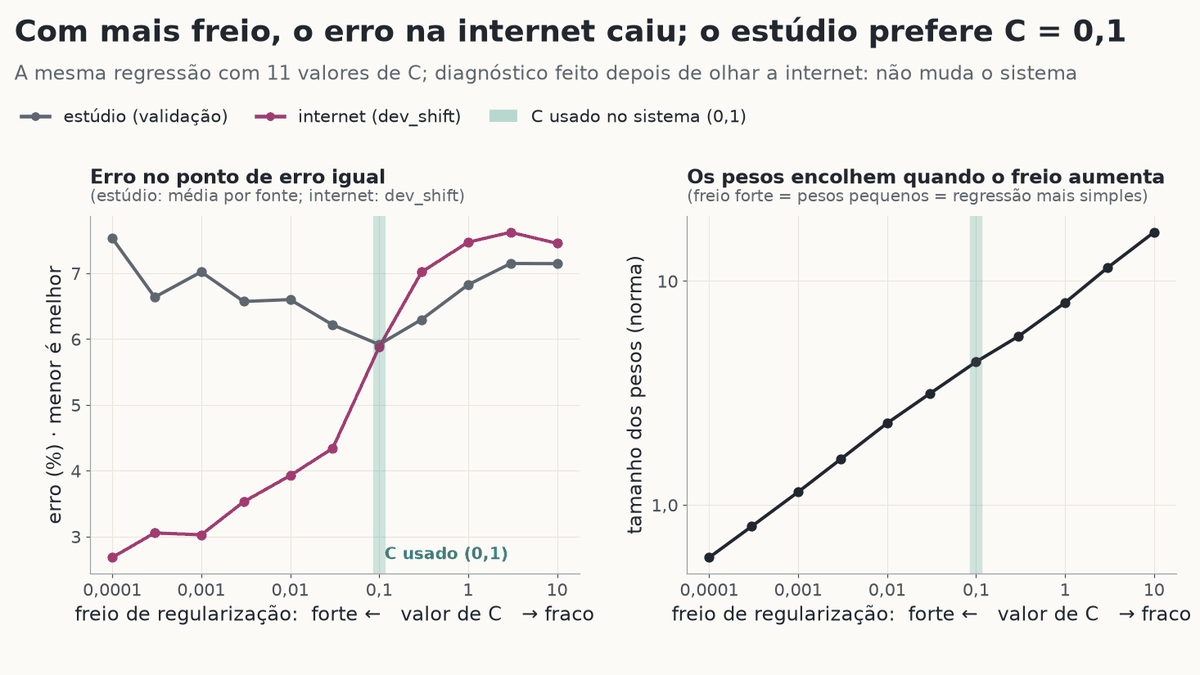

In [16]:
figura("07_c_freio")

**O que olhar:** no estúdio o menor erro fica no C usado (0,1; 5,92%); na internet o erro cai sem parar quando o freio aumenta (C = 0,0001: 2,7%, contra 5,9% no sistema); os pesos encolhem cerca de 30 vezes do freio mais fraco ao mais forte.

**O que concluir:** um freio mais forte (regressão mais simples) parece generalizar melhor para fora do estúdio; é o mesmo tema da v6, em que C = 1 piorou o português. Isto foi visto **depois de olhar o dev_shift** (16 locutores): **não muda o F0** e só vale como hipótese para uma versão nova, confirmada num banco nunca visto.

### Figura 08 · Mais áudios de treino ajudam?

**O que ela mostra:** a mesma regressão (C = 0,1) treinada com 2 mil, 5 mil, 10 mil, 20 mil e 40 mil áudios (metade real, metade IA, um sorteio por tamanho, seed 42). À esquerda, a acurácia balanceada (no corte A de cada modelo); à direita, a AUC; nas duas, no próprio treino (tracejado), no estúdio e na internet.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/08_curva_aprendizado.png`.*

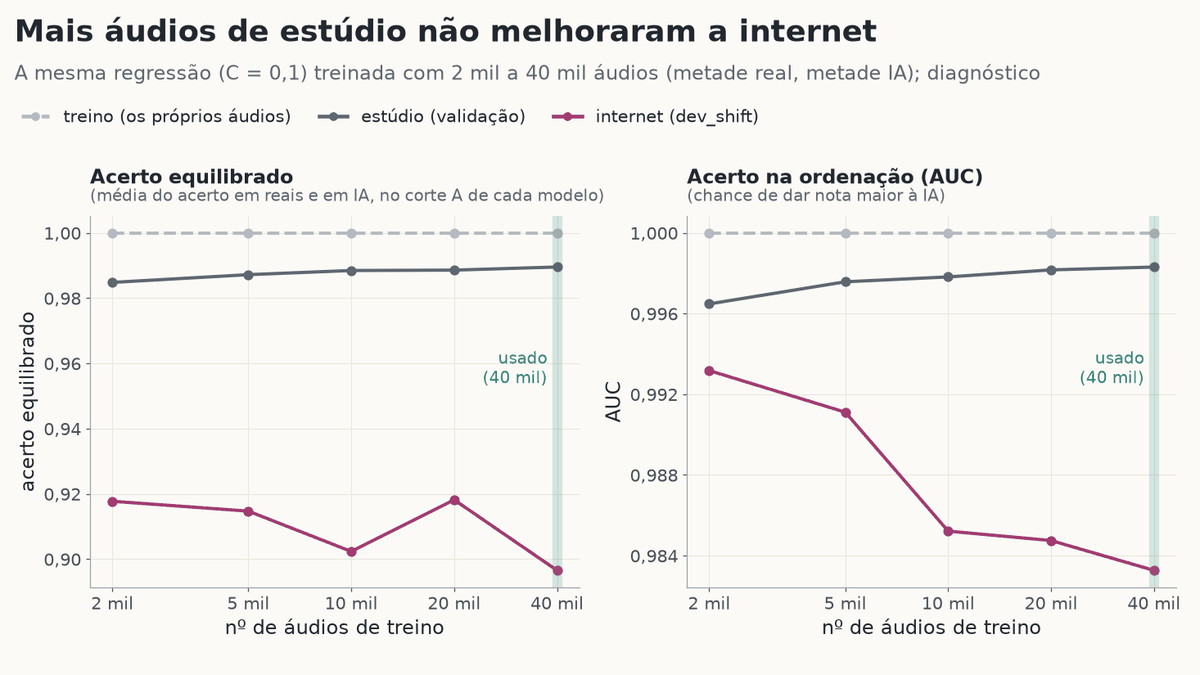

In [17]:
figura("08_curva_aprendizado")

**O que olhar:** o treino fica em 100% em todos os tamanhos; o estúdio sobe devagar (AUC 0,996 → 0,998); a internet **não sobe**: a AUC cai de 0,993 (2 mil) para 0,983 (40 mil).

**O que concluir:** mais áudios do mesmo mundo (estúdio) ajudam o estúdio, mas não a internet; acertar 100% do próprio treino mostra que a regressão consegue decorar o treino (overfitting, Aula 7). É um sorteio por tamanho, sem repetição, então a ordem exata dos pontos pode ser acaso.

## 7. Conferências e diagnósticos (sistema anterior: v4 (F0))

Todas as figuras vêm de `scripts/v4final_figuras.py`, que **reajustou o F0** (mesmos dados, camadas e C; lbfgs é determinístico) e conferiu contra as notas gravadas na v4 antes de desenhar. Os bancos de teste aparecem só para **mostrar**: a regressão e os cortes foram fixados antes do teste.

**O que faz:** mostra a conferência da reprodução (AUC com 3 casas e diferença máxima de nota, por conjunto). **Por quê:** se o reajuste não reproduzisse a v4, os gráficos seriam de outro modelo.

In [18]:
tabela("v4final_reproducao.csv", 6)

,conjunto,n,dif. máx. de nota (logit),AUC reajuste,AUC gravada (v4)
0,val,19999,0.000000,0.998,0.998
1,dev_shift,10614,0.000008,0.983,0.983
2,in_the_wild,10000,0.000010,0.979,0.979
3,llamapartialspoof,10000,0.000007,0.925,0.925
4,brspeech_df,6320,0.000008,0.842,0.842
5,coraa,5000,0.000002,NaN,NaN
6,asvspoof2019_la,10000,0.000007,0.999,0.999
7,asvspoof2021_df,10000,0.000010,0.997,0.997


**Conclusão:** a AUC bate nas 3 casas em todos os bancos e a maior diferença de nota é de ~0,00001 (as notas gravadas estão em float32): os gráficos são do F0 de verdade.

### G8 · A nota como probabilidade

**O que ela mostra:** os áudios agrupados pela probabilidade prevista de ser IA (0 a 0,1, 0,1 a 0,2…); para cada faixa, a fração que é de fato gerada por IA. Os números são os áudios de cada faixa (só faixas com pelo menos 100). Na diagonal, a probabilidade seria perfeita. ⚠️ Fora da trilha: calibração.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Só no notebook.*

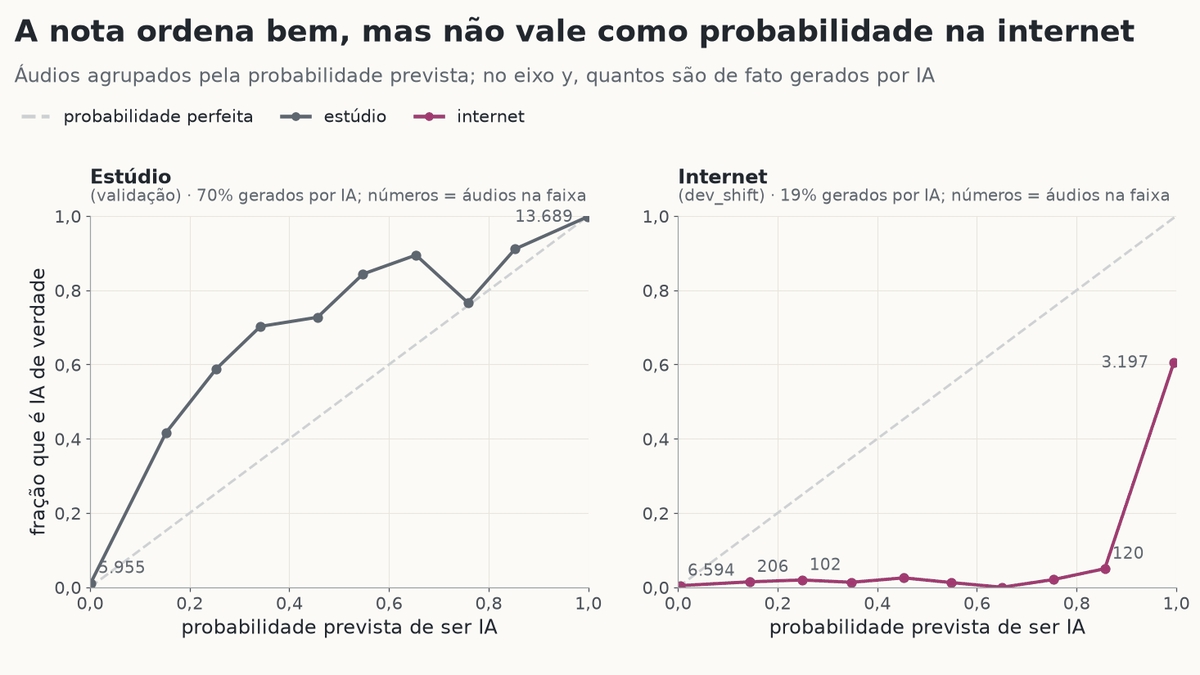

In [19]:
figura("g8_calibracao")

**O que olhar:** no estúdio quase todos os áudios estão nas pontas (0 a 0,1 e 0,9 a 1); na internet, entre 0,1 e 0,9 quase nada é IA, e na faixa 0,9 a 1 só 61% é IA.

**O que concluir:** a nota **ordena** bem, mas não deve ser lida como "chance de ser IA" fora do estúdio: na internet, "99% IA" está errado 4 em cada 10 vezes; a proporção de gerados por IA também muda entre os conjuntos (70% no estúdio, 19% na internet), e a calibração depende dela.

### G13 · Quais geradores escapam na validação

**O que ela mostra:** a % dos gerados por IA detectados, gerador por gerador, na validação (barra: corte A; traço: corte B). No CodecFake+, cada gerador tem de 5 a 32 áudios.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Só no notebook.*

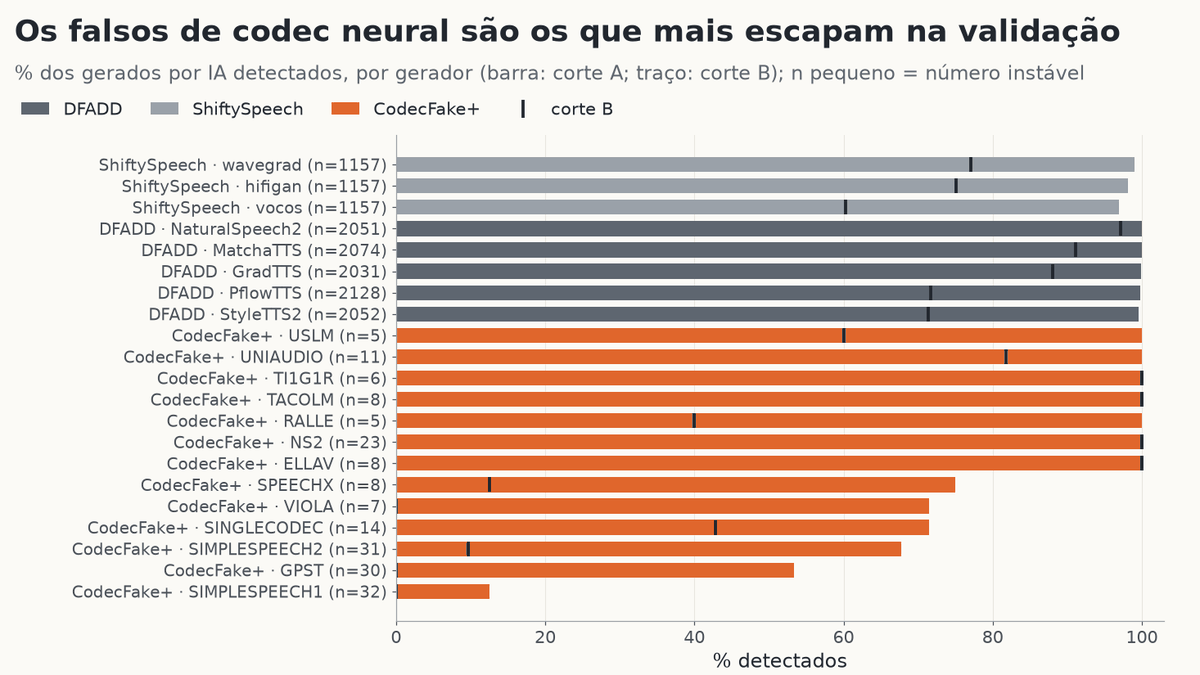

In [20]:
figura("g13_geradores")

**O que olhar:** DFADD e ShiftySpeech ficam perto de 100% no corte A; no CodecFake+ alguns geradores escapam muito (SIMPLESPEECH1 12%, GPST 53%, SIMPLESPEECH2 68%).

**O que concluir:** os gerados por codec neural são o tipo mais difícil dentro da validação; com tão poucos áudios por gerador, os números são instáveis e servem de pista, não de ranking.

## 8. Resultados no teste da v4 (sistema anterior: v4 (F0))

O teste foi avaliado **uma única vez**, na v4 (2026-11-10), pelo pré-registro, com até 5.000 áudios por classe e banco (seed 42); nada foi reescolhido depois. Os números abaixo são os gravados (`results/v4_teste_final.csv`) e o reajuste os reproduz (seção 7).

**O que faz:** tabela por banco com acurácia, acurácia balanceada, acurácia trivial, AUC, EER, recall de IA e falso alarme, nos cortes A e B, para o F0 (e, para comparar, S1 = só a camada 24 e S0 = a CNN da v3). **Por quê:** é o resultado final do sistema.

In [21]:
t8 = pd.read_csv(R / "v4final_teste_por_banco.csv")
cols = ["banco", "limiar", "acurácia", "acurácia balanceada", "acurácia trivial", "AUC", "EER", "recall fake",
        "falso alarme real", "acurácia balanceada IC95", "AUC IC95", "n real", "n fake"]
for s in ("F0 (v4 final)", "S1 (só camada 24)", "S0 (CNN da v3)"):
    display(Markdown(f"**{s}**"))
    display(t8[t8.sistema == s][cols].round(3))

**F0 (v4 final)**

,banco,limiar,acurácia,acurácia balanceada,acurácia trivial,AUC,EER,recall fake,falso alarme real,acurácia balanceada IC95,AUC IC95,n real,n fake
0,in_the_wild,A,0.836,0.835,0.500,0.979,0.068,0.989,0.318,0.829 a 0.842,0.976 a 0.981,5000,5000
1,in_the_wild,B,0.931,0.931,0.500,0.979,0.068,0.920,0.059,0.925 a 0.936,0.976 a 0.981,5000,5000
2,llamapartialspoof,A,0.855,0.855,0.500,0.925,0.147,0.750,0.040,0.849 a 0.862,0.920 a 0.930,5000,5000
3,llamapartialspoof,B,0.738,0.738,0.500,0.925,0.147,0.479,0.002,0.732 a 0.746,0.920 a 0.930,5000,5000
4,brspeech_df,A,0.863,0.679,0.791,0.842,0.249,0.995,0.636,0.667 a 0.693,0.827 a 0.854,1320,5000
5,brspeech_df,B,0.839,0.771,0.791,0.842,0.249,0.888,0.345,0.757 a 0.785,0.827 a 0.854,1320,5000
6,coraa,A,0.833,NaN,1.000,NaN,NaN,NaN,0.167,NaN,NaN,5000,0
7,coraa,B,0.975,NaN,1.000,NaN,NaN,NaN,0.025,NaN,NaN,5000,0
8,asvspoof2019_la,A,0.981,0.981,0.500,0.999,0.014,0.964,0.001,0.979 a 0.984,0.999 a 0.999,5000,5000
9,asvspoof2019_la,B,0.901,0.901,0.500,0.999,0.014,0.802,0.000,0.896 a 0.906,0.999 a 0.999,5000,5000


**S1 (só camada 24)**

,banco,limiar,acurácia,acurácia balanceada,acurácia trivial,AUC,EER,recall fake,falso alarme real,acurácia balanceada IC95,AUC IC95,n real,n fake
12,in_the_wild,A,0.829,0.829,0.500,0.986,0.054,0.992,0.333,0.823 a 0.836,0.985 a 0.988,5000,5000
13,in_the_wild,B,0.946,0.946,0.500,0.986,0.054,0.946,0.054,0.941 a 0.950,0.985 a 0.988,5000,5000
14,llamapartialspoof,A,0.851,0.851,0.500,0.936,0.140,0.734,0.032,0.844 a 0.858,0.931 a 0.940,5000,5000
15,llamapartialspoof,B,0.734,0.734,0.500,0.936,0.140,0.468,0.001,0.726 a 0.740,0.931 a 0.940,5000,5000
16,brspeech_df,A,0.849,0.671,0.791,0.775,0.307,0.976,0.633,0.658 a 0.683,0.759 a 0.791,1320,5000
17,brspeech_df,B,0.762,0.716,0.791,0.775,0.307,0.795,0.364,0.701 a 0.729,0.759 a 0.791,1320,5000
18,coraa,A,0.644,NaN,1.000,NaN,NaN,NaN,0.356,NaN,NaN,5000,0
19,coraa,B,0.884,NaN,1.000,NaN,NaN,NaN,0.116,NaN,NaN,5000,0
20,asvspoof2019_la,A,0.974,0.974,0.500,0.997,0.023,0.954,0.006,0.971 a 0.977,0.996 a 0.998,5000,5000
21,asvspoof2019_la,B,0.902,0.902,0.500,0.997,0.023,0.804,0.000,0.896 a 0.908,0.996 a 0.998,5000,5000


**S0 (CNN da v3)**

,banco,limiar,acurácia,acurácia balanceada,acurácia trivial,AUC,EER,recall fake,falso alarme real,acurácia balanceada IC95,AUC IC95,n real,n fake
24,in_the_wild,A,0.336,0.336,0.500,0.114,0.822,0.633,0.960,0.329 a 0.343,0.107 a 0.120,5000,5000
25,in_the_wild,B,0.181,0.181,0.500,0.114,0.822,0.210,0.848,0.174 a 0.188,0.107 a 0.120,5000,5000
26,llamapartialspoof,A,0.545,0.545,0.500,0.556,0.463,0.762,0.672,0.536 a 0.554,0.545 a 0.568,5000,5000
27,llamapartialspoof,B,0.523,0.523,0.500,0.556,0.463,0.397,0.351,0.513 a 0.533,0.545 a 0.568,5000,5000
28,brspeech_df,A,0.671,0.704,0.791,0.735,0.293,0.647,0.239,0.691 a 0.717,0.719 a 0.751,1320,5000
29,brspeech_df,B,0.447,0.609,0.791,0.735,0.293,0.331,0.113,0.598 a 0.620,0.719 a 0.751,1320,5000
30,coraa,A,0.347,NaN,1.000,NaN,NaN,NaN,0.653,NaN,NaN,5000,0
31,coraa,B,0.587,NaN,1.000,NaN,NaN,NaN,0.413,NaN,NaN,5000,0
32,asvspoof2019_la,A,0.900,0.901,0.500,0.967,0.080,0.803,0.002,0.895 a 0.906,0.963 a 0.970,5000,5000
33,asvspoof2019_la,B,0.795,0.795,0.500,0.967,0.080,0.591,0.000,0.788 a 0.802,0.963 a 0.970,5000,5000


### Figura 09 · Acurácia no teste, por grupo

**O que ela mostra:** a acurácia (% de acertos) do sistema v4 nos cortes A e B, da CNN antiga (S0, a CNN da v3, no corte A) e do "chute da classe comum" (responder sempre a classe que é maioria no banco) em cada banco principal e na média dos três. À direita, o CORAA, que só tem reais: ali a medida é a % de reais aceitos como reais (o chute "sempre real" acertaria 100%, por isso ele não aparece).

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/09_acuracia_grupos.png`.*

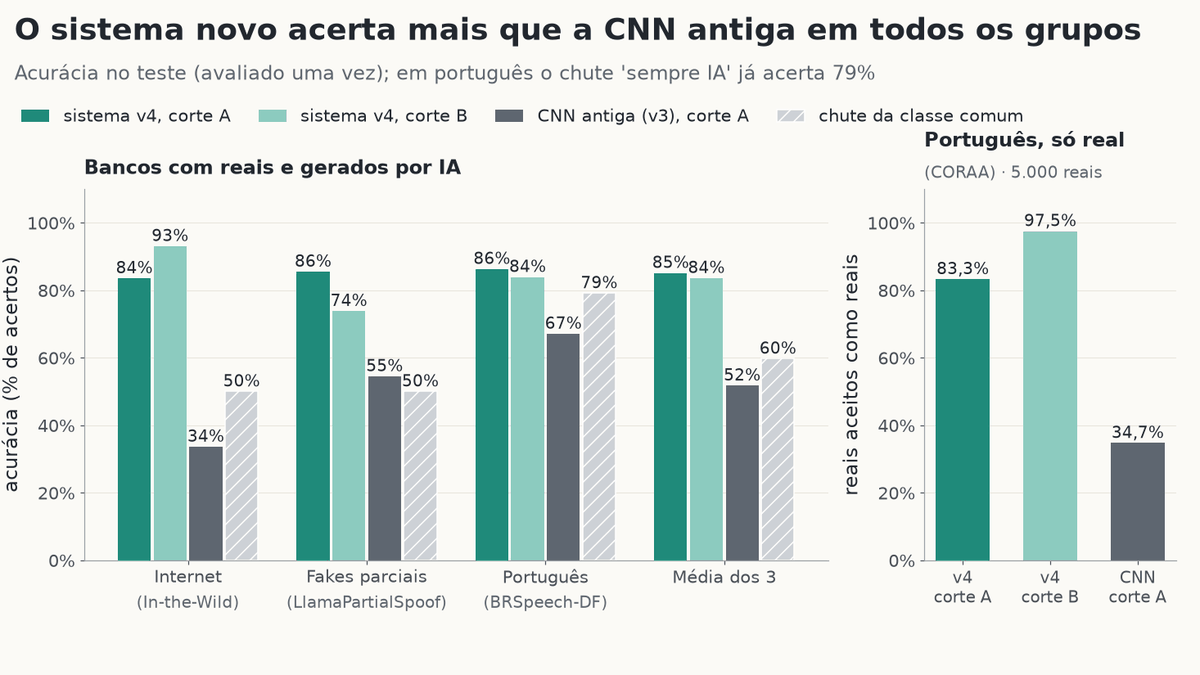

In [22]:
figura("09_acuracia_grupos")

**O que olhar:** na internet a CNN antiga fica **abaixo do chute** (34% contra 50%) e o v4 vai a 84% (A) e 93% (B); no português (BRSpeech-DF), com o corte A, o v4 (86%) passa pouco do chute (79%), porque 79% do banco é gerado por IA; no CORAA, o corte A aceita 83,3% dos reais e o B, 97,5%.

**O que concluir:** o sistema novo é muito melhor que a CNN em todos os grupos; a acurácia sozinha engana em banco desbalanceado (BRSpeech-DF, CORAA), por isso a acurácia balanceada e a AUC vêm junto (tabela acima).

### Figura 10 · Os dois tipos de erro, por grupo

**O que ela mostra:** à esquerda, a % de **reais acusados como IA** (o falso alarme); à direita, a % de **gerados por IA que passam sem alarme**; em cada grupo, a barra escura é o corte A e a clara o corte B. O CORAA só tem reais, então só aparece à esquerda.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/10_erros_por_grupo.png`.*

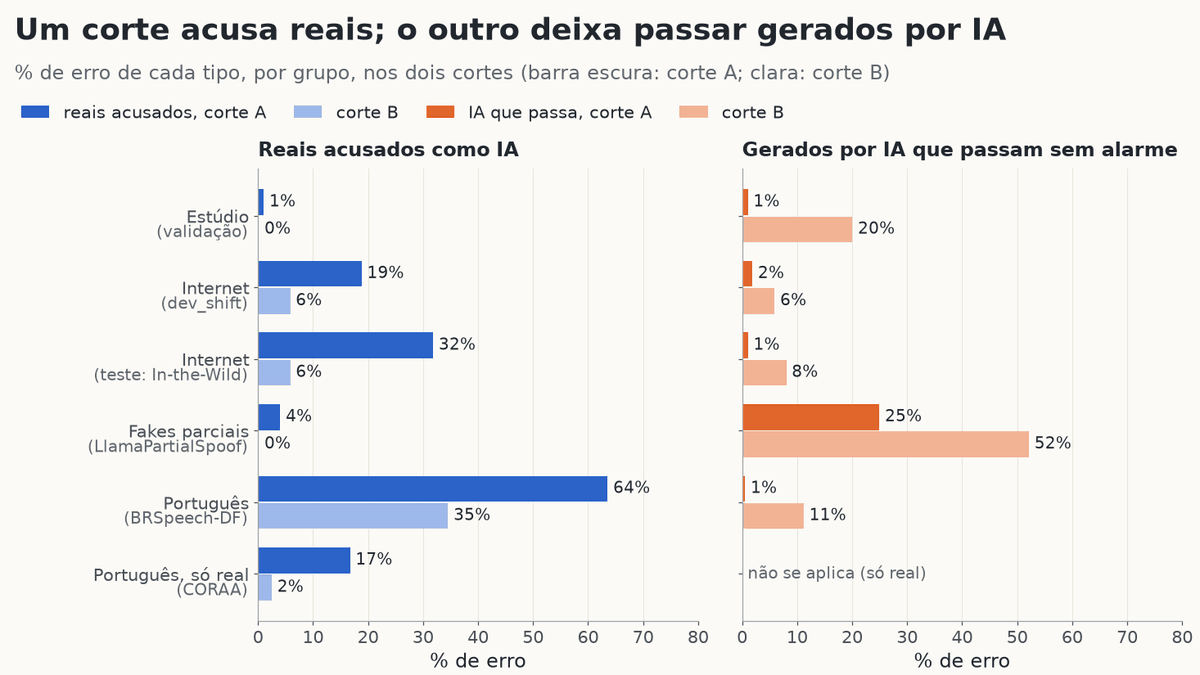

In [23]:
figura("10_erros_por_grupo")

**O que olhar:** com o corte A, os reais acusados são poucos no estúdio (1%) e muitos na internet (19% no dev_shift, 32% no teste) e no português (64% no BRSpeech-DF, 17% no CORAA); com o corte B, eles caem (6%, 6%, 35% e 2%), mas os gerados por IA que passam sobem: 52% nos fakes parciais e 20% no estúdio.

**O que concluir:** o corte escolhido no estúdio não serve para o mundo real, e o escolhido nas vozes de internet deixa passar fakes de outros tipos: nenhum corte único é bom em todos os grupos. Um corte por domínio é a ideia que ficou para depois (não testada).

### Figura 11 · A duração do áudio importa

**O que ela mostra:** a AUC do sistema separada pela duração **original** do arquivo (antes do corte de silêncio e do limite de 8 s): menos de 2 s, de 2 a 4 s e 4 s ou mais, nos três bancos principais do teste. O número dentro de cada barra é a quantidade de áudios na faixa.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/11_duracao.png`.*

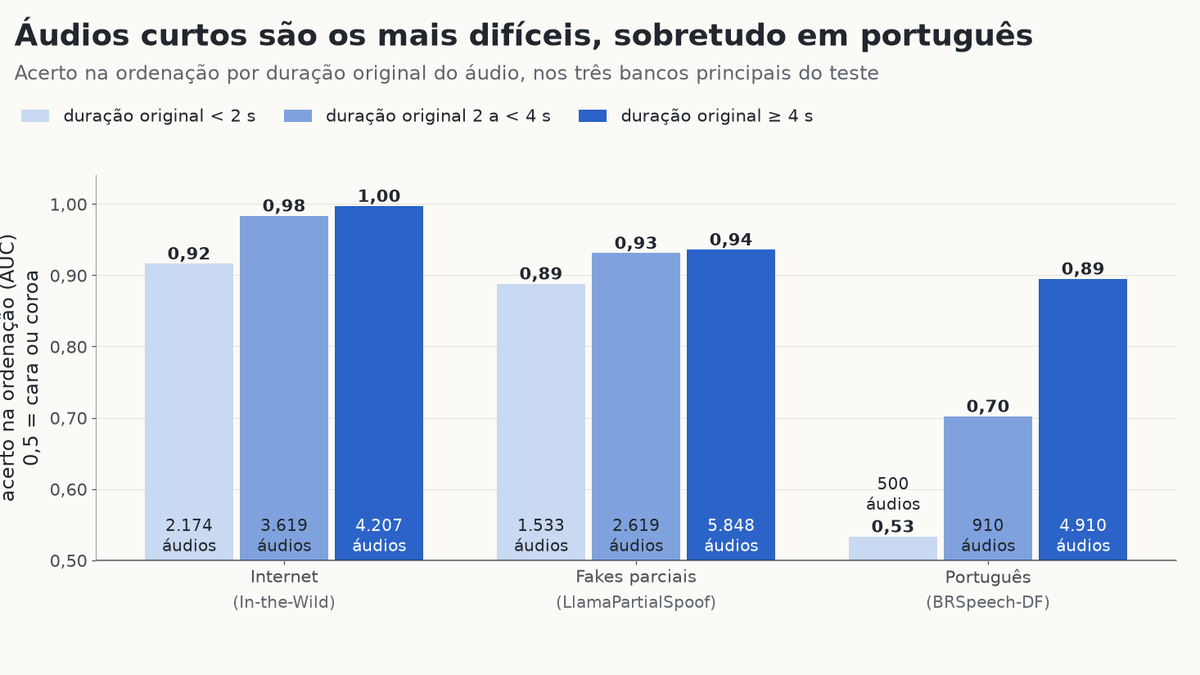

In [24]:
figura("11_duracao")

**O que olhar:** em todos os bancos os áudios curtos são os piores; no português, abaixo de 2 s a AUC é 0,53 (quase cara ou coroa, 500 áudios) e de 2 a 4 s é 0,70.

**O que concluir:** áudio curto é um ponto fraco geral, e o português curto é onde o sistema praticamente não funciona; a duração se mistura com outras diferenças (locutor, gravador), então é associação, não causa.

### Figura 14 · Todos os cortes possíveis de uma vez (curva ROC)

**O que ela mostra:** para cada corte possível, a % de reais acusados (eixo x) e a % de gerados por IA detectados (eixo y), nos três bancos principais. Uma curva colada no canto superior esquerdo é ótima; a diagonal é cara ou coroa. Os pontos marcam os cortes A (●) e B (■). ⚠️ Fora da trilha: a curva ROC (usada desde a v1).

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/14_roc.png`.*

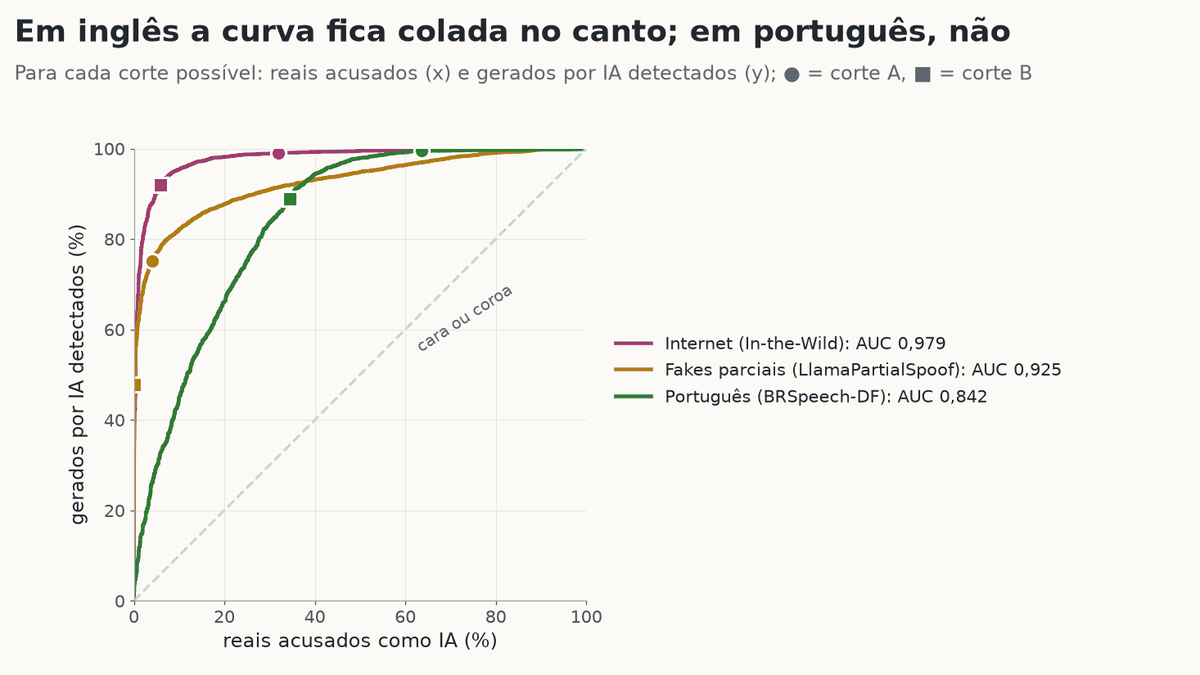

In [25]:
figura("14_roc")

**O que olhar:** as curvas da internet e dos fakes parciais ficam perto do canto; a do português fica bem abaixo; os pontos A e B ficam em lugares diferentes de cada curva.

**O que concluir:** a ordenação é boa em inglês (AUC 0,925 e 0,979) e fraca em português (0,842); a troca entre reais acusados e IA que passa depende do corte, e nenhum dos dois é bom em todos os bancos.

### G9 · Matrizes de confusão no teste, cortes A e B

**O que ela mostra:** as contagens de cada combinação (verdade × resposta do sistema) e a % por linha (linha = verdade), nos três bancos principais e no CORAA (só reais).

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Só no notebook.*

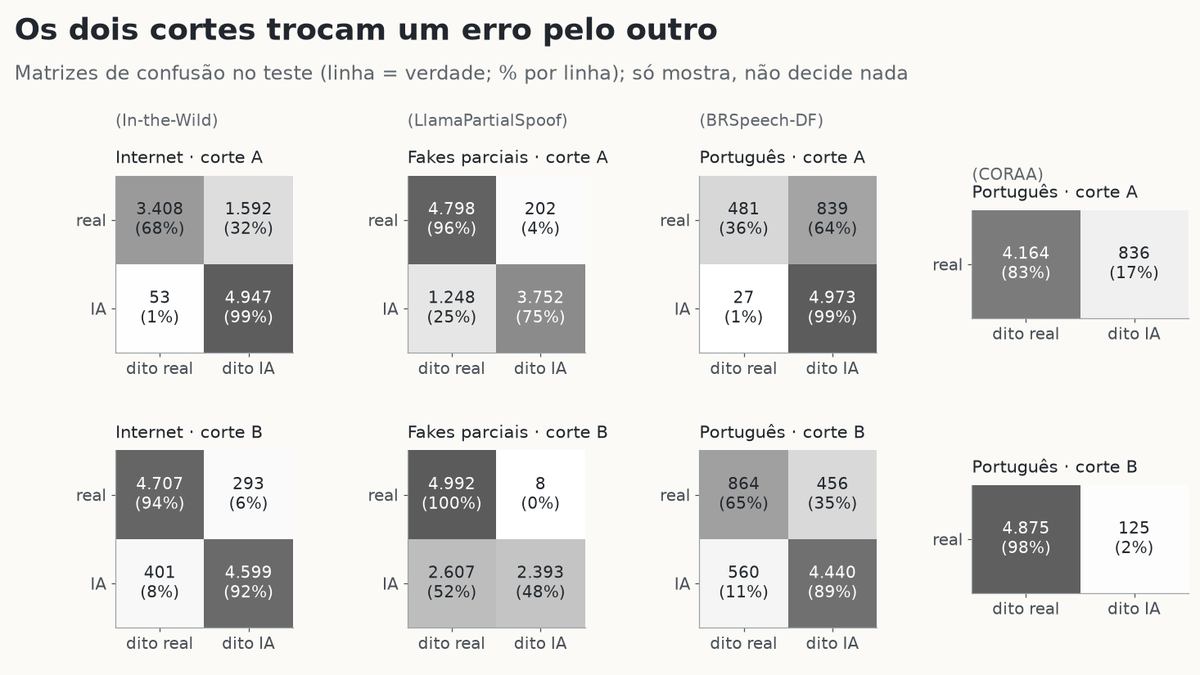

In [26]:
figura("g9_confusao")

**O que olhar:** no corte A, 32% dos reais da internet e 64% dos reais do BRSpeech-DF são acusados; no corte B, 52% dos gerados por IA do LlamaPartialSpoof passam.

**O que concluir:** os dois cortes trocam um erro pelo outro; o pior caso é o BRSpeech-DF, ruim nos dois.

### G1-teste · O plano da regressão nos bancos de teste (SÓ VISUALIZAÇÃO, NÃO DECIDE NADA)

**O que ela mostra:** o mesmo desenho da figura 03 (eixo x = nota; eixo y calculado no treino) para In-the-Wild, LlamaPartialSpoof, BRSpeech-DF e CORAA. Nada aqui foi usado para escolher qualquer coisa.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Só no notebook.*

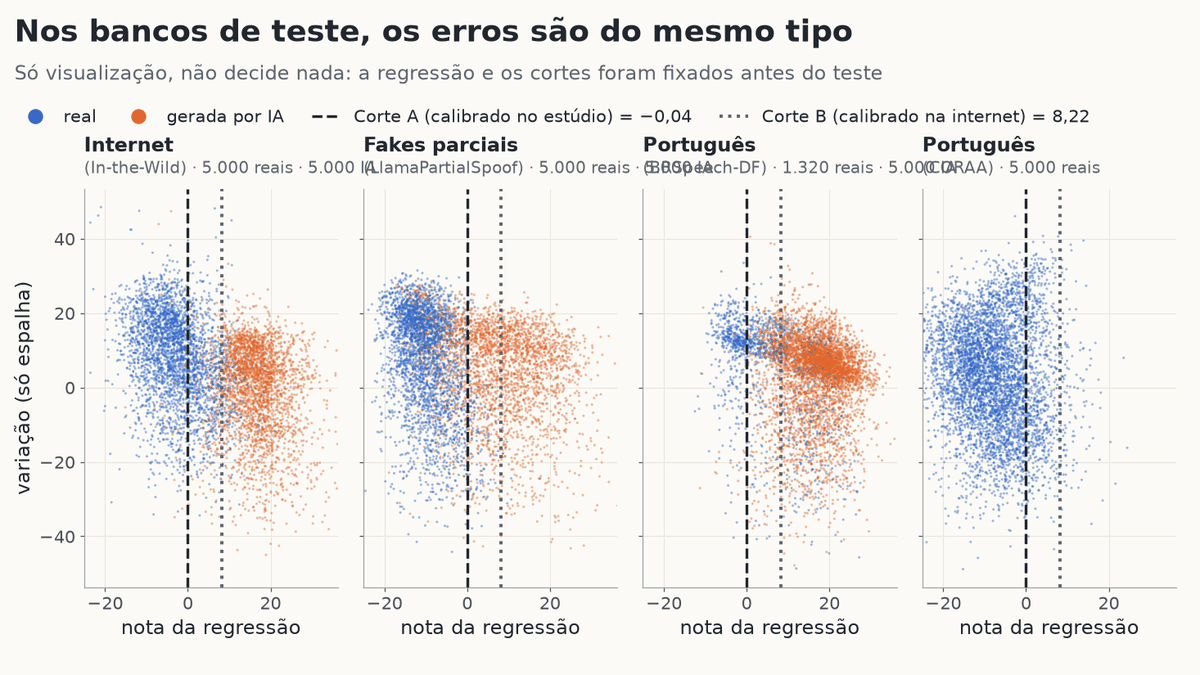

In [27]:
figura("g1_plano_decisao_teste")

**O que olhar:** no BRSpeech-DF uma boa parte dos reais (azul) fica à direita do corte A, e no CORAA também há reais à direita; no LlamaPartialSpoof, gerados por IA (laranja) à esquerda.

**O que concluir:** os erros do teste são do mesmo tipo do dev_shift (reais com nota alta, sobretudo em português) mais fakes parciais que passam; a figura não diz por quê, e não deve ser usada para mexer no corte.

### Figura 13 · Os testes secundários (ASVspoof)

**O que ela mostra:** acurácia (cortes A e B) e AUC do sistema v4 e da CNN antiga nos dois testes secundários, ASVspoof 2019 (parte eval) e ASVspoof 2021 DF. São **secundários** porque podem ter locutores em comum com o treino (o VCTK aparece anonimizado no ASVspoof e com nome no DFADD).

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/13_secundarios.png`.*

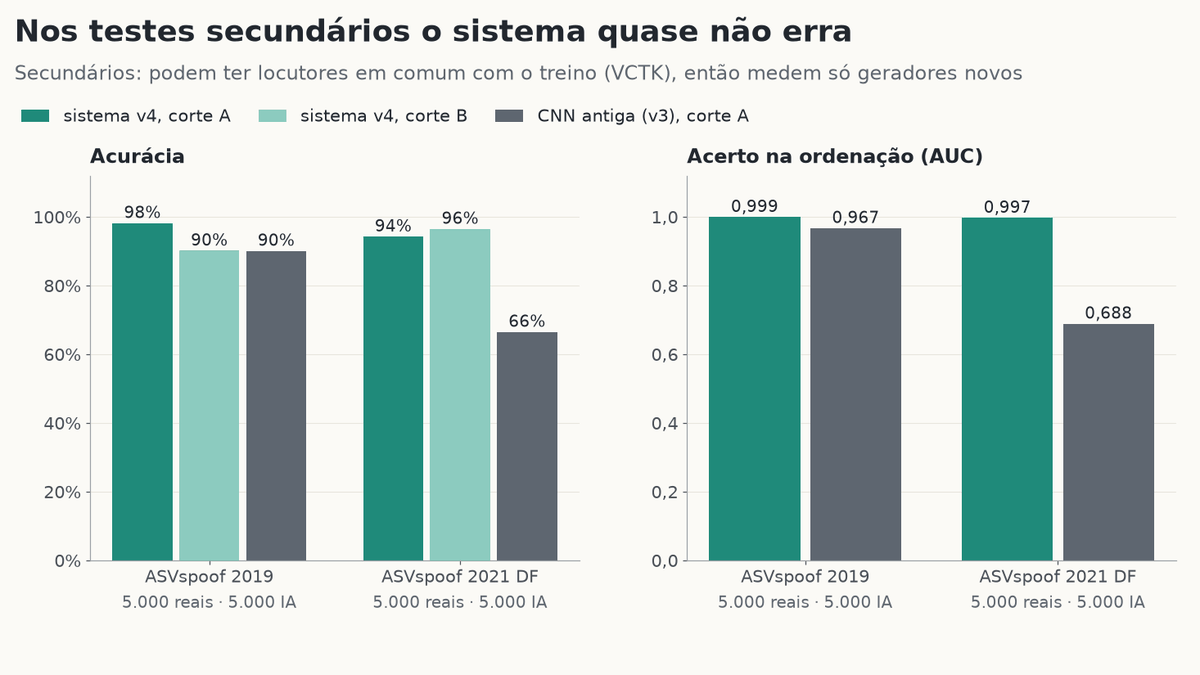

In [28]:
figura("13_secundarios")

**O que olhar:** no corte A, o v4 acerta 98% (2019) e 94% (2021), com AUC 0,999 e 0,997; a CNN antiga cai no 2021 (acurácia 66,5%, AUC 0,688).

**O que concluir:** números altos, mas valem só para **geradores novos**, não para pessoas novas; por isso não entram na média dos 3 principais.

**O que faz:** a média da acurácia dos 3 bancos principais (In-the-Wild, LlamaPartialSpoof, BRSpeech-DF), o falso alarme do CORAA à parte, e a leitura pré-definida das diferenças pareadas (S2 − S1 = "nossas escolhas"; S3 − S2 = "juntar a CNN"). **Por quê:** é o resumo combinado antes do teste.

In [29]:
tr = ler(R / "v4_teste_final_resumo.json")
res = pd.DataFrame(tr["resumo"]).replace({"sistema": {"S2": "S2 = F0"}})
display(res.round(3))
display(Markdown("**Leitura pré-definida** (relevante só com o mesmo sinal nos 3 principais e IC95 sem o zero em cada um):"))
display(pd.Series(tr["regra_leitura"]).to_frame("resultado"))
dif = pd.read_csv(R / "v4_teste_diferencas.csv")
display(dif.round(4))

,sistema,limiar,média acurácia (3 principais),média acurácia balanceada (3 principais),média acurácia trivial (3 principais),média AUC (3 principais),coraa falso alarme,coraa falso alarme IC
0,S0,A,0.517,0.529,0.597,0.468,0.653,"[0.638795, 0.666]"
1,S0,B,0.384,0.438,0.597,0.468,0.413,"[0.399, 0.427]"
2,S1,A,0.843,0.784,0.597,0.899,0.356,"[0.342, 0.3688]"
3,S1,B,0.814,0.798,0.597,0.899,0.116,"[0.106595, 0.1252]"
4,S2 = F0,A,0.851,0.790,0.597,0.915,0.167,"[0.1568, 0.178]"
5,S2 = F0,B,0.836,0.813,0.597,0.915,0.025,"[0.0208, 0.0292]"
6,S3,A,0.778,0.728,0.597,0.876,0.318,"[0.3056, 0.3316]"
7,S3,B,0.767,0.763,0.597,0.876,0.087,"[0.0788, 0.0942]"


**Leitura pré-definida** (relevante só com o mesmo sinal nos 3 principais e IC95 sem o zero em cada um):

,resultado
contribuição das nossas escolhas (S2 − S1) | AUC,não demonstrada
"contribuição das nossas escolhas (S2 − S1) | acurácia balanceada, limiar A",não demonstrada
contribuição da CNN (S3 − S2) | AUC,não demonstrada
"contribuição da CNN (S3 − S2) | acurácia balanceada, limiar A",não demonstrada


,leitura,métrica,banco,tipo,diferença,"IC 2,5%","IC 97,5%",IC exclui zero
0,contribuição das nossas escolhas (S2 − S1),AUC,in_the_wild,principal,-0.0078,-0.0102,-0.0056,True
1,contribuição das nossas escolhas (S2 − S1),AUC,llamapartialspoof,principal,-0.0106,-0.0146,-0.0066,True
2,contribuição das nossas escolhas (S2 − S1),AUC,brspeech_df,principal,0.0661,0.0577,0.0753,True
3,contribuição das nossas escolhas (S2 − S1),AUC,asvspoof2019_la,secundário,0.0022,0.0015,0.0028,True
4,contribuição das nossas escolhas (S2 − S1),AUC,asvspoof2021_df,secundário,0.0006,-0.0002,0.0014,False
5,contribuição das nossas escolhas (S2 − S1),"acurácia balanceada, limiar A",in_the_wild,principal,0.0063,-0.0011,0.0136,False
6,contribuição das nossas escolhas (S2 − S1),"acurácia balanceada, limiar A",llamapartialspoof,principal,0.0039,-0.0022,0.0095,False
7,contribuição das nossas escolhas (S2 − S1),"acurácia balanceada, limiar A",brspeech_df,principal,0.0081,-0.0011,0.0178,False
8,contribuição das nossas escolhas (S2 − S1),"acurácia balanceada, limiar A",asvspoof2019_la,secundário,0.0072,0.0042,0.0103,True
9,contribuição das nossas escolhas (S2 − S1),"acurácia balanceada, limiar A",asvspoof2021_df,secundário,-0.0144,-0.0192,-0.0095,True


**Conclusão do teste da v4 (sistema anterior):**
- **F0:** AUC 0,979 (In-the-Wild), 0,925 (LlamaPartialSpoof), 0,842 (BRSpeech-DF); média da acurácia nos 3 principais **0,851** (corte A) e 0,836 (B), contra **0,597** do chute da classe comum. CORAA: 16,7% (A) e 2,5% (B) dos reais acusados.
- **Secundários** (ASVspoof 2019 e 2021 DF, AUC 0,999 e 0,997): números altos, mas esses bancos podem ter locutores em comum com o treino (VCTK, via DFADD), então valem para geradores novos, não para locutores novos.
- **Nossas escolhas × só a última camada (S2 − S1): não demonstrada.** AUC −0,008 (In-the-Wild), −0,011 (LlamaPartialSpoof), +0,066 (BRSpeech-DF): sinais trocados. A única diferença grande a favor do F0 é no português (e no CORAA, 35,6% → 16,7% de reais acusados no corte A, só reportado).
- **CNN (S0) e juntar a CNN (S3):** a CNN tem AUC 0,114 no In-the-Wild, bem abaixo de 0,5: ela erra de forma sistemática, dando nota de IA mais alta aos reais; juntar a CNN ao F0 piorou o In-the-Wild em 0,091 de AUC.
- **Bootstrap:** os intervalos (±0,001 a ±0,016) medem **só a amostra de teste**; não medem o acaso do treino (uma única amostra de treino e uma regressão), que a v3 mostrou ser grande para a CNN.

## 9. O caminho até aqui (v1 a v7)

| versão | o que foi tentado | resultado | conclusão |
|:--|:--|:--|:--|
| v1 | CNN pequena em log-mel, sem augmentation | validação EER 1,3%; In-the-Wild AUC 0,211 | ótima em casa; na internet, abaixo de cara ou coroa (erra de forma sistemática) |
| v2 | regra do checkpoint (v1r), volume (v2a), ruído e canal (v2b); criação do dev_shift | dev_shift AUC 0,325 / 0,386 / 0,389 | robusta ao ruído que viu, sem ganho além do acaso; "limpo = real" não se confirmou |
| v3 | repetir × completar com zeros, 3 seeds | dev_shift AUC 0,146 a 0,378 nas seis execuções | sem efeito; a lição foi o **tamanho do acaso** |
| **v4** | **XLS-R congelado + regressão logística** (F0) | dev_shift 0,983; In-the-Wild 0,979; média de acurácia 0,851 | resolveu o erro sistemático na internet; fraco em português |
| v5 | o WavLM da Microsoft no lugar do XLS-R da Meta, mesmo pipeline | empate no dev_shift; pior no teste em AUC nos 3 principais | segue o XLS-R |
| v6 | funil: Meta × Microsoft, fusão, RL × MLP × CNN, ajuste fino (pela AUC da pior fonte) | F2: média de acurácia 0,829 | pior que o F0 no teste; o notebook voltou ao F0 |
| prova externa | o F0, sem mudança, em dois bancos novos (RADAR e ML-ITW) | AUC 0,721 e 0,689 | o F0 cai fora do que já conhecia (seção 10) |
| **v7** | **parte dos bancos novos no treino**, teste mestre fixo, 5 receitas (seções 11 a 13) | média no teste mestre 0,764 → 0,963 (T3) | **sistema atual = T3**, escolhida pela validação |

**A régua do ruído (v3):** com a mesma receita e só a seed mudando, a AUC do dev_shift da CNN variou de 0,146 a 0,378 (amplitude ~0,15 a 0,23); a acurácia balanceada, de 0,365 a 0,503. Diferenças menores que isso entre execuções únicas não são efeito. Na v4, as somas ponderadas com 3 seeds variaram só ~0,005 de AUC no dev_shift: com o modelo pronto, o acaso ficou muito menor.

**Hiperparâmetros de cada versão.** A tabela abaixo (`results/slides/hiperparametros_versoes.csv`) foi montada a partir das células de configuração dos notebooks arquivados, do código (`src/`, `scripts/`) e de `docs/HISTORICO_VERSOES.md`. A coluna "por que esse valor" só tem o que o histórico ou o código explicam ("não documentado" quando não há); "efeito observado" só tem o que foi medido ("não medido" quando não há). A v5 não está na tabela: ela repetiu a v4 trocando só o modelo pronto.

**O que faz:** mostra a tabela de hiperparâmetros, uma coluna por versão. **Por quê:** comparar as receitas lado a lado.

In [30]:
hp = pd.read_csv(SLIDES / "hiperparametros_versoes.csv") if existe(SLIDES / "hiperparametros_versoes.csv") else None
if hp is not None:
    display(Markdown(hp.set_index("versão").T.reset_index().rename(columns={"index": "item"}).to_markdown(index=False)))
else:
    pendente("`results/slides/hiperparametros_versoes.csv`")

| item                      | v1 (baseline)                                                                                                                                                                                                                                                      | v2 (v1r, v2a, v2b)                                                                                                                                                                                                               | v3 (repeat × zero)                                                                                                                     | v4 (F0, sistema final)                                                                                                                                                                               | v6 (F2, saída do funil)                                                                                                             | v6 (E4: MLP desafiante)                                                             | v6 (E4: CNN desafiante)                                                                                                         |
|:--------------------------|:-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|:---------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|:---------------------------------------------------------------------------------------------------------------------------------------|:-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|:------------------------------------------------------------------------------------------------------------------------------------|:------------------------------------------------------------------------------------|:--------------------------------------------------------------------------------------------------------------------------------|
| entrada                   | 16 kHz mono; recorte de 4 s (aleatório no treino, central na validação); áudio curto repetido; log-mel 64 faixas (n_fft 512, janela 400, passo 160), padronizado por áudio                                                                                         | igual à v1; teste por janelas de 4 s com passo de 2 s (média dos logits)                                                                                                                                                         | igual à v1r; áudio < 4 s repetido (repeat) ou completado com zeros à direita (zero)                                                    | 16 kHz mono; corte de silêncio nas bordas (35 dB; se sobrar < 0,5 s, não corta); até 8 s do meio, sem completar; sem log-mel (o XLS-R lê a onda)                                                     | igual à v4                                                                                                                          | a mesma da RL básica (camada 11, média)                                             | as 25 saídas do XLS-R (média e desvio: 25 × 2.048)                                                                              |
| arquitetura               | CNN: 4 blocos Conv 3×3 + BatchNorm + ReLU + MaxPool (16/32/64/128 filtros), Dropout, Linear(1); 110.433 parâmetros                                                                                                                                                 | igual à v1                                                                                                                                                                                                                       | igual à v1                                                                                                                             | XLS-R 300M da Meta congelado (24 camadas, 1.024 números a cada 20 ms); média no tempo das camadas 5, 6 e 7 (3.072 números) + regressão logística (3.073 parâmetros)                                  | XLS-R congelado, só a camada 11 + regressão logística (1.025 parâmetros)                                                            | MLP: 1 camada escondida de 256, ReLU, dropout; 262.657 parâmetros                   | CNN ao longo das camadas: Conv1d(2048→64, k=3) + BatchNorm + ReLU, Conv1d(64→64, k=3) + ReLU, média, Linear; 405.825 parâmetros |
| épocas (máx. / escolhida) | 30 / 16 (parou na 21; early stopping, paciência 5, pela EER global da validação)                                                                                                                                                                                   | 30 / 13, 20, 17 (v1r, v2a, v2b; checkpoint pela EER média por fonte)                                                                                                                                                             | 30 / repeat 9, 12, 9; zero 7, 19, 11 (seeds 42, 123, 2026)                                                                             | não se aplica: lbfgs até 1.000 iterações (convergiu em 56)                                                                                                                                           | não se aplica (lbfgs)                                                                                                               | 30 / 4, 2, 3 (seeds 42, 123, 2026; paciência 5)                                     | 30 / 11, 5, 9 (seeds 42, 123, 2026; paciência 5)                                                                                |
| lote                      | 64 (25.000 reais + 25.000 IA por época)                                                                                                                                                                                                                            | 64                                                                                                                                                                                                                               | 64                                                                                                                                     | não se aplica (lbfgs usa os 40.000 áudios de treino de uma vez)                                                                                                                                      | não se aplica                                                                                                                       | 256                                                                                 | 256                                                                                                                             |
| otimizador e taxa         | Adam, 0,001                                                                                                                                                                                                                                                        | Adam, 0,001                                                                                                                                                                                                                      | Adam, 0,001                                                                                                                            | lbfgs do scikit-learn (tolerância 0,0001), sem taxa de aprendizado                                                                                                                                   | lbfgs do scikit-learn                                                                                                               | AdamW, 0,001                                                                        | AdamW, 0,001                                                                                                                    |
| regularização             | dropout 0,3; sem weight decay; early stopping                                                                                                                                                                                                                      | dropout 0,3; sem weight decay; early stopping (paciência 5)                                                                                                                                                                      | dropout 0,3; sem weight decay; early stopping (paciência 5)                                                                            | L2 com C = 0,1 (grade 0,001 / 0,01 / 0,1 / 1)                                                                                                                                                        | L2 com C = 1; pesos iguais por fonte de treino                                                                                      | dropout 0,3; weight decay 0,001; early stopping                                     | weight decay 0,001; early stopping                                                                                              |
| augmentation              | nenhuma (de propósito)                                                                                                                                                                                                                                             | v1r: nenhuma; v2a: volume (RMS −26 dB e ganho −12 a +6 dB, chance 0,5 cada); v2b: v2a + ruído branco/rosa/marrom (SNR 5 a 30 dB), banda de telefone (8 kHz) e mu-law 8 bits, chance 0,3 cada                                     | nenhuma                                                                                                                                | nenhuma                                                                                                                                                                                              | nenhuma                                                                                                                             | nenhuma                                                                             | nenhuma                                                                                                                         |
| seeds                     | 42                                                                                                                                                                                                                                                                 | 42 (uma execução por experimento)                                                                                                                                                                                                | 42, 123 e 2026 (3 por condição)                                                                                                        | 42 (dados); a regressão é determinística                                                                                                                                                             | 42 (dados; bootstrap 2.000 reamostragens)                                                                                           | 42, 123 e 2026                                                                      | 42, 123 e 2026                                                                                                                  |
| camadas do XLS-R          | —                                                                                                                                                                                                                                                                  | —                                                                                                                                                                                                                                | —                                                                                                                                      | 5, 6 e 7                                                                                                                                                                                             | 11                                                                                                                                  | 11                                                                                  | todas (0 a 24)                                                                                                                  |
| por que esse valor        | 4 s: mediana de duração da maioria dos bancos; 64 faixas: entrada pequena para uma CNN pequena; lote 64 e Adam 0,001: Aula 6; dropout 0,3: regularização moderada da Aula 7; paciência 5: early stopping da Aula 7; sem augmentation: primeiro medir o modelo puro | RMS −26 dB: nível típico de fala (EDA da v1); SNR 5 a 30 dB: de ruído forte a quase limpo; 8 kHz e mu-law: telefonia; chance 0,3: ~1/3 dos exemplos continua limpo; checkpoint pela EER média por fonte: a validação é 79% DFADD | 3 seeds: medir o acaso do treino (a v2 não separava efeito de acaso); recorte determinístico: as duas condições veem os mesmos trechos | C = 0,1 e as camadas 5, 6, 7: menor EER média por fonte na validação (5,92%); 8 s: o dobro dos 4 s, ~90% dos áudios cabem inteiros; 40.000 áudios: o maior treino em que o teto por fonte ainda vale | camada 11 e C = 1: maior AUC da pior fonte (validação + dev_shift); pesos por fonte: +0,006 na pior fonte, passou a régua de +0,003 | a MLP da v4, sem ajuste novo; o early stopping evita overfitting                    | uma CNN pequena (2 convoluções) para não ter muito mais parâmetros que o MLP                                                    |
| efeito observado          | validação EER 1,3%; In-the-Wild AUC 0,211 (ordena ao contrário); CORAA 41,6% de reais acusados                                                                                                                                                                     | dev_shift AUC 0,325 / 0,386 / 0,389: sem ganho além do acaso; v2b robusto às degradações que viu                                                                                                                                 | padding sem efeito demonstrado; AUC do dev_shift de 0,146 a 0,378 só mudando a seed (a régua do acaso)                                 | dev_shift AUC 0,983; In-the-Wild 0,979; ganho sobre só a última camada não demonstrado; corte de silêncio sem efeito (ablação); com mais freio o dev_shift melhora (diagnóstico, figura 07)          | pior que a v4 no teste (média da acurácia 0,829 × 0,851; BRSpeech-DF AUC 0,744 × 0,842)                                             | AUC da pior fonte 0,902 a 0,912 × 0,904 da RL: nenhuma seed com diferença relevante | AUC da pior fonte 0,906 a 0,910 × 0,904 da RL: nenhuma seed com diferença relevante                                             |
| fonte                     | docs/HISTORICO_VERSOES.md (v1); notebooks/versions/v1_baseline.ipynb, seção 2                                                                                                                                                                                      | docs/HISTORICO_VERSOES.md (v2); notebooks/versions/v2_augmentation.ipynb, seção 2                                                                                                                                                | docs/HISTORICO_VERSOES.md (v3, pré-registro e fechamento); notebooks/versions/v3_padding.ipynb                                         | docs/HISTORICO_VERSOES.md (v4); notebooks/versions/v4_ssl.ipynb, seção 2; results/v4_*                                                                                                               | docs/HISTORICO_VERSOES.md (v6); notebooks/versions/v6_funil.ipynb, seção 2; results/v6_funil.csv                                    | docs/HISTORICO_VERSOES.md (v6, E4); results/v6_e4_cabecas.csv                       | docs/HISTORICO_VERSOES.md (v6, pré-registro E4); results/v6_e4_cabecas.csv                                                      |

### Figura 12 · Meta × Microsoft, camada por camada (v5)

**O que ela mostra:** na v5, o mesmo pipeline da v4 com o WavLM da Microsoft (só inglês) no lugar do XLS-R da Meta (128 línguas), nos mesmos áudios. Para cada camada, uma regressão: à esquerda, o erro no estúdio (EER média por fonte na validação); à direita, a AUC na internet (dev_shift). A faixa verde marca as camadas do sistema final.

*O código abaixo só exibe a figura gerada por `scripts/v4final_figuras.py`. Slide: `results/slides/12_meta_microsoft.png`.*

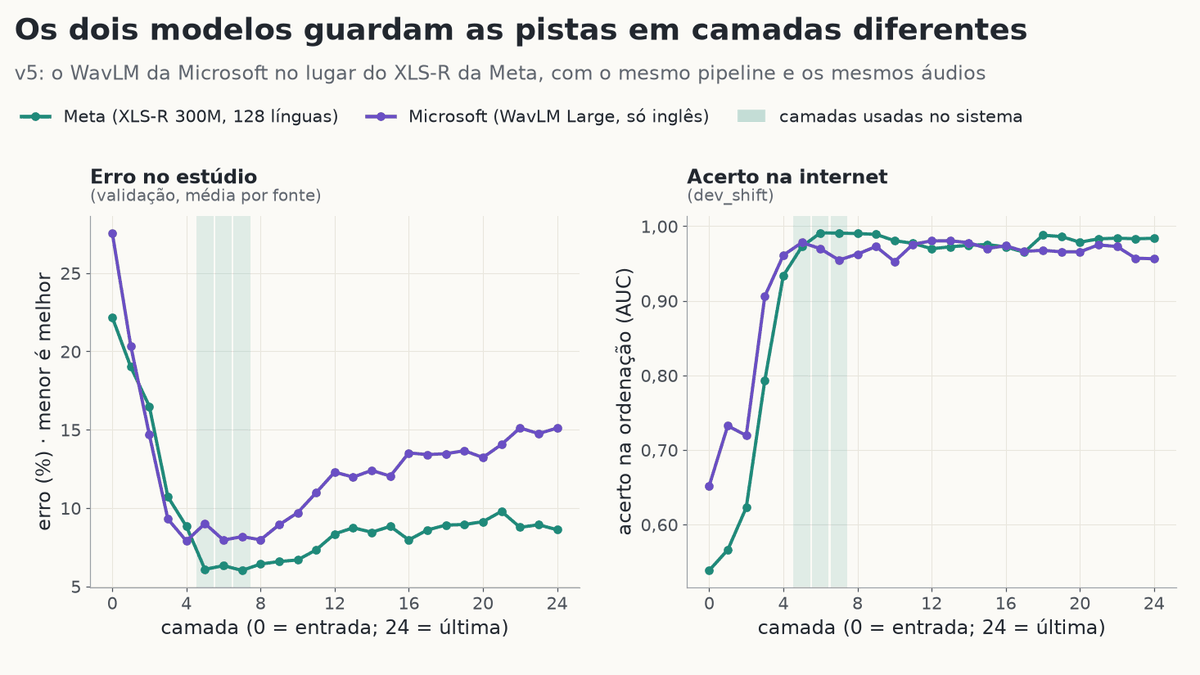

In [31]:
figura("12_meta_microsoft")

**O que olhar:** no WavLM as melhores camadas são as de baixo (3 e 4) e a qualidade cai depois da 8; no XLS-R as camadas 5 a 9 ficam todas boas e as de cima pioram pouco.

**O que concluir:** os dois modelos guardam as pistas em lugares diferentes, e o XLS-R foi melhor no conjunto (sobretudo em português, no teste da v5: BRSpeech-DF AUC 0,842 × 0,768). A explicação (o pré-treino do WavLM a "limpar" ruído descartaria os detalhes acústicos nas camadas de cima) é hipótese, não testada. A v6 refez a comparação nos mesmos áudios e chegou ao mesmo lugar.

**O funil da v6:** cada etapa comparou candidatos pela AUC da pior fonte (validação + dev_shift), com bootstrap por locutor, e só deixava entrar algo mais complexo com diferença relevante.

**O que faz:** mostra `results/v6_funil.csv` e os finalistas F0, F1 e F2 lado a lado no teste, com a acurácia trivial. **Por quê:** é a evidência de por que o notebook voltou ao F0.

In [32]:
fun = pd.read_csv(R / "v6_funil.csv")
display(fun[["etapa", "vencedor", "por quê", "AUC pior fonte (cada candidato)"]])
f012 = pd.read_csv(R / "v4final_f0_f1_f2.csv")
display(Markdown("**F0, F1 e F2 no teste (corte A; F1 = camada 11, C = 1; F2 = F1 + pesos iguais por fonte):**"))
p = f012[f012.limiar == "A"].pivot_table(index="banco", columns="sistema", values=["acurácia", "acurácia balanceada", "AUC", "falso alarme real"], sort=False)
p[("acurácia trivial", "")] = f012[(f012.limiar == "A") & (f012.sistema == "F0")].set_index("banco")["acurácia trivial"]
display(p.round(3))

,etapa,vencedor,por quê,AUC pior fonte (cada candidato)
0,E1 Meta × Microsoft,empate (a E3 decide: fica o mais simples),Microsoft − Meta = -0.0166 (IC95 -0.0481 a +0.0011),Meta (concat_top4): 0.9072; Microsoft (concat_top3): 0.8906; v4 (referência)...
1,E2 fusão,fusão: média das notas,fica fusao_media: fusao_stacking − fusao_media: +0.0004 (IC95 -0.0005 a +0.0...,fusão: média das notas: 0.9051; fusão: stacking: 0.9055; fusão: vetores cola...
2,E3 front-end,só Meta (XLS-R),fica xlsr: wavlm − xlsr: -0.0166 (IC95 -0.0481 a +0.0011) → não relevante; f...,só Meta (XLS-R): 0.9072; só Microsoft (WavLM): 0.8906; fusão: média das nota...
3,E4 cabeças básicas,RL,"fica RL: MLP − RL por seed: +0.0079, +0.0018, -0.0015 → não relevante nas 3;...",RL básica: 0.9037; MLP básico s42: 0.9116; MLP básico s123: 0.9056; MLP bási...
4,E5 maximização,pesos iguais por fonte (sample_weight),pior fonte final 0.9100; regra de limiar A,passo 1: zona de camadas: {'xlsr': [11]}: 0.9037; passo 2: grade ampla de C:...
5,"E6 teste (uma vez, só mostra)",— (o teste não escolhe),F0: média da acurácia nos 3 principais 0.851 (trivial 0.597); F1: média da a...,"F0: v4: XLS-R (Meta) concat_top3 (camadas 5, 6, 7) + RL, C = 0,1: 0.9031; F1..."


**F0, F1 e F2 no teste (corte A; F1 = camada 11, C = 1; F2 = F1 + pesos iguais por fonte):**

acurácia               acurácia balanceada                  AUC               falso alarme real               acurácia trivial
sistema                 F0     F1     F2                  F0     F1     F2     F0     F1     F2                F0     F1     F2                 
banco                                                                                                                                           
in_the_wild          0.836  0.807  0.812               0.835  0.807  0.812  0.979  0.972  0.972             0.318  0.377  0.366            0.500
llamapartialspoof    0.855  0.863  0.863               0.855  0.863  0.863  0.925  0.940  0.937             0.040  0.040  0.043            0.500
brspeech_df          0.863  0.814  0.813               0.679  0.576  0.571  0.842  0.741  0.744             0.636  0.833  0.845            0.791
coraa                0.833  0.588  0.596                 NaN    NaN    NaN    NaN    NaN    NaN             0.167  0.412  0.404            1.000
asvspoof2019_la      0.981  0.975  0.975               0.981  0.975  0.975  0.999  0.997  0.997             0.001  0.006  0.007            0.500
asvspoof2021_df      0.942  0.954  0.950               0.942  0.954  0.950  0.997  0.996  0.996             0.108  0.078  0.088            0.500

**A lição honesta da v6:** o sistema declarado pelo funil (F2) ficou **pior no teste que o F0** (média da acurácia nos 3 principais 0,829 × 0,851; BRSpeech-DF AUC 0,744 × 0,842; CORAA 40,4% × 16,7% de reais acusados no corte A). A validação e o dev_shift (16 locutores) **não distinguiram** os dois: na AUC da pior fonte, F0 0,903 e F2 0,910. Causas prováveis, todas **HIPÓTESES**: (1) F1 e F2 usam **uma** camada (a 11), o F0 usa **três** (5, 6, 7); (2) F1 e F2 usam C = 1 (freio fraco), o F0 usa C = 0,1 (a figura 07 sugere que mais freio generaliza melhor); (3) a "pior fonte" foi sempre o CodecFake+ (352 áudios, inglês, codec), que não representa o português.

## 10. A prova externa: o F0 cai

**Por que esta seção existe.** A seção 10 da versão anterior deste documento recomendava: "antes de apresentar um número final como definitivo, avaliar o F0 **uma vez** num banco nunca visto, com o corte declarado antes". Foi o que fizemos em 13/11, com dois bancos novos, por um protocolo congelado antes (`docs/PROTOCOLO_TESTE_INTERNET.md`; resultado em `docs/RESULTADO_TESTE_INTERNET.md`):
- **RADAR eval**: vozes de IA **comerciais e modernas** (de plataformas), passadas por um **canal degradado simulado** (codecs, ruído, música, compressão), em 6 idiomas; 50.000 reais e 52.725 de IA; **sem locutor no arquivo**.
- **ML-ITW**: vídeos **reais de redes sociais** (YouTube, TikTok, X...), reais e de IA, em 14 idiomas; 18.168 reais e 6.361 de IA, 143 / 160 locutores; o rótulo de IA vem do contexto da postagem.

Nada foi treinado nem ajustado nesses dados: modelo, camadas, C e cortes A e B são os da v4.

### Figura f_00 · O F0 por tipo de áudio

**O que ela mostra:** a AUC do F0 (sistema anterior) em cada tipo de áudio, com o intervalo de confiança de 95% quando existe. Em cinza, bancos que o projeto já usava (validação de estúdio, entrevistas da internet, fala lida com trechos de IA, português de audiolivro); em preto, os dois bancos novos, avaliados uma vez.

*O código abaixo só exibe a figura gerada por `scripts/v7_slides.py` (slide em alta: `results/slides/f_00_queda_externa.png`).*

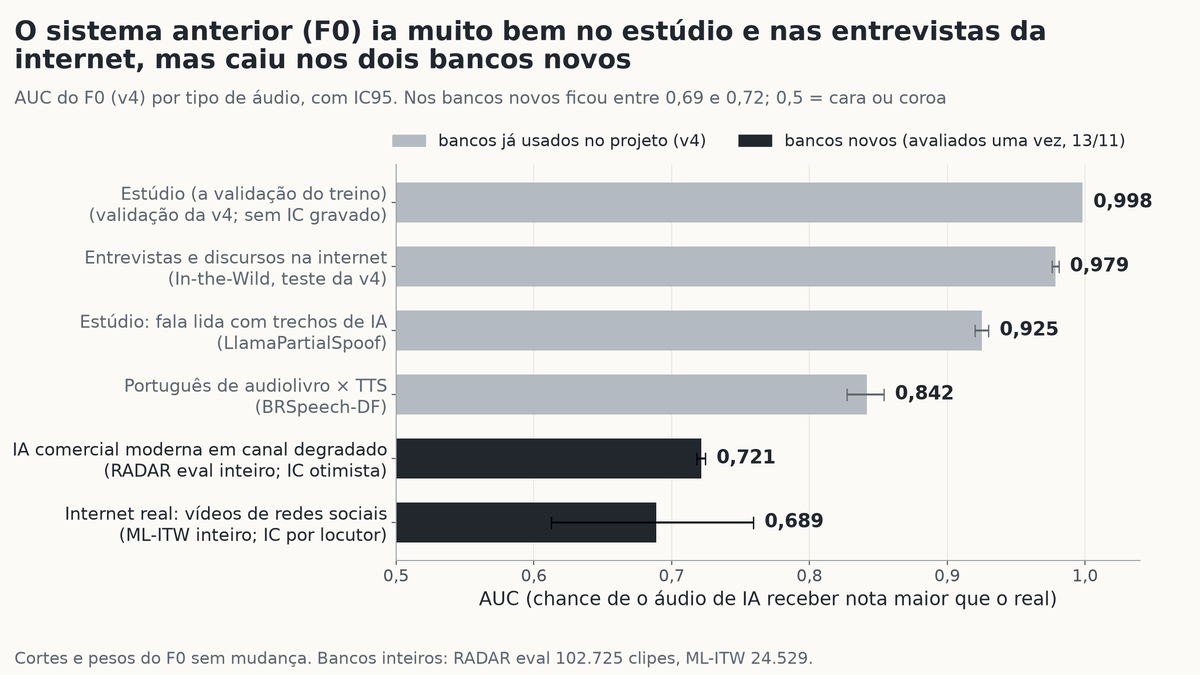

In [33]:
slide("f_00_queda_externa")

**O que olhar:** as barras cinza ficam entre 0,842 e 0,998; as pretas, em 0,721 (RADAR) e 0,689 (ML-ITW). O intervalo do ML-ITW é largo (0,613 a 0,759) porque é por locutor; o do RADAR é estreito, mas otimista (por clipe).

**O que concluir:** o F0 acerta bem o que se parece com o que ele já conhecia e cai nos dois tipos de áudio que nunca viu: IA moderna em canal ruim e vídeos reais de redes sociais. Em palavras: sorteando um áudio real e um de IA, o F0 dá nota maior ao de IA em ~70% das vezes nesses bancos, contra ~98% nas entrevistas da internet.

**O que faz:** mostra a tabela por fonte (AUC, EER, e TPR/FPR nos cortes A e B fixados na v4) e por idioma, lidas de `results/teste_internet_*.csv`. **Por quê:** os números exatos da prova externa.

In [34]:
ti = pd.read_csv(R / "teste_internet_por_fonte.csv")
cols = ["fonte", "n_real", "n_falso", "locutores_real", "locutores_falso", "marca", "AUC", "AUC IC2.5", "AUC IC97.5", "EER",
        "TPR A", "FPR A", "TPR B", "FPR B", "corte_EER_da_fonte"]
display(ti[cols].round(3))
tid = pd.read_csv(R / "teste_internet_por_idioma.csv")
display(Markdown("**Por idioma** (RADAR: IC por clipe, otimista; ML-ITW: < 30 locutores por classe = indício):"))
display(tid[["fonte", "valor", "n_real", "n_falso", "locutores_real", "locutores_falso", "marca", "AUC", "AUC IC2.5", "AUC IC97.5"]].round(3))

,fonte,n_real,n_falso,locutores_real,locutores_falso,marca,AUC,AUC IC2.5,AUC IC97.5,EER,TPR A,FPR A,TPR B,FPR B,corte_EER_da_fonte
0,radar_eval,50000,52725,NaN,NaN,IC otimista (sem locutor no arquivo),0.721,0.718,0.725,0.339,0.569,0.236,0.247,0.042,-2.331
1,ml_itw,18168,6361,143.0,160.0,estimativa,0.689,0.613,0.759,0.355,0.404,0.135,0.145,0.032,-5.942


**Por idioma** (RADAR: IC por clipe, otimista; ML-ITW: < 30 locutores por classe = indício):

,fonte,valor,n_real,n_falso,locutores_real,locutores_falso,marca,AUC,AUC IC2.5,AUC IC97.5
0,radar_eval,en,15000,17923,NaN,NaN,IC otimista (sem locutor no arquivo),0.724,0.718,0.730
1,radar_eval,en-sg,3500,6711,NaN,NaN,IC otimista (sem locutor no arquivo),0.747,0.738,0.757
2,radar_eval,ja,9500,8741,NaN,NaN,IC otimista (sem locutor no arquivo),0.692,0.684,0.699
3,radar_eval,vi,7000,6438,NaN,NaN,IC otimista (sem locutor no arquivo),0.796,0.788,0.803
4,radar_eval,zh,11500,11234,NaN,NaN,IC otimista (sem locutor no arquivo),0.695,0.687,0.702
5,radar_eval,zh-tw,3500,1678,NaN,NaN,IC otimista (sem locutor no arquivo),0.665,0.649,0.681
6,ml_itw,chinese,5399,3074,52.0,62.0,estimativa,0.679,0.518,0.816
7,ml_itw,english,6931,1598,42.0,50.0,estimativa,0.652,0.525,0.771
8,ml_itw,french,195,61,2.0,3.0,"indício, não estimativa (< 30 locutores por classe)",0.855,0.622,0.949
9,ml_itw,german,704,356,5.0,5.0,"indício, não estimativa (< 30 locutores por classe)",0.756,0.612,0.909


**Os cortes A e B.** O corte **A** (calibrado no estúdio) pega 57% dos falsos do RADAR e 40% dos do ML-ITW, mas acusa 24% e 14% dos reais. O corte **B** (calibrado nas entrevistas da internet) quase não acusa reais (4,2% e 3,2%), mas **deixa passar 75% dos falsos do RADAR e 85% dos do ML-ITW**: de cada 4 falsos, 3 passam como reais. O corte que daria o ponto de EER em cada banco fica **abaixo dos dois** (RADAR −2,33; ML-ITW −5,94): nesses áudios, os falsos recebem notas mais baixas do que o F0 espera.

### Figura ti_04 · Onde os cortes A e B caem na curva ROC

**O que ela mostra:** para cada corte possível, a % de reais acusados (eixo x) e a % de falsos detectados (eixo y), nos dois bancos novos, com os pontos dos cortes A e B.

*O código abaixo só exibe a figura gerada por `scripts/teste_internet_figuras.py` (slide em alta: `results/slides/ti_04_roc.png`).*

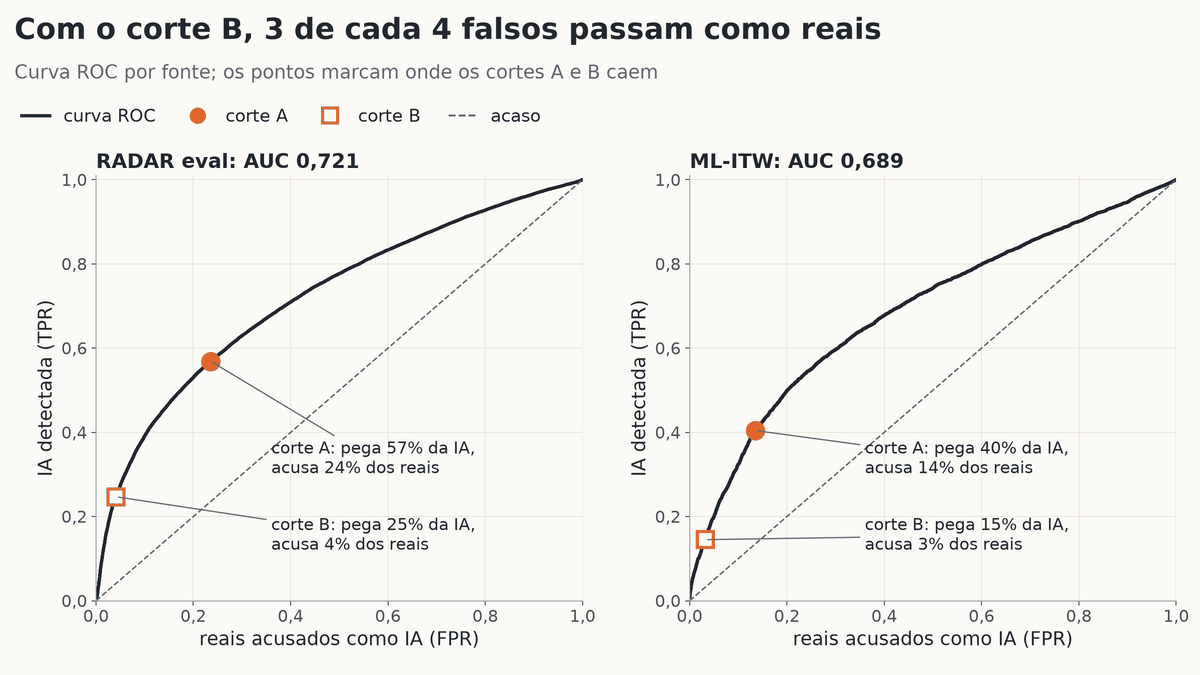

In [35]:
slide("ti_04_roc")

**O que olhar:** o ponto do corte B fica embaixo, à esquerda: quase nenhum real acusado, mas poucos falsos detectados.

**O que concluir:** um corte escolhido em outro ambiente não serve aqui; é o primeiro sinal de que **a escala da nota muda entre ambientes** (seção 15).

**Auditoria de atalho e de duração.** Antes de culpar o modelo, conferimos se a queda vinha de algo trivial:
- **Duração:** no RADAR, os falsos são um pouco mais longos. Pareando reais e falsos por faixa de 0,5 s (mesmo número por faixa; 20 sorteios), a AUC fica em **0,720** (contra 0,721 no banco original): **a duração não explica a queda**.
- **Atalho por metadados:** uma regressão logística que só vê duração, silêncio nas bordas, volume (RMS), pico e tamanho do arquivo chega a **0,665** no RADAR e **0,633** no ML-ITW. Fica abaixo da regra de alerta (0,7), mas **perto do F0** (a 0,06 a 0,07): nesses bancos, parte da diferença real × IA está em características de gravação, e o F0 não estava muito acima disso.

### Figura ti_05 · O sistema × um classificador que só vê metadados

**O que ela mostra:** a AUC do F0 ao lado da AUC de um classificador que só olha metadados (duração, silêncio, volume, tamanho), nos dois bancos novos.

*O código abaixo só exibe a figura gerada por `scripts/teste_internet_figuras.py` (slide em alta: `results/slides/ti_05_atalho.png`).*

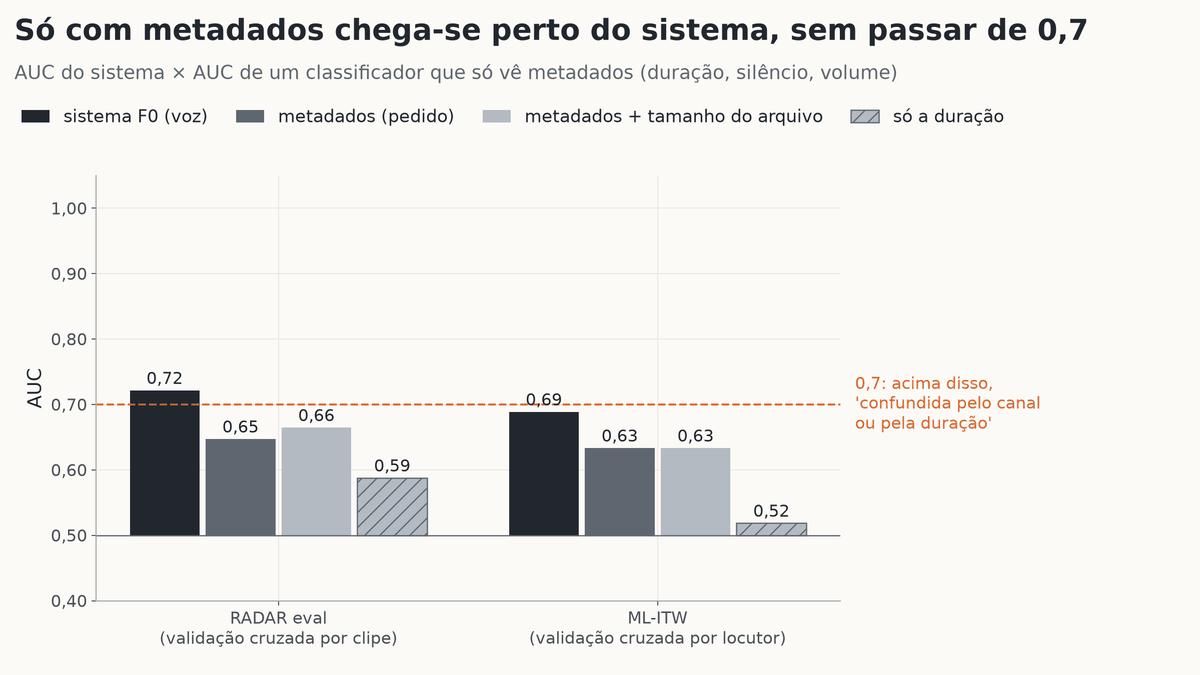

In [36]:
slide("ti_05_atalho")

**O que olhar:** as barras dos metadados ficam abaixo de 0,7, mas perto das do F0.

**O que concluir:** não há um atalho forte que explique tudo, mas o F0 quase não passava de "características de gravação" nesses bancos. Esse foi o motivo para a v7 tentar ensinar o sistema com esse tipo de áudio.

### Figura ti_03 · A duração não explica a queda

**O que ela mostra:** a AUC do F0 por faixa de duração original e no RADAR com durações pareadas entre reais e falsos.

*O código abaixo só exibe a figura gerada por `scripts/teste_internet_figuras.py` (slide em alta: `results/slides/ti_03_duracao.png`).*

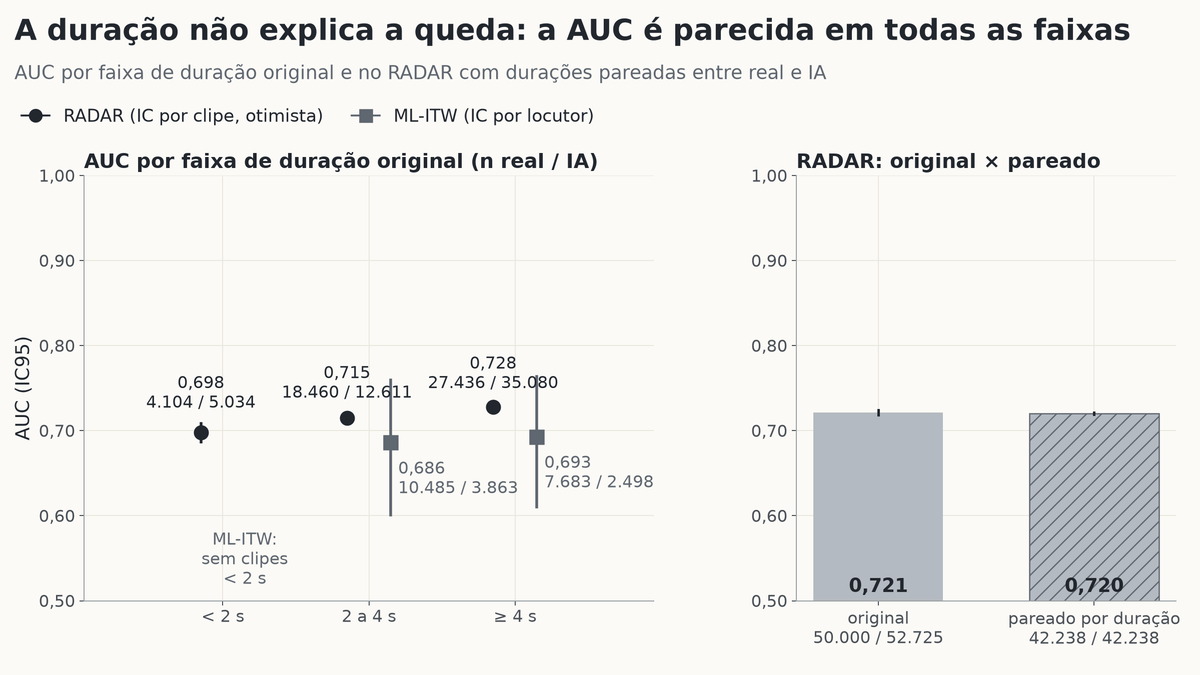

In [37]:
slide("ti_03_duracao")

**O que olhar:** as faixas ficam todas perto de 0,7; os clipes curtos são um pouco piores, como na v4.

**O que concluir:** a queda é geral, não é efeito de clipes curtos nem da diferença de duração entre as classes.

**Conclusão da seção 10:** o F0 foi bem onde já tinha sido medido e **caiu nos dois bancos novos** (AUC ~0,7), em todos os idiomas, inclusive o inglês. Os cortes da v4 não servem ali. Duração e metadados não explicam a queda. Esses dois bancos ficaram **consumidos como teste do F0**: qualquer mudança feita olhando para eles os contamina, e por isso a v7 os redividiu com um protocolo próprio (seção 11).

## 11. v7: o novo desenho dos dados

**Por que mudar.** O F0 só tinha visto inglês de estúdio e audiolivro e caiu nos dois tipos de áudio novos (seção 10). A pergunta da v7 é simples: **se o treino da regressão incluir uma parte desses áudios, o sistema melhora nos outros áudios do mesmo tipo, que ele não viu?** Para responder sem se enganar, três regras, escritas e **congeladas antes do treino** em `docs/PROTOCOLO_V7.md`:
1. **Separar por locutor e por idioma.** No ML-ITW, cada locutor vai inteiro para um lado só (locutor atômico). O RADAR não informa o locutor, então foi separado **por idioma**.
2. **Um teste mestre fixo**, o mesmo para todas as receitas, escolhido antes de treinar.
3. **A receita é escolhida pela validação**, antes de abrir o teste; o teste mostra todas.

**Como cada banco foi dividido** (`docs/PROTOCOLO_V7.md`, seção 2):
- **Estúdio (os dados da v4):** treino = os mesmos 40.000 da v4; validação = os 19.999 da v4 **menos 13** (duplicatas, seção 12) = 19.986. Nada do estúdio vai para o teste mestre.
- **Internet real (ML-ITW), nesta ordem:** (1) locutor com **algum áudio em português** → inteiro no teste mestre (8 locutores, 1.178 clipes); (2) locutor com **uma classe só** → teste mestre (55 locutores); (3) as **3 pessoas que também estão no In-the-Wild** (figuras públicas; cruzamento por nome) → o lado delas no In-the-Wild (2 na validação, 1 no teste mestre); (4) os demais locutores com as duas classes → **sorteio por locutor** (seed 42), 60% treino / 15% validação / 25% teste mestre, estratificado pelo idioma principal (chinês, inglês, outro): 68 / 17 / 29 locutores.
- **IA moderna em canal degradado (RADAR):** treino = chinês (zh), chinês de Taiwan (zh-tw) e japonês (ja); validação = inglês de Singapura (en-sg) e vietnamita (vi); **teste mestre = inglês (en)**. No treino, só a versão com **durações pareadas** (mesmo número de reais e de IA por faixa de 0,5 s, dentro de cada idioma): 15.316 / 15.316 de 24.500 / 21.653. O **dev do RADAR nunca é usado** (nem foi baixado).
- **Entrevistas e discursos (In-the-Wild):** nunca no treino; os 16 locutores do dev_shift vão para a **validação**; os 38 do `test_final` (a amostra de 10.000 clipes da v4) para o **teste mestre**.
- **Controles de esquecimento:** os 5 testes antigos de estúdio e português da v4 (21.320 reais / 20.000 de IA), fora da métrica principal.

**O ajuste do bloco inglês.** O inglês do RADAR (en) foi reservado **inteiro** para o teste mestre, e os idiomas da validação (en-sg e vi) também ficaram fora do treino. Assim, o RADAR en no teste mede **"idioma novo, com a mesma fonte, os mesmos geradores e o mesmo canal do treino"**. O protocolo define ainda um **bloco inglês** à parte (seção 13): RADAR en (natural e pareado por duração), internet real **só em inglês**, In-the-Wild e os controles de estúdio em inglês.

**O que NÃO entra no treino de nenhuma receita** (pelo protocolo):
- o **In-the-Wild** inteiro (entrevistas e discursos): é o único banco que **nenhuma** receita vê;
- **todo o português**: os locutores do ML-ITW com algum áudio em português vão inteiros para o teste mestre; BRSpeech-DF e CORAA são controles;
- do RADAR: o **inglês (en)**, o **inglês de Singapura (en-sg)** e o **vietnamita (vi)**; o **dev** do RADAR. (O **japonês (ja) entra no treino**, junto com zh e zh-tw.)
- do ML-ITW: os locutores de uma classe só e as 3 pessoas que também estão no In-the-Wild;
- os controles de estúdio e os 13 clipes excluídos.

### Figura f_02 · O desenho dos dados da v7

**O que ela mostra:** para cada tipo de fonte (linhas) e cada lado (colunas: treino, validação, teste mestre), o número de clipes reais / de IA, a proporção (barra azul = real, laranja = IA) e o número de locutores. "Não entra" = nada daquela fonte naquele lado.

*O código abaixo só exibe a figura gerada por `scripts/v7_slides.py` (slide em alta: `results/slides/f_02_desenho_dos_dados.png`).*

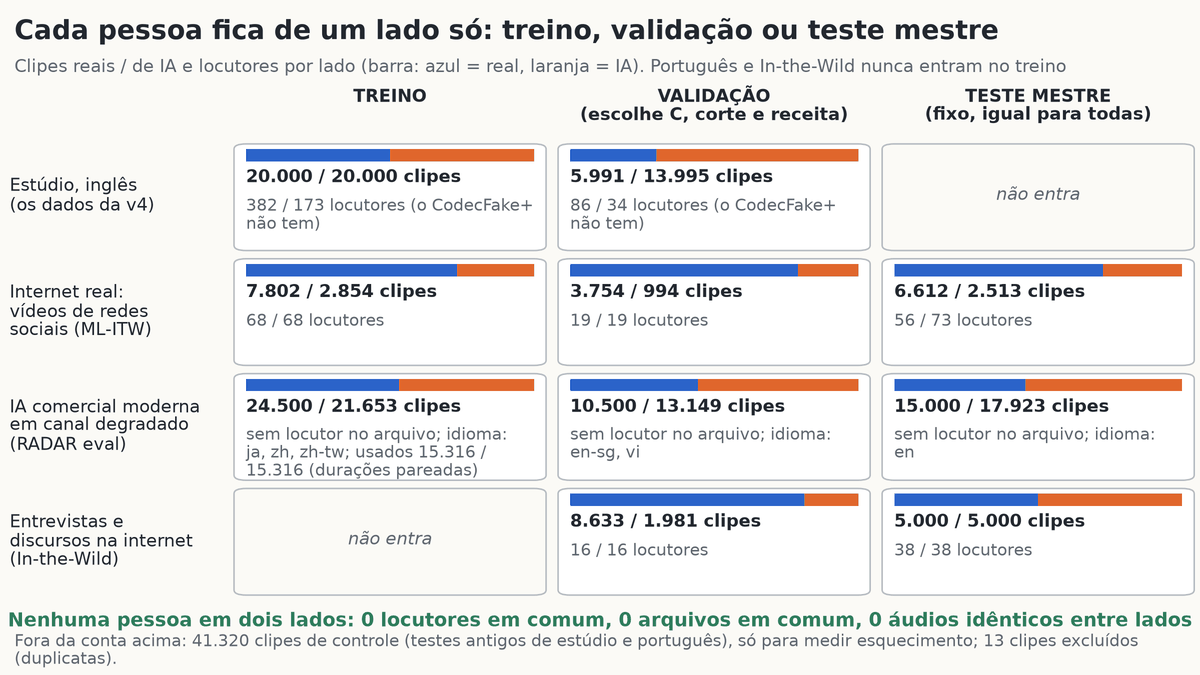

In [38]:
slide("f_02_desenho_dos_dados")

**O que olhar:** o estúdio só aparece no treino e na validação; a internet real e o RADAR aparecem nos três lados; as entrevistas da internet nunca aparecem no treino. A faixa verde embaixo resume as travas: nenhuma pessoa, nenhum arquivo e nenhum áudio idêntico em dois lados.

**O que concluir:** o treino da v7 é o do F0 **mais** uma parte dos dois bancos novos; o teste mestre tem outras pessoas (internet real) e outro idioma (RADAR) do que o treino.

**O que faz:** mostra as contagens de clipes e locutores por bloco e lado (`results/v7_splits_contagens.csv`) e as regras do ML-ITW (`results/v7_splits_mlitw_regras.csv`; os nomes das 3 pessoas públicas são trocados por uma descrição). **Por quê:** a tabela exata por trás da figura.

In [39]:
cont = pd.read_csv(R / "v7_splits_contagens.csv")
t = cont.pivot_table(index=["bloco", "split"], columns="classe", values=["clipes", "locutores", "clipes_pareados_treino",
                                                                        "clipes_pareados_teste"], aggfunc="sum")
display(t.fillna("—"))
reg = pd.read_csv(R / "v7_splits_mlitw_regras.csv")
reg["regra"] = reg.regra.str.replace(r"^\(3\).*$", "(3) mesma pessoa que um locutor do In-the-Wild (figura pública)", regex=True)
display(reg.groupby(["regra", "split"], as_index=False)[["locutores", "clipes", "falsos"]].sum())

clipes        clipes_pareados_teste          clipes_pareados_treino          locutores      
classe                    falso   real                 falso     real                  falso     real     falso  real
bloco       split                                                                                                    
controle    controle      20000  21320                   0.0      0.0                    0.0      0.0       0.0   0.0
estudio     excluido          0     13                   0.0      0.0                    0.0      0.0       0.0   0.0
            treino        20000  20000                   0.0      0.0                    0.0      0.0       0.0   0.0
            validacao     13995   5991                   0.0      0.0                    0.0      0.0       0.0   0.0
in_the_wild teste_mestre   5000   5000                   0.0      0.0                    0.0      0.0      38.0  38.0
            validacao      1981   8633                   0.0      0.0                    0.0      0.0      16.0  16.0
ml_itw      teste_mestre   2513   6612                   0.0      0.0                    0.0      0.0      73.0  56.0
            treino         2854   7802                   0.0      0.0                    0.0      0.0      68.0  68.0
            validacao       994   3754                   0.0      0.0                    0.0      0.0      19.0  19.0
radar_eval  teste_mestre  17923  15000               14291.0  14291.0                    0.0      0.0       0.0   0.0
            treino        21653  24500                   0.0      0.0                15316.0  15316.0       0.0   0.0
            validacao     13149  10500                   0.0      0.0                    0.0      0.0       0.0   0.0

,regra,split,locutores,clipes,falsos
0,(1) tem áudio em português,teste_mestre,8,1178,135
1,(2) uma classe só,teste_mestre,55,4052,1557
2,(3) mesma pessoa que um locutor do In-the-Wild (figura pública),teste_mestre,1,5,5
3,(3) mesma pessoa que um locutor do In-the-Wild (figura pública),validacao,2,608,293
4,"(4) sorteio estratificado por locutor (grupo de idioma 'chinese', seed 42, 6...",teste_mestre,11,1713,341
5,"(4) sorteio estratificado por locutor (grupo de idioma 'chinese', seed 42, 6...",treino,28,3426,1217
6,"(4) sorteio estratificado por locutor (grupo de idioma 'chinese', seed 42, 6...",validacao,7,1816,271
7,"(4) sorteio estratificado por locutor (grupo de idioma 'english', seed 42, 6...",teste_mestre,8,960,155
8,"(4) sorteio estratificado por locutor (grupo de idioma 'english', seed 42, 6...",treino,17,4581,967
9,"(4) sorteio estratificado por locutor (grupo de idioma 'english', seed 42, 6...",validacao,4,819,31


**As 5 receitas e a pergunta que cada uma responde** (o modelo é sempre o mesmo: XLS-R congelado, camadas 5, 6, 7, regressão logística; muda só o treino):

| receita | treino | peso | C (pela validação) | pergunta |
|:--|:--|:--|:--|:--|
| **T0** | o F0 sem retreinar (os 40.000 de estúdio) | nenhum | 0,1 (da v4) | quanto o sistema anterior acerta no teste mestre? (a referência) |
| **T1** | estúdio + internet real (10.656 clipes) | classes balanceadas | 0,001 | a internet real ajuda? e ajuda no RADAR, que ela não viu? |
| **T2** | estúdio + IA moderna em canal degradado (30.632 clipes pareados) | classes balanceadas | 0,01 | o RADAR ajuda? e ajuda na internet real, que ele não viu? |
| **T3** | estúdio + os dois (81.288 clipes) | classes balanceadas | 0,01 | juntar os dois é melhor que cada um sozinho? |
| **T4** | o mesmo da T3 | **peso igual por fonte** (estúdio, internet real e RADAR somam o mesmo) | 0,01 | impedir que o estúdio (o maior) domine muda alguma coisa? |

O C de cada receita foi escolhido na grade 0,0001 a 10 pela **maior média da AUC por fonte na validação** (6 fontes: DFADD, ShiftySpeech, CodecFake+, In-the-Wild dev, ML-ITW validação, RADAR validação).

## 12. Como evitamos vazamento

**A regra da mesma pessoa e do mesmo corpus.** Se a mesma pessoa aparece no treino e no teste, o modelo pode acertar o teste por **reconhecer a voz** (ou o microfone, a sala, o canal daquela pessoa), e não por distinguir real de IA. O número fica otimista sem ninguém perceber. Por isso, na internet real e nas entrevistas, **todo o áudio de um locutor fica de um lado só**, e as pessoas que aparecem nos dois bancos (cruzamento **por nome**: 3 figuras públicas) foram tratadas como **a mesma pessoa** e postas no lado delas no In-the-Wild. O mesmo vale para o corpus: nada do dev do RADAR (que repete dados de outros bancos) foi usado.

**As travas automáticas** (`scripts/v7.py splits`; cada uma é um teste no código: se falha, a divisão para e grava `logs/v7_BLOQUEIO.txt`):

| trava | o que verifica | resultado (`results/v7_splits.json`) |
|:--|:--|:--|
| caminho | o mesmo arquivo em dois lados | **0** em comum |
| locutor | a mesma pessoa em dois lados (ML-ITW e In-the-Wild, com as 3 pessoas coincidentes mapeadas) | **0** em comum |
| duplicata exata | o vetor do áudio idêntico (hash) entre treino, validação e teste | **parou a 1ª execução**; depois da correção, **0** |
| duplicata quase exata | cosseno ≥ 0,9995 entre treino/validação e teste mestre (internet real e entrevistas) | **0** pares; o máximo entre lados foi 0,965 |
| dev do RADAR | nenhum clipe do dev | conferido: nenhum clipe (todos com original_split = eval e caminho RADAR2026-eval) |

**O que a trava achou.** Na 1ª execução, a trava de duplicata exata **parou a divisão**: 12 grupos de áudios **reais do CodecFake+** (o mesmo áudio de referência repetido em pastas de geradores diferentes) tinham vetor idêntico entre o **treino** e a **validação de estúdio da v4**. É herança do plano da v4, não da v7. Como o treino de estúdio é fixo (os 40.000 da v4), os **13 clipes da validação** envolvidos foram **excluídos da avaliação** (`split = "excluido"`), e a divisão rodou de novo sem nenhum aviso. Desvio registrado no protocolo: a regra pedia "mover o par para o mesmo lado", o que mudaria o treino da v4.

**O RADAR foi dividido por idioma** porque o arquivo não traz o locutor: não dá para garantir que a mesma pessoa não está em dois idiomas. Separar por idioma é o melhor possível com o que existe, e o IC do RADAR é marcado como **otimista**.

**Protocolo antes do treino.** O protocolo foi congelado às 19:36 de 2026-11-13, **antes** de qualquer treino; a divisão tem SHA256 `24d3aea93654…` (conferido de novo por `scripts/v7_t3_exportar.py`); a escolha pela validação foi gravada às 19:41:00 (`results/v7_escolha.json`), antes do teste; cada receita foi avaliada no teste mestre **uma vez**.

### Figura f_08 · As travas contra vazamento

**O que ela mostra:** cada trava automática, o que ela verifica e o resultado, lidos de `results/v7_splits.json`.

*O código abaixo só exibe a figura gerada por `scripts/v7_slides.py` (slide em alta: `results/slides/f_08_anti_vazamento.png`).*

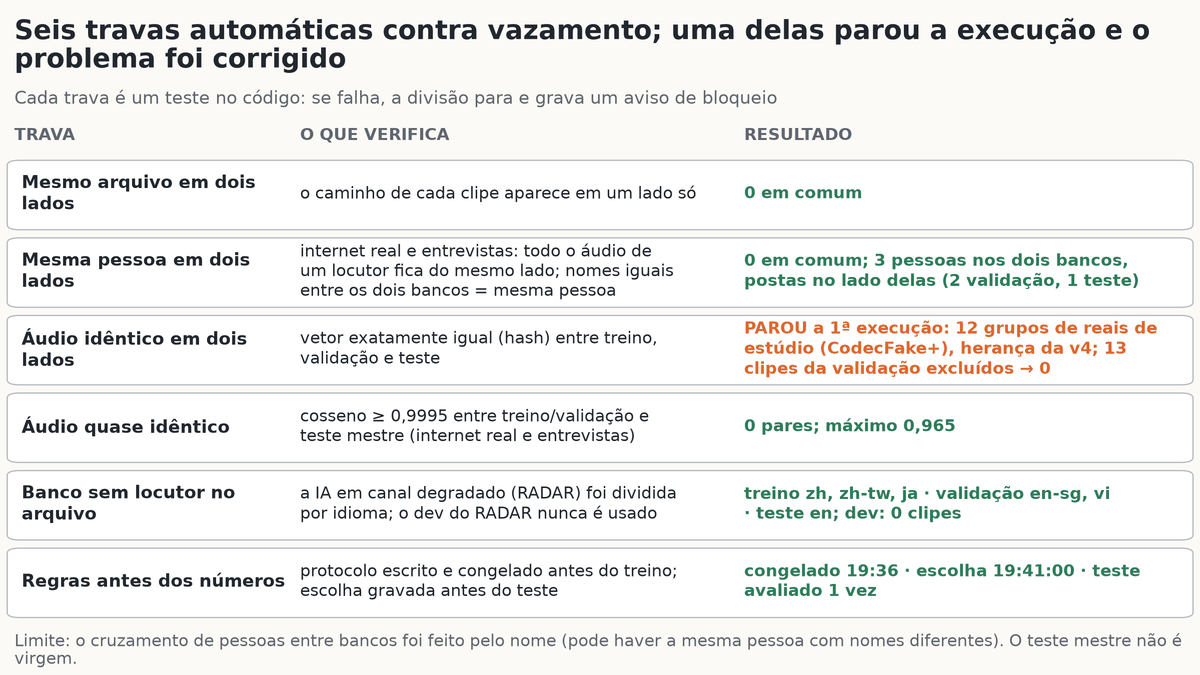

In [40]:
slide("f_08_anti_vazamento")

**O que olhar:** a linha laranja: a única trava que disparou, o que ela achou e como foi resolvido.

**O que concluir:** as travas funcionaram (uma delas pegou um problema herdado da v4). O limite que sobra: o cruzamento de pessoas entre bancos foi feito **pelo nome**, e o RADAR não tem locutor.

**O que faz:** mostra o bloco de salvaguardas de `results/v7_splits.json`, sem os caminhos e sem os nomes das pessoas. **Por quê:** os números da tabela acima vêm daqui.

In [41]:
sj = ler(R / "v7_splits.json")["salvaguardas"]
resumo = {k: v for k, v in sj.items() if k not in ("coincidentes", "duplicatas_exatas_excluidas_da_avaliacao", "quase_duplicatas_pares")}
resumo["pessoas coincidentes entre os bancos (nº) e lado"] = sorted(sum(sj["coincidentes"].values(), []))
resumo["clipes excluídos (duplicatas exatas)"] = len(sj["duplicatas_exatas_excluidas_da_avaliacao"])
resumo["fonte dos excluídos"] = sorted({d["fonte"] for d in sj["duplicatas_exatas_excluidas_da_avaliacao"]})
display(pd.Series(resumo, name="valor").astype(str).to_frame())

,valor
caminhos_em_comum,0
locutores_em_comum,0
duplicatas_exatas_entre_lados,0
duplicatas_exatas_controle_x_outros_lados (informativo),0
quase_duplicatas_criterio,cosseno >= 0.9995 entre vetores padronizados pela média e desvio do treino d...
cosseno_maximo_entre_lados,0.9649313688278198
dev_do_radar,nenhum clipe (todos com original_split = eval e caminho RADAR2026-eval)
avisos,[]
pessoas coincidentes entre os bancos (nº) e lado,"['teste_mestre', 'validacao', 'validacao']"
clipes excluídos (duplicatas exatas),13


## 13. Resultados da v7

### 13.1 A escolha pela validação (antes do teste)

A receita vencedora é a de **maior média da AUC por fonte na validação**: T0 0,904, T1 0,945, T2 0,963, **T3 0,975**, T4 0,973. Venceu a **T3**, gravada às 19:41:00, antes de o teste ser aberto. A T4 ficou a 0,002: seria empate se o protocolo tivesse margem, mas ele não tinha.

**O que faz:** mostra a AUC por fonte na validação e a grade de C de cada receita. **Por quê:** é a decisão, com os números exatos.

In [42]:
display(pd.read_csv(R / "v7_validacao.csv").round(3))
gc = pd.read_csv(R / "v7_grade_c.csv")
display(gc.pivot(index="C", columns="receita", values="AUC val média por fonte").round(4))

,receita,descrição,AUC codecfake_plus,AUC dfadd,AUC in_the_wild,AUC ml_itw,AUC radar_eval,AUC shiftyspeech,AUC média por fonte,AUC pior fonte,pior fonte
0,T0,F0 sem retreinar,0.896,1.0,0.983,0.769,0.779,0.997,0.904,0.769,ml_itw
1,T1,estúdio + ML-ITW,0.905,1.0,0.994,0.945,0.832,0.996,0.945,0.832,radar_eval
2,T2,estúdio + RADAR,0.934,1.0,0.990,0.893,0.972,0.986,0.963,0.893,ml_itw
3,T3,estúdio + ML-ITW + RADAR,0.939,1.0,0.991,0.960,0.973,0.986,0.975,0.939,codecfake_plus
4,T4,"T3, peso igual por fonte",0.937,1.0,0.989,0.961,0.968,0.981,0.973,0.937,codecfake_plus


receita,T0,T1,T2,T3,T4
C,,,,,
0.0001,NaN,0.9406,0.9523,0.9666,0.9681
0.0010,NaN,0.9454,0.9596,0.9726,0.9723
0.0100,NaN,0.9425,0.9625,0.9750,0.9728
0.1000,0.9041,0.9342,0.9616,0.9745,0.9721
1.0000,NaN,0.9289,0.9568,0.9720,0.9700
10.0000,NaN,0.9276,0.9532,0.9705,0.9688


### 13.2 O teste mestre: a métrica principal

A métrica principal é a **média da AUC** em três fontes do teste mestre: **internet real** (ML-ITW, outros locutores), **entrevistas e discursos** (In-the-Wild, 38 locutores, nunca visto) e **IA moderna em canal degradado** (RADAR en, idioma novo). Também a **pior fonte**.

| receita | média (IC95) | pior fonte | internet real | entrevistas | RADAR en |
|:--|:--|:--|:--|:--|:--|
| T0 | 0,764 (0,730 a 0,798) | 0,588 | 0,588 | 0,979 | 0,724 |
| T1 | 0,909 (0,892 a 0,921) | 0,810 | 0,923 | 0,994 | 0,810 |
| T2 | 0,940 (0,922 a 0,955) | 0,882 | 0,882 | 0,983 | 0,955 |
| **T3** ★ | 0,963 (0,950 a 0,973) | 0,939 | 0,939 | 0,986 | 0,964 |
| T4 | 0,963 (0,952 a 0,972) | 0,948 | 0,948 | 0,985 | 0,958 |

★ = escolhida pela validação. **Visto × não visto:** a internet real foi vista por T1, T3 e T4 (outros locutores); o RADAR (outro idioma) por T2, T3 e T4; as entrevistas **nunca**. Diferença T3 − T0 na média: +0,200 (IC95 pareado +0,168 a +0,232). **Atenção:** o F0 aqui é medido no **teste mestre** (um subconjunto fixo), por isso a internet real dá 0,588 e não 0,689 (banco inteiro, seção 10).

### Figura f_01 · Antes e depois: F0 × T3 por tipo de áudio

**O que ela mostra:** para cada tipo de áudio, a AUC do F0 (cinza) e da T3 (vinho) no teste mestre, com IC95. Ponto vinho cheio = tipo de áudio que a T3 **nunca viu** no treino; ponto claro com contorno = tipo visto (outros locutores do mesmo banco, ou outro idioma da mesma fonte).

*O código abaixo só exibe a figura gerada por `scripts/v7_slides.py` (slide em alta: `results/slides/f_01_antes_depois.png`).*

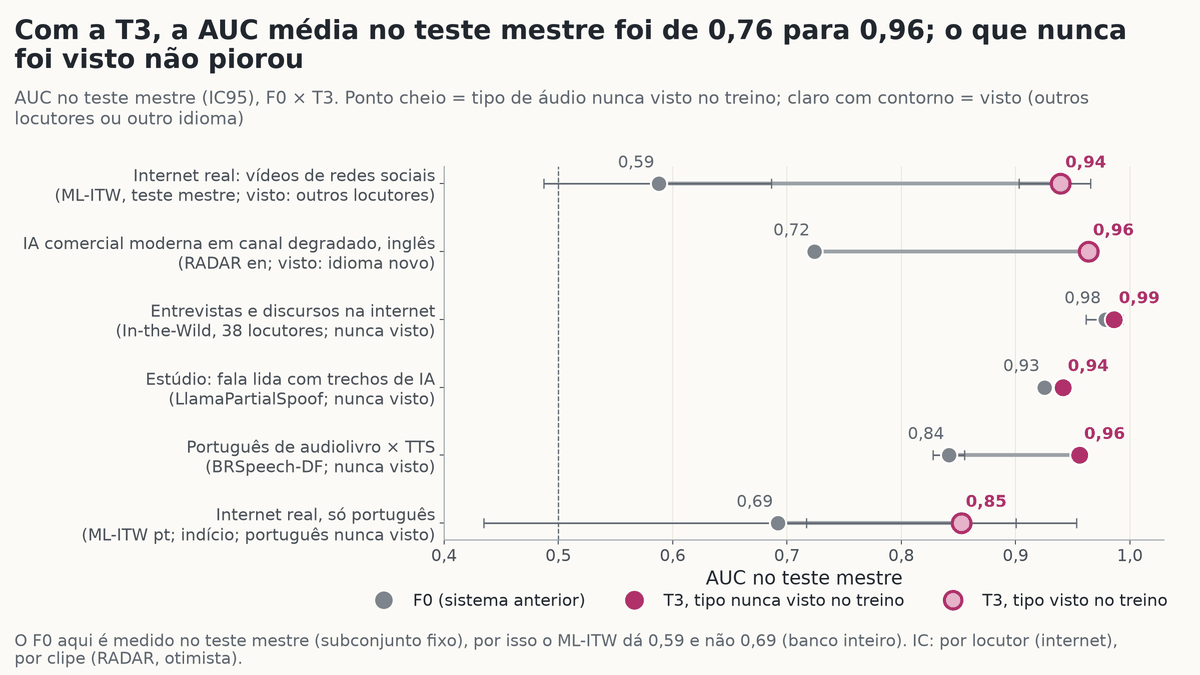

In [43]:
slide("f_01_antes_depois")

**O que olhar:** os dois saltos grandes são nos tipos vistos: internet real 0,59 → 0,94 e RADAR en 0,72 → 0,96. Nos nunca vistos, as entrevistas ficam onde estavam (0,98 → 0,99) e o português de audiolivro sobe (0,84 → 0,96).

**O que concluir:** onde o tipo de áudio foi visto, a AUC sobe muito; onde não foi, não piora. Isso é bom, mas **não é a mesma coisa que generalizar para geradores novos** (seção 14).

### Figura f_03 · As 5 receitas, fonte por fonte

**O que ela mostra:** a AUC de cada receita (T0 a T4) em cada fonte do teste mestre e em dois controles. Barra clara e hachurada = a receita viu aquele tipo de áudio no treino; barra cheia = não viu.

*O código abaixo só exibe a figura gerada por `scripts/v7_slides.py` (slide em alta: `results/slides/f_03_receitas.png`).*

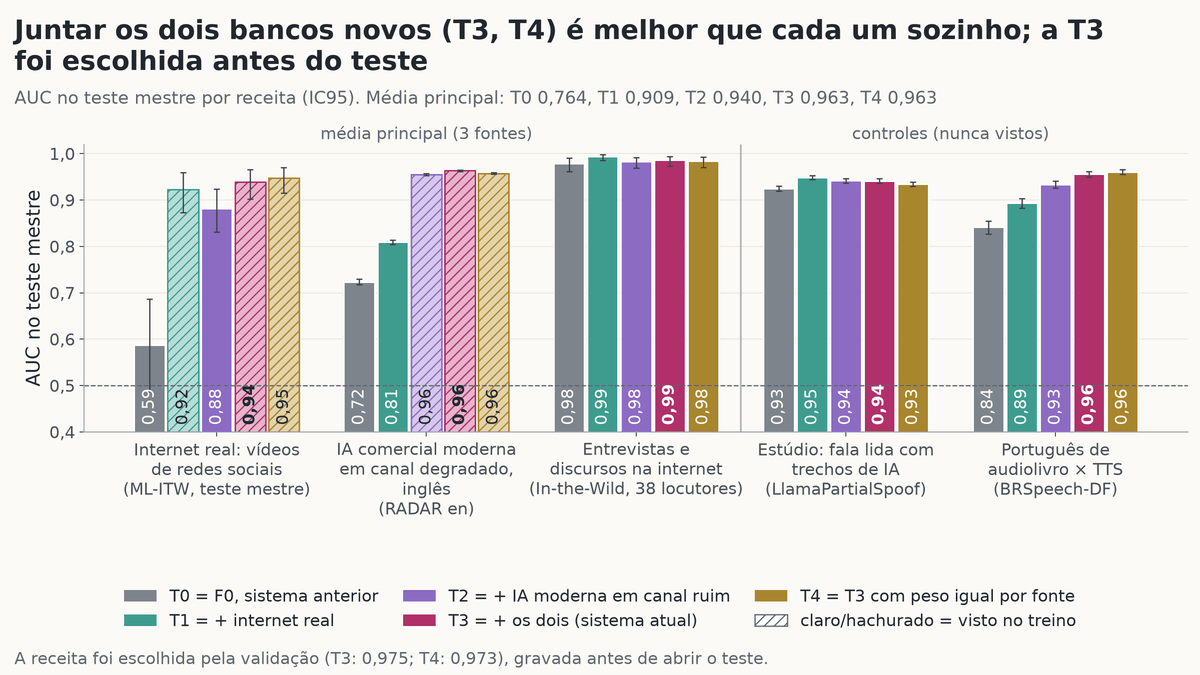

In [44]:
slide("f_03_receitas")

**O que olhar:** T1 é fraca no RADAR (0,81) e T2 é mais fraca na internet real (0,88); T3 e T4 ficam altas nas duas; as entrevistas mudam pouco em todas.

**O que concluir:** **juntar os dois bancos é melhor que cada um sozinho**; T3 e T4 empatam na média (0,963 × 0,963): o peso igual por fonte não mudou nada demonstrável.

**O que faz:** mostra a tabela principal (`results/v7_principal.csv`) e o teste mestre completo de cada receita (AUC, IC95, TPR e FPR nas três regras de corte). **Por quê:** os números exatos por trás das figuras.

In [45]:
pr = pd.read_csv(R / "v7_principal.csv")
display(pr[["receita", "descrição", "média AUC (3 fontes)", "média IC2.5", "média IC97.5", "pior fonte", "AUC pior fonte",
            "AUC ml_itw", "AUC in_the_wild", "AUC radar_en", "dif. média vs T0", "dif. média vs T0 IC2.5",
            "dif. média vs T0 IC97.5", "vencedora pela validação"]].round(3))
tm = pd.read_csv(R / "v7_teste_mestre.csv")
cols = ["receita", "recorte", "domínio", "n_real", "n_falso", "locutores_real", "locutores_falso", "marca", "AUC",
        "AUC IC2.5", "AUC IC97.5", "regra escolhida (validação)", "TPR A'", "FPR A'", "TPR M", "FPR M", "TPR F5", "FPR F5"]
display(tm[tm.papel == "principal"][cols].round(3))

,receita,descrição,média AUC (3 fontes),média IC2.5,média IC97.5,pior fonte,AUC pior fonte,AUC ml_itw,AUC in_the_wild,AUC radar_en,dif. média vs T0,dif. média vs T0 IC2.5,dif. média vs T0 IC97.5,vencedora pela validação
0,T0,F0 sem retreinar,0.764,0.730,0.798,ml_itw,0.588,0.588,0.979,0.724,0.000,0.000,0.000,False
1,T1,estúdio + ML-ITW,0.909,0.892,0.921,radar_en,0.810,0.923,0.994,0.810,0.145,0.115,0.174,False
2,T2,estúdio + RADAR,0.940,0.922,0.955,ml_itw,0.882,0.882,0.983,0.955,0.177,0.144,0.210,False
3,T3,estúdio + ML-ITW + RADAR,0.963,0.950,0.973,ml_itw,0.939,0.939,0.986,0.964,0.200,0.168,0.232,True
4,T4,"T3, peso igual por fonte",0.963,0.952,0.972,ml_itw,0.948,0.948,0.985,0.958,0.200,0.168,0.232,False


,receita,recorte,domínio,n_real,n_falso,locutores_real,locutores_falso,marca,AUC,AUC IC2.5,AUC IC97.5,regra escolhida (validação),TPR A',FPR A',TPR M,FPR M,TPR F5,FPR F5
0,T0,ml_itw,não visto,6612,2513,56.0,73.0,estimativa,0.588,0.487,0.686,A',0.278,0.165,0.322,0.193,0.252,0.151
1,T0,in_the_wild,nunca visto,5000,5000,38.0,38.0,estimativa,0.979,0.961,0.990,A',0.989,0.308,0.991,0.362,0.988,0.282
2,T0,radar_en,não visto,15000,17923,NaN,NaN,"IC otimista (por clipe, sem locutor)",0.724,0.718,0.730,A',0.534,0.196,0.580,0.241,0.509,0.177
11,T1,ml_itw,"visto (ML-ITW no treino, outros locutores)",6612,2513,56.0,73.0,estimativa,0.923,0.873,0.959,A',0.739,0.062,0.751,0.069,0.776,0.083
12,T1,in_the_wild,nunca visto,5000,5000,38.0,38.0,estimativa,0.994,0.985,0.998,A',0.992,0.122,0.992,0.138,0.993,0.167
13,T1,radar_en,não visto,15000,17923,NaN,NaN,"IC otimista (por clipe, sem locutor)",0.810,0.805,0.814,A',0.728,0.243,0.747,0.267,0.775,0.304
22,T2,ml_itw,não visto,6612,2513,56.0,73.0,estimativa,0.882,0.831,0.924,M,0.747,0.127,0.761,0.145,0.725,0.106
23,T2,in_the_wild,nunca visto,5000,5000,38.0,38.0,estimativa,0.983,0.969,0.992,M,0.979,0.222,0.982,0.247,0.976,0.195
24,T2,radar_en,"idioma novo, mas fonte, gerador e canal já vistos",15000,17923,NaN,NaN,"IC otimista (por clipe, sem locutor)",0.955,0.953,0.957,M,0.909,0.142,0.920,0.160,0.893,0.121
33,T3,ml_itw,"visto (ML-ITW no treino, outros locutores)",6612,2513,56.0,73.0,estimativa,0.939,0.903,0.966,M,0.805,0.065,0.792,0.058,0.793,0.059


### 13.3 O sinal de generalização mais limpo

A pergunta mais honesta é: **treinar com um banco novo ajuda no outro banco novo, que a receita não viu?** A T1 (estúdio + internet real) nunca viu o RADAR, e a T2 (estúdio + RADAR) nunca viu a internet real.
- **Treinar só com internet real sobe o RADAR en:** 0,724 → **0,810** (T1; IC por clipe, otimista).
- **Treinar só com o RADAR sobe a internet real:** 0,588 → **0,882** (T2; IC95 0,831 a 0,924, por locutor).

### Figura f_04 · Um banco novo ajuda o outro

**O que ela mostra:** setas do F0 para a receita, **só** em tipos de áudio que a receita não viu no treino. Em cima, a T1 (que não viu o RADAR); embaixo, a T2 (que não viu a internet real).

*O código abaixo só exibe a figura gerada por `scripts/v7_slides.py` (slide em alta: `results/slides/f_04_sinal_de_generalizacao.png`).*

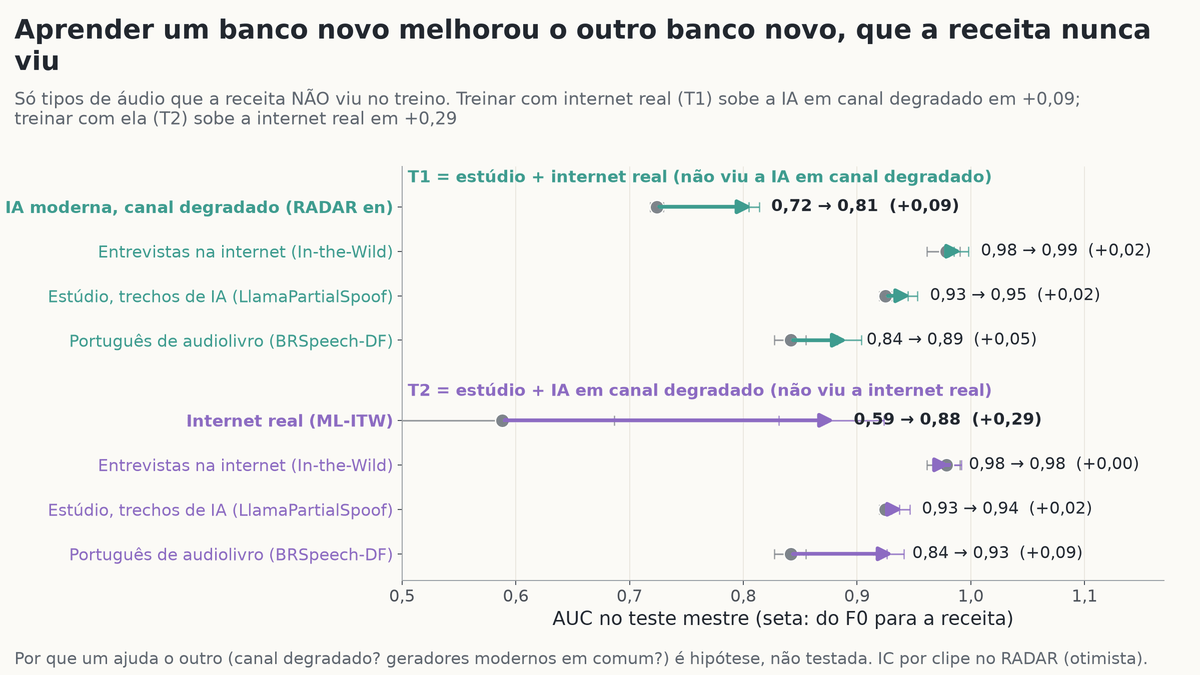

In [46]:
slide("f_04_sinal_de_generalizacao")

**O que olhar:** as duas setas grandes, em negrito: RADAR en com a T1 e internet real com a T2. As demais (entrevistas, estúdio, português) mudam pouco ou sobem um pouco.

**O que concluir:** aprender um tipo de áudio "difícil" ajudou no outro, que a receita não viu. **Por que** isso acontece (os dois têm canal degradado? os dois têm geradores modernos?) **é hipótese, não testada**.

### 13.4 O bloco inglês

Para separar o efeito do idioma, o protocolo pede um recorte só em inglês. Na T3: RADAR en 0,964 (natural) e 0,964 (durações pareadas); internet real só em inglês 0,943 (IC95 0,899 a 0,974; **indício**: 18 / 26 locutores real / IA); entrevistas 0,986; fala lida com trechos de IA 0,942. **Pareado × natural é igual**: a duração não explica o RADAR. Por faixa de duração no RADAR en, os clipes curtos continuam os mais difíceis (T3: < 2 s 0,945; ≥ 6 s 0,971).

### Figura f_06 · O bloco inglês por receita

**O que ela mostra:** uma tabela colorida: linhas = recortes em inglês, colunas = receitas, célula = AUC (mais escuro = maior). Células hachuradas = tipo de áudio visto no treino daquela receita. A coluna da T3 está contornada.

*O código abaixo só exibe a figura gerada por `scripts/v7_slides.py` (slide em alta: `results/slides/f_06_ingles.png`).*

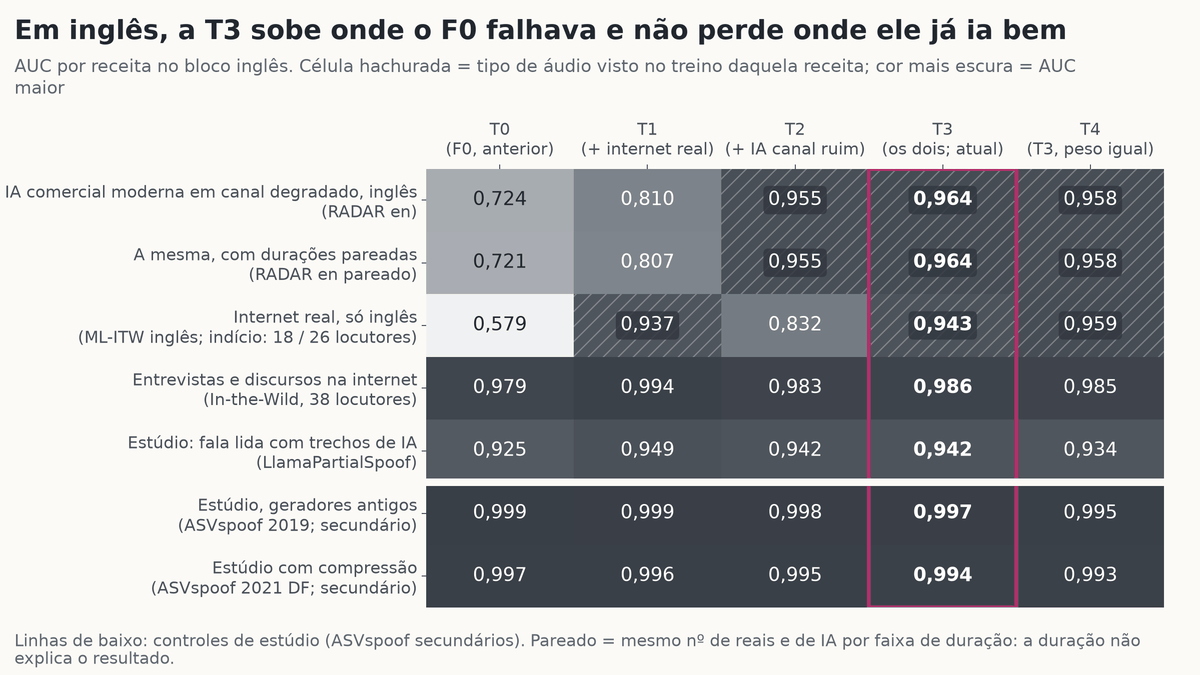

In [47]:
slide("f_06_ingles")

**O que olhar:** a linha da internet real em inglês sobe de 0,58 (T0) para 0,94 a 0,96 nas receitas que a viram; as linhas de baixo (estúdio) quase não mudam.

**O que concluir:** em inglês, a T3 sobe onde o F0 falhava e não perde onde ele já ia bem; a linha da internet real em inglês tem poucos locutores (indício).

### 13.5 Controles de estúdio (esquecimento)

Aprender a internet poderia fazer o sistema **esquecer** o estúdio. Não aconteceu: a maior queda de AUC da T3 nos controles foi **−0,003**. O português de audiolivro (BRSpeech-DF) até **sobe**: 0,842 → 0,956. No português real só com reais (CORAA), a % de reais acusados cai de 15,9% (F0, regra A') para 11,1% (T3, regra M).

### Figura f_05 · O estúdio não piorou

**O que ela mostra:** a AUC do F0 e da T3 nos testes antigos de estúdio e português (nenhum deles entrou no treino) e, à direita, a % de reais do CORAA acusados como IA.

*O código abaixo só exibe a figura gerada por `scripts/v7_slides.py` (slide em alta: `results/slides/f_05_estudio_nao_piorou.png`).*

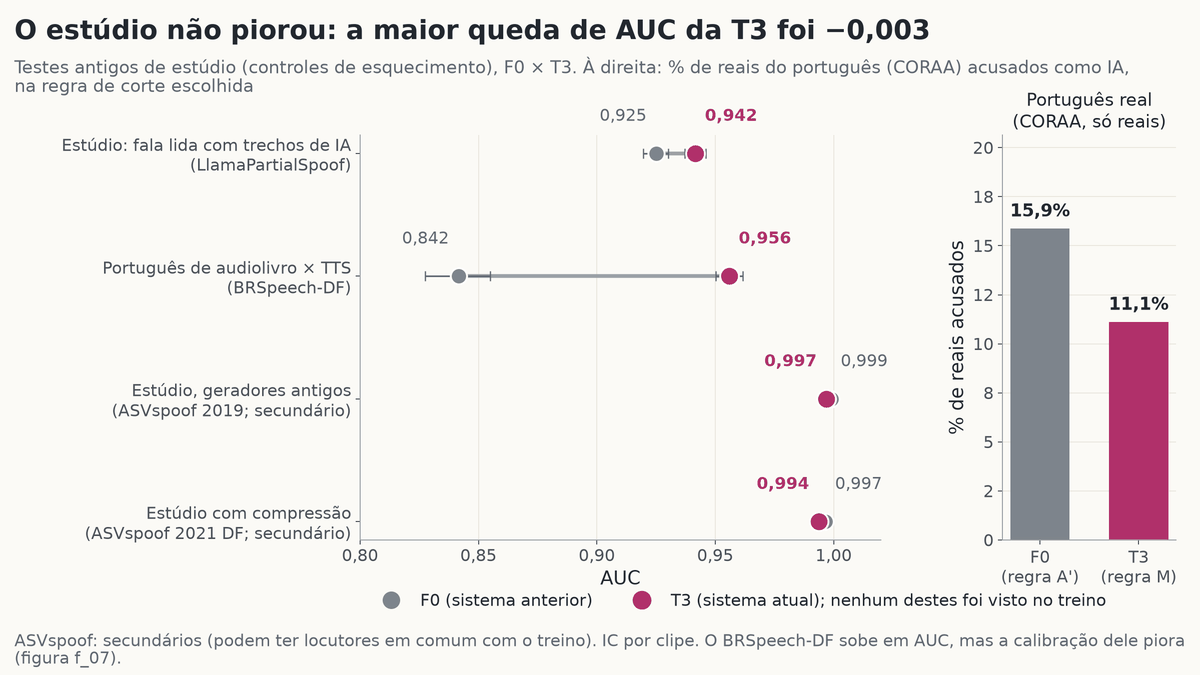

In [48]:
slide("f_05_estudio_nao_piorou")

**O que olhar:** os pontos de estúdio quase não se mexem; o português de audiolivro anda para a direita; a barra do CORAA diminui.

**O que concluir:** não há esquecimento em AUC. Mas a calibração do português piora (seção 15): ordenar bem não é o mesmo que cortar bem.

### 13.6 Atalho por metadados

Repetimos a auditoria de atalho com o desenho da v7: uma regressão logística que só vê **duração, silêncio, volume, pico e tamanho do arquivo**, treinada no lado de treino de cada banco novo. No teste mestre, ela chega a **0,569** na internet real e **0,595** no RADAR en (com validação cruzada dentro do teste mestre: 0,647 e 0,624). Nenhuma passa de 0,7, e as receitas treinadas ficam em 0,94 a 0,96: **os ganhos não são explicados por esses metadados**. Mas, no T0 da internet real (0,588), os metadados já chegavam praticamente ao nível do modelo.

In [49]:
display(pd.read_csv(R / "v7_atalho.csv").drop(columns=["atributos"]).round(3))

,fonte,como,medido em,n,AUC metadados,AUC T0,AUC T1,AUC T2,AUC T3,AUC T4,"marca (> 0,7)"
0,ml_itw,treinado no lado de treino,validação,4748,0.532,0.769,0.945,0.893,0.960,0.961,sem sinal forte de atalho
1,ml_itw,treinado no lado de treino,teste mestre,9125,0.569,0.588,0.923,0.882,0.939,0.948,sem sinal forte de atalho
2,ml_itw,validação cruzada 5 partes dentro do teste mestre,teste mestre,9125,0.647,0.588,0.923,0.882,0.939,0.948,sem sinal forte de atalho
3,radar_eval,treinado no lado de treino,validação,23649,0.611,0.779,0.832,0.972,0.973,0.968,sem sinal forte de atalho
4,radar_eval,treinado no lado de treino,teste mestre,32923,0.595,0.724,0.810,0.955,0.964,0.958,sem sinal forte de atalho
5,radar_eval,treinado no lado de treino,teste mestre pareado,28582,0.591,0.721,0.807,0.955,0.964,0.958,sem sinal forte de atalho
6,radar_eval,validação cruzada 5 partes dentro do teste mestre,teste mestre,32923,0.624,0.724,0.810,0.955,0.964,0.958,sem sinal forte de atalho


### 13.7 Pós-hoc: a internet real dentro do mesmo locutor

**Feito depois de ver o teste** (não muda receita, regra nem escolha). O teste mestre da internet real tem 55 locutores de uma classe só; um modelo poderia acertar "quem é o locutor" em vez de "real × IA". Dois recortes:
- **(a) só locutores com as duas classes:** T0 0,591 → T3 **0,920** (IC95 0,853 a 0,964).
- **(b) AUC dentro de cada locutor** (≥ 5 clipes por classe; 32 locutores), média entre locutores: T0 0,734 → T3 **0,912** (mediana 0,818 → 0,979).

O ganho **se mantém dentro do mesmo locutor**: não é efeito de separar locutores de uma classe só.

In [50]:
ph = pd.read_csv(R / "v7_poshoc.csv")
display(ph[["análise", "receita", "locutores_real", "locutores_falso", "AUC", "AUC IC2.5", "AUC IC97.5",
            "AUC mediana entre locutores", "AUC min", "AUC max"]].round(3))

,análise,receita,locutores_real,locutores_falso,AUC,AUC IC2.5,AUC IC97.5,AUC mediana entre locutores,AUC min,AUC max
0,"(a) ML-ITW teste, só locutores com as duas classes",T0,36,36,0.591,0.460,0.734,NaN,NaN,NaN
1,"(b) ML-ITW teste, AUC dentro de cada locutor (>= 5 clipes por classe), média...",T0,32,32,0.734,NaN,NaN,0.818,0.058,1.0
2,"(a) ML-ITW teste, só locutores com as duas classes",T1,36,36,0.919,0.851,0.967,NaN,NaN,NaN
3,"(b) ML-ITW teste, AUC dentro de cada locutor (>= 5 clipes por classe), média...",T1,32,32,0.897,NaN,NaN,0.978,0.436,1.0
4,"(a) ML-ITW teste, só locutores com as duas classes",T2,36,36,0.860,0.777,0.922,NaN,NaN,NaN
5,"(b) ML-ITW teste, AUC dentro de cada locutor (>= 5 clipes por classe), média...",T2,32,32,0.866,NaN,NaN,0.918,0.500,1.0
6,"(a) ML-ITW teste, só locutores com as duas classes",T3,36,36,0.920,0.853,0.964,NaN,NaN,NaN
7,"(b) ML-ITW teste, AUC dentro de cada locutor (>= 5 clipes por classe), média...",T3,32,32,0.912,NaN,NaN,0.979,0.500,1.0
8,"(a) ML-ITW teste, só locutores com as duas classes",T4,36,36,0.928,0.868,0.970,NaN,NaN,NaN
9,"(b) ML-ITW teste, AUC dentro de cada locutor (>= 5 clipes por classe), média...",T4,32,32,0.917,NaN,NaN,0.986,0.500,1.0


### 13.8 O português, à parte

O protocolo reporta o português **à parte, como indício**:
- **Internet real em português** (ML-ITW, 7 / 8 locutores; nenhum áudio em português entrou no treino): AUC 0,692 (T0) → **0,852** (T3), IC95 0,717 a 0,953: largo demais para concluir. Na regra escolhida (M), a T3 pega só **51,9%** dos falsos em português (acusa 4,7% dos reais).
- **Português de audiolivro** (BRSpeech-DF, controle): AUC alta (0,956 na T3), mas **75,3% dos reais são acusados** no corte da regra M (62,3% no F0, regra A'). A ordem está boa; a escala da nota, não (seção 15).
- **Português real só com reais** (CORAA): 11,1% de reais acusados na T3 (regra M).

**Conclusão da seção 13:** a T3, escolhida pela validação, sobe a média do teste mestre de 0,764 para 0,963; os ganhos estão onde o tipo de áudio foi visto, o que nunca foi visto não piora, um banco novo ajuda o outro, e os metadados não explicam os ganhos. O português continua sem resposta firme, e o corte é o novo ponto fraco.

## 14. O que não dá para afirmar

- **O teste mestre não é virgem.** O F0 já tinha sido avaliado nesses mesmos clipes (bancos inteiros, 13/11), e as entrevistas da internet (In-the-Wild) foram vistas da v4 à v6. Nada da v7 foi escolhido olhando o teste, mas quem desenhou a v7 já conhecia o resultado agregado do F0. **Só clones próprios, gravados depois, seriam um teste intocado.**
- **O RADAR en mede idioma novo, não gerador novo.** No RADAR, os geradores e o canal do teste (inglês) são os mesmos do treino (chinês e japonês). O "0,96" diz que o sistema aprendeu os falsos do RADAR e os reconhece em outro idioma, não que ele pega geradores que nunca viu.
- **A internet real tem poucos locutores por classe.** No teste mestre inteiro: 56 / 73 locutores (real / IA); **só em inglês: 18 / 26**, abaixo de 30 por classe: **indício, não estimativa**. Todas as plataformas também ficam abaixo de 30.
- **O português de audiolivro é limpo.** Os reais do BRSpeech-DF vêm de audiolivros (LibriVox, 10 locutores): é fala lida e limpa, longe de uma ligação ou de um áudio de aplicativo. O português "de internet" tem só 7 / 8 locutores.
- **O corte não se transfere entre ambientes.** Com o mesmo corte, a T3 acusa de 1% a 75% dos reais, conforme o banco (seção 15).
- **Nada sobre ligações ou WhatsApp reais.** Nenhum banco é ligação telefônica real: o RADAR **simula** o canal, e o ML-ITW são vídeos de redes sociais.
- **A causa do ganho cruzado é hipótese.** Por que treinar com o RADAR ajuda a internet real (e vice-versa)? Pode ser o canal degradado, os geradores modernos em comum, ou outra coisa. **Não foi testado.**
- **Uma única divisão e uma única regressão por receita** (seed 42): a variação de sorteio do treino não está medida. As entrevistas no teste mestre são a amostra de 10.000 clipes da v4, não os 21.165 do `test_final`.
- **Estes números não valem como resultado do desafio RADAR**: o desafio pede para não treinar com o eval, e nós treinamos com parte dele (zh, zh-tw, ja). Também não são comparáveis aos da avaliação dos bancos inteiros (seção 10). A licença do ML-ITW não está declarada.

**Limitações que vêm da v4 e continuam valendo** (texto da versão anterior deste documento):

- **Os bancos de teste foram vistos três vezes** (v4, v5 e v6). Os números do F0 são os da v4 original (o primeiro olhar), mas os bancos já não são "nunca vistos".
- **dev_shift pequeno:** 16 locutores; é ele que define o corte B e que decidiu entre versões.
- **Uma única amostra de treino** (40.000 áudios) e uma regressão: o bootstrap do teste não mede o acaso do treino.
- **O português é o ponto fraco:** BRSpeech-DF com acurácia balanceada ~0,68 no corte A (0,77 no B); áudios de menos de 2 s quase em cara ou coroa (figura 11); CORAA com 16,7% de reais acusados no corte A.
- **Os dois cortes trocam um erro pelo outro:** A acusa reais de internet e de português; B deixa passar fakes parciais e de codec (figura 10).
- **A decisão de voltar ao F0 veio depois de ver o teste da v6.** O F0 em si foi escolhido pela validação **antes de qualquer teste** (pré-registro da v4), por isso os números do F0 são os da v4 original; mas preferir o F0 ao F2 agora é uma escolha informada pelo teste. (Essa recomendação foi seguida: seção 10.)
- **Explicações não provadas:** por que o modelo pronto funciona (seção 4), por que as camadas do meio são as melhores, por que MLP e CNN não ganham, por que o WavLM perdeu e por que o F2 piorou são hipóteses.

### Figura f_09 · O que o teste mostra e o que não mostra

**O que ela mostra:** um quadro com duas colunas: à esquerda, o que os números da v7 sustentam; à direita, o que eles ainda não sustentam.

*O código abaixo só exibe a figura gerada por `scripts/v7_slides.py` (slide em alta: `results/slides/f_09_o_que_nao_afirmamos.png`).*

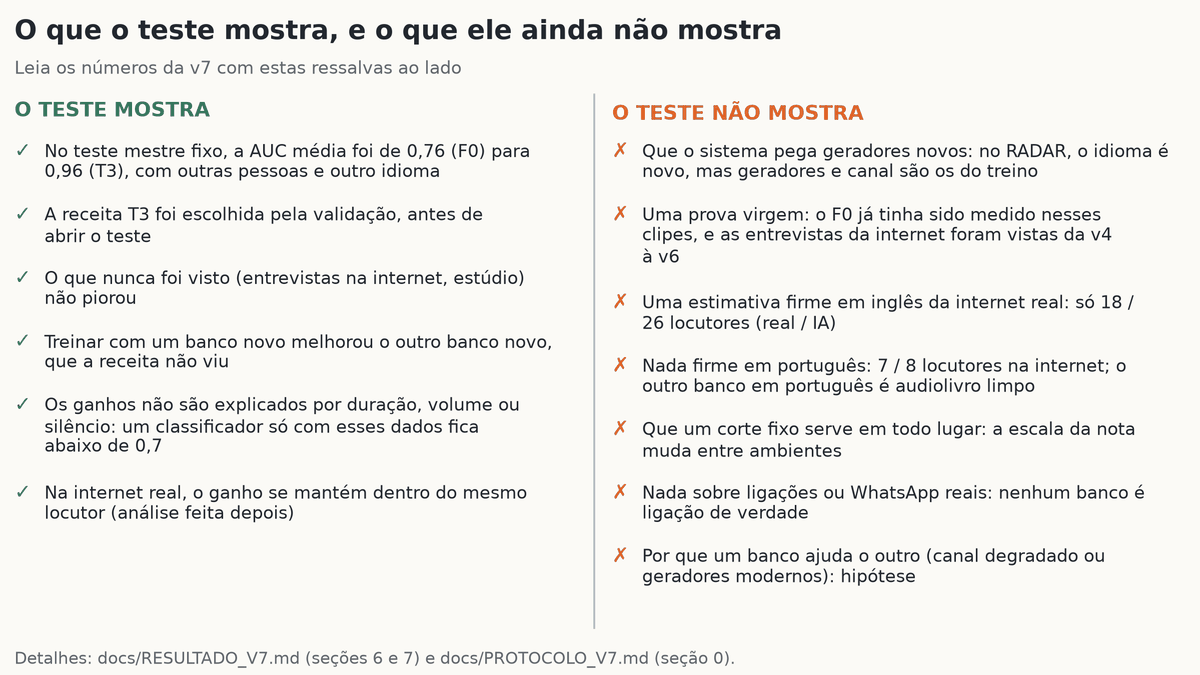

In [51]:
slide("f_09_o_que_nao_afirmamos")

**O que olhar:** cada item da direita é uma ressalva que deve acompanhar qualquer número da v7 apresentado.

**O que concluir:** a v7 é um avanço medido com cuidado, não uma prova de que o sistema funciona em golpes reais.

## 15. Cortes: decisão em aberto

A AUC não depende do corte, mas um sistema de verdade precisa de um. O protocolo calculou **três regras de corte, só com a validação**, e escolheu entre elas por validação cruzada deixando uma fonte de fora (maior acurácia balanceada média):

| regra (calculada na validação da T3) | corte (logit) | acurácia balanceada média, deixando uma fonte de fora |
|:--|:--|:--|
| A' = ponto de EER da validação agrupada | 0,027 | 0,9325 |
| M = mediana dos pontos de EER de cada fonte | 0,233 | 0,9331 |
| F5 = no máximo 5% de reais acusados em cada fonte (mediana entre fontes) | 0,211 | 0,9318 |

As três **empatam na prática** (diferença de 0,0013); a regra M ficou marcada pelo protocolo quase por sorteio. E o problema maior não é qual das três: é que **a escala da nota muda entre ambientes**. A mesma nota quer dizer coisas diferentes no estúdio, na internet e no português, então qualquer corte único acusa muitos reais em algum lugar.

**A escolha da regra (e se haverá um corte por ambiente) para o sistema final fica em aberto, e será decidida depois, só pela validação.** Este documento **não escolhe**: mostra as três.

### Figura f_07 · A escala da nota e os três cortes

**O que ela mostra:** à esquerda, a nota média dos reais (azul) e dos áudios de IA (laranja) em cada fonte, na T3, com as três linhas de corte da validação; à direita, a % de reais acusados (FPR, azul) e de IA detectada (TPR, laranja) em cada regra (quadrado = A', círculo = M, triângulo = F5). Faixa bege = português.

*O código abaixo só exibe a figura gerada por `scripts/v7_slides.py` (slide em alta: `results/slides/f_07_cortes_e_calibracao.png`).*

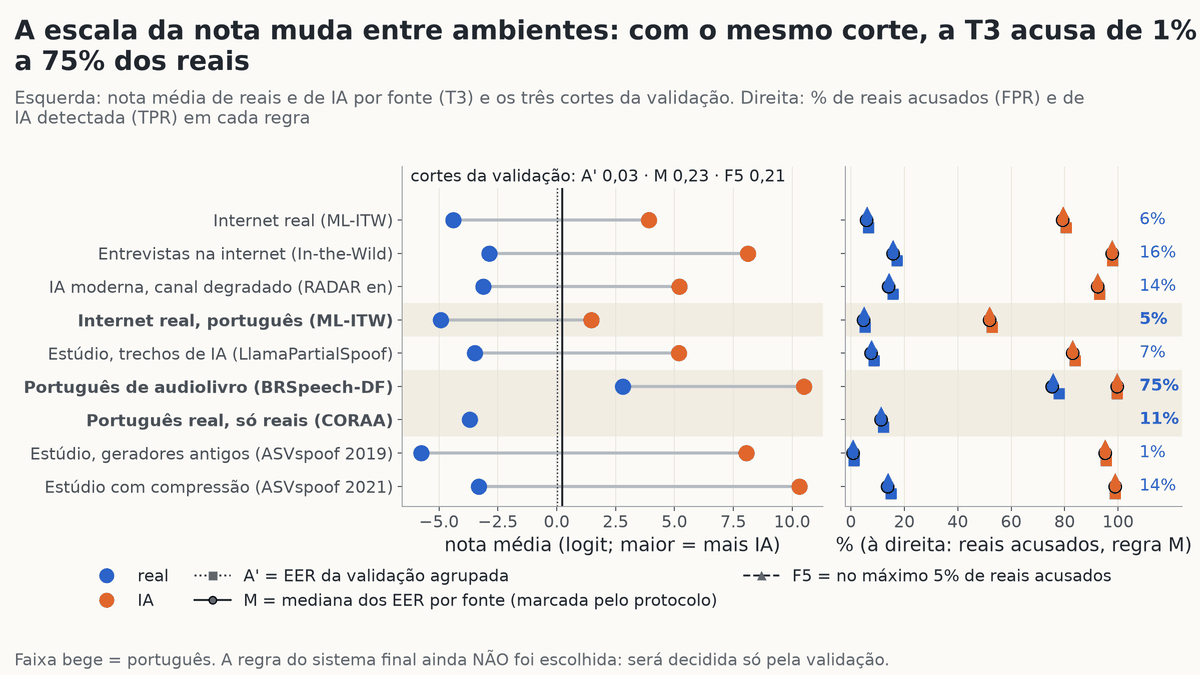

In [52]:
slide("f_07_cortes_e_calibracao")

**O que olhar:** no português de audiolivro, até a nota média dos **reais** fica acima de todos os cortes (2,8), e 75% dos reais são acusados; na internet real em português, a média dos falsos fica perto do corte e só ~52% são pegos; as três regras dão pontos quase iguais em todas as fontes.

**O que concluir:** o corte é o novo ponto fraco: as três regras empatam e nenhuma serve para todos os ambientes. Um corte por ambiente (ou calibrar a nota por ambiente) é o próximo passo natural, a decidir só pela validação.

**O que faz:** mostra, para a T3, os três cortes da validação e, por fonte do teste mestre e dos controles, o TPR e o FPR em cada regra e a nota média de reais e de IA. **Por quê:** os números da figura, sem escolher regra nenhuma.

In [53]:
esc = ler(R / "v7_escolha.json")["por_receita"]["T3"]
display(Markdown(f"**Cortes da T3 (logit), calculados na validação:** " +
                 ", ".join(f"{k} = {v:.3f}" for k, v in esc["cortes"].items()) +
                 f". Acurácia balanceada média (deixando uma fonte de fora): " +
                 ", ".join(f"{k} = {v:.4f}" for k, v in esc["loso"].items()) + "."))
tm = pd.read_csv(R / "v7_teste_mestre.csv")
t3 = tm[tm.receita == "T3"].set_index("recorte")
display(t3[["papel", "n_real", "n_falso", "nota média real", "nota média falso", "TPR A'", "FPR A'", "TPR M", "FPR M",
            "TPR F5", "FPR F5"]].round(3))

**Cortes da T3 (logit), calculados na validação:** A' = 0.027, M = 0.233, F5 = 0.211. Acurácia balanceada média (deixando uma fonte de fora): A' = 0.9325, M = 0.9331, F5 = 0.9318.

,papel,n_real,n_falso,nota média real,nota média falso,TPR A',FPR A',TPR M,FPR M,TPR F5,FPR F5
recorte,,,,,,,,,,,
ml_itw,principal,6612,2513,-4.397,3.921,0.805,0.065,0.792,0.058,0.793,0.059
in_the_wild,principal,5000,5000,-2.863,8.113,0.979,0.172,0.978,0.156,0.978,0.157
radar_en,principal,15000,17923,-3.128,5.206,0.930,0.157,0.922,0.140,0.923,0.141
radar_en_pareado,inglês,14291,14291,-3.126,5.222,0.929,0.157,0.922,0.140,0.922,0.142
ml_itw_ingles,inglês,1984,586,-4.596,2.034,0.730,0.045,0.708,0.038,0.710,0.040
ml_itw_portugues,à parte (indício),911,108,-4.919,1.474,0.528,0.052,0.519,0.047,0.519,0.048
llamapartialspoof,controle,5000,5000,-3.490,5.186,0.838,0.085,0.829,0.075,0.830,0.076
brspeech_df,controle,1320,5000,2.799,10.492,0.996,0.779,0.996,0.753,0.996,0.757
coraa,controle,5000,0,-3.686,NaN,NaN,0.122,NaN,0.111,NaN,0.112


## 16. Próximos passos (não executados)

1. **Corte por ambiente.** Calibrar o corte (ou a nota) separadamente para estúdio, internet e telefone/aplicativo, escolhendo só pela validação. É o problema mais claro que a v7 deixou (seção 15).
2. **Português no treino.** Reais e falsos em português, de bancos que não estão nos testes, e um conjunto de decisão em português, para que as escolhas deixem de ser cegas para o idioma do uso final.
3. **Clones próprios como teste intocado.** Gravar e clonar vozes do grupo (com consentimento), **depois** de fechar o sistema, e avaliar uma única vez: é o único teste realmente virgem que temos como fazer (a pasta `data/raw/clones_proprios` ainda não existe).
4. **O contexto de golpe.** Áudio curto, comprimido, de telefone ou de aplicativo de mensagem; definir o corte pelo custo de cada erro nesse uso (acusar um parente de verdade × deixar passar um golpe).
5. **O sistema final.** Um único pipeline (áudio → XLS-R → regressão da T3 → nota → decisão) empacotado para o grupo, com os pesos de `results/v7_t3_coeficientes.npz`, o corte decidido pela validação e o domínio de uso escrito junto.